# Group Members

| Name | Roll Number |
|---|---|
| Zahra Qaisar | 26L-8024 |
| Kainat Bashir | 26L-8026 |

# Carbon-Aware Scheduling: Part 2 (Model Training, Tuning and Evaluation)

This notebook continues from Part 1. It trains and compares models, tunes them,
evaluates them on unseen 2025 data, answers RQ1 to RQ4, and builds the final prediction pipeline.

## Step 1: Load the Part 1 outputs

In [1]:
import os

# checking /kaggle/input
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/zahraqaisar/dataset-for-p2/master_clean.csv
/kaggle/input/datasets/zahraqaisar/dataset-for-p2/selected_features.csv


## Step 2: Settings and load the data

In [2]:
# Install the holidays package - need for UK holidays
!pip install holidays -q

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")   # hide warning messages
sns.set_theme(style="whitegrid")    # nice plot style

#  SETTINGS

SEED = 42                           # fixed number, so results are the same every run
HORIZON = 48                        # 48 half-hours = 24 hours
WINDOW = 6                          # 6 half-hours = 3 hours
N_WIN = HORIZON - WINDOW + 1        # 43 possible 3-hour windows in one day
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2022, 2023], 2024, 2025
UNIT = "gCO2/kWh"

# 3 weather places and the weather columns we use
LOCATIONS = ["london", "scotland", "east_coast"]
MODEL_WX = ["wind_speed_10m", "cloud_cover", "temperature_2m", "shortwave_radiation"]
FUELS = ["biomass", "coal", "imports", "gas", "nuclear", "hydro", "solar", "wind"]

# The full list of 30-minute times from 2022 to 2025
FULL = pd.date_range("2022-01-01", "2025-12-31 23:30", freq="30min", tz="UTC")

# Load the two files from Part 1 
FOLDER = "/kaggle/input/datasets/zahraqaisar/dataset-for-p2"
if not os.path.exists(FOLDER):
    FOLDER = "data"        # used when the notebook runs from the GitHub repository

# Output folder used by this notebook (it exists on Kaggle)
if not os.path.exists("/kaggle/working"):
    try:
        os.makedirs("/kaggle/working")
    except Exception:
        print("Could not create /kaggle/working. Create this folder by hand, or run the notebook on Kaggle.")

df = pd.read_csv(f"{FOLDER}/master_clean.csv")
df["time"] = pd.to_datetime(df["time"], utc=True)   # make the time column a real date
df = df.set_index("time")                           # use time as the row name

# Check that we have every 30-minute slot
assert len(df) == len(FULL) and (df.index == FULL).all(), "Some time slots are missing!"

# The list of selected feature names from Part 1
SELECTED = pd.read_csv(f"{FOLDER}/selected_features.csv")["feature"].tolist()

print("Data shape:", df.shape)
print("First time:", df.index[0], "| Last time:", df.index[-1])
print("Missing actual values:", int(df["actual"].isna().sum()))
print("Missing NESO forecast values:", int(df["forecast_neso"].isna().sum()))
print("Selected features:", len(SELECTED))
print()
print("Columns:", list(df.columns))

Data shape: (70128, 25)
First time: 2022-01-01 00:00:00+00:00 | Last time: 2025-12-31 23:30:00+00:00
Missing actual values: 183
Missing NESO forecast values: 165
Selected features: 68

Columns: ['forecast_neso', 'actual', 'biomass', 'coal', 'imports', 'gas', 'nuclear', 'hydro', 'solar', 'wind', 'wind_speed_10m_east_coast', 'wind_speed_10m_london', 'wind_speed_10m_scotland', 'wind_direction_10m_east_coast', 'wind_direction_10m_london', 'wind_direction_10m_scotland', 'cloud_cover_east_coast', 'cloud_cover_london', 'cloud_cover_scotland', 'temperature_2m_east_coast', 'temperature_2m_london', 'temperature_2m_scotland', 'shortwave_radiation_east_coast', 'shortwave_radiation_london', 'shortwave_radiation_scotland']


## Step 2b: Saving pictures and the pipeline diagram

From now on, every picture in this notebook is also saved as a PNG file in the "figures" folder (for GitHub).
Below is a diagram of the full Machine Learning pipeline of this project.

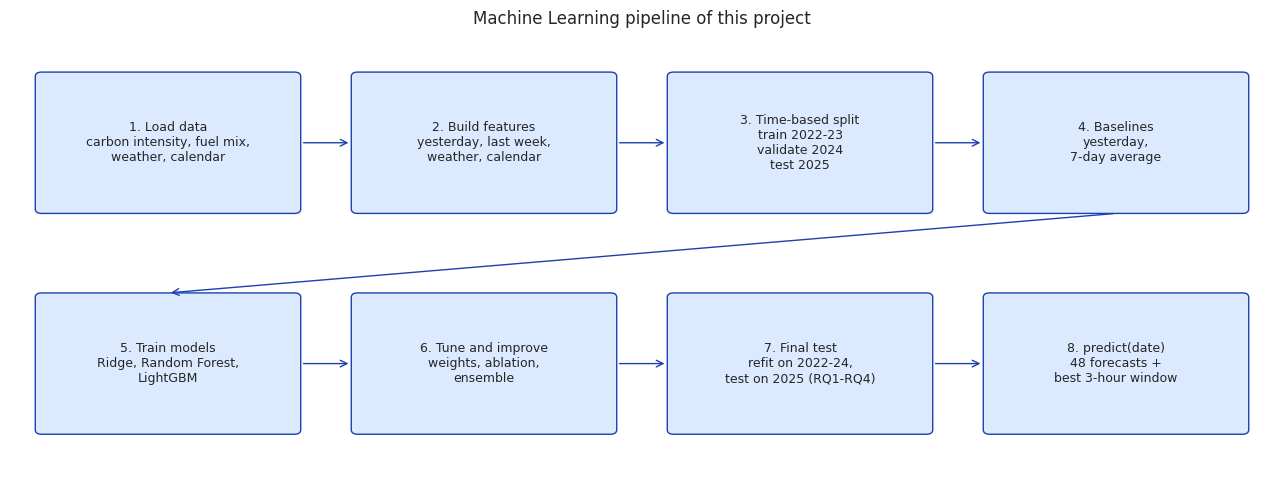

Pipeline steps:
  1. Load data carbon intensity, fuel mix, weather, calendar
  2. Build features yesterday, last week, weather, calendar
  3. Time-based split train 2022-23 validate 2024 test 2025
  4. Baselines yesterday, 7-day average
  5. Train models Ridge, Random Forest, LightGBM
  6. Tune and improve weights, ablation, ensemble
  7. Final test refit on 2022-24, test on 2025 (RQ1-RQ4)
  8. predict(date) 48 forecasts + best 3-hour window

Pictures are saved in: /kaggle/working/figures
Saved so far: ['01_machine_learning_pipeline_of_this_project.png']


In [3]:
import os, re
from matplotlib.patches import FancyBboxPatch

# Folder for saving pictures
FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# saving picture as a PNG file
if not hasattr(plt, "_original_show"):
    plt._original_show = plt.show          # keep the real show function (only once)
FIG_COUNT = [0]                            # counts how many pictures we saved

def show_and_save(*args, **kwargs):
    fig = plt.gcf()                        # the picture we just drew
    title = fig.axes[0].get_title() if fig.axes else ""
    name = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:50] or "figure"   # simple file name from the title
    FIG_COUNT[0] += 1
    fig.savefig(f"{FIG_DIR}/{FIG_COUNT[0]:02d}_{name}.png", dpi=150, bbox_inches="tight")
    plt._original_show(*args, **kwargs)

plt.show = show_and_save

#  Pipeline diagram 
steps = [
    "1. Load data\ncarbon intensity, fuel mix,\nweather, calendar",
    "2. Build features\nyesterday, last week,\nweather, calendar",
    "3. Time-based split\ntrain 2022-23\nvalidate 2024\ntest 2025",
    "4. Baselines\nyesterday,\n7-day average",
    "5. Train models\nRidge, Random Forest,\nLightGBM",
    "6. Tune and improve\nweights, ablation,\nensemble",
    "7. Final test\nrefit on 2022-24,\ntest on 2025 (RQ1-RQ4)",
    "8. predict(date)\n48 forecasts +\nbest 3-hour window",
]

fig, ax = plt.subplots(figsize=(13, 5))
ax.set_xlim(0, 4)
ax.set_ylim(0, 2)
ax.axis("off")
ax.set_title("Machine Learning pipeline of this project")

centers = []
for i, text in enumerate(steps):
    cx = i % 4 + 0.5                       # column position
    cy = 1.5 if i < 4 else 0.5             # first row on top, second row below
    centers.append((cx, cy))
    box = FancyBboxPatch((cx - 0.4, cy - 0.3), 0.8, 0.6, boxstyle="round,pad=0.02",
                         facecolor="#dbeafe", edgecolor="#1e40af")
    ax.add_patch(box)
    ax.text(cx, cy, text, ha="center", va="center", fontsize=9)

# Arrows from each box to the next box
for i in range(len(steps) - 1):
    (x1, y1), (x2, y2) = centers[i], centers[i + 1]
    if y1 == y2:                           # same row: arrow goes right
        start, end = (x1 + 0.42, y1), (x2 - 0.42, y2)
    else:                                  # new row: arrow goes from the end of row 1 to the start of row 2
        start, end = (x1, y1 - 0.32), (x2, y2 + 0.32)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="#1e40af"))

plt.tight_layout()
plt.show()

# Same diagram as text
print("Pipeline steps:")
for s in steps:
    print(" ", s.replace("\n", " "))
print("\nPictures are saved in:", FIG_DIR)
print("Saved so far:", sorted(os.listdir(FIG_DIR)))

## Step 3: Build features (X), targets (Y), baselines and train/validation/test masks

In [4]:
import holidays
UK_HOLIDAYS = holidays.UK(subdiv="England", years=range(2022, 2026))

# Turn a half-hourly column into a table: 1 row per day, 48 columns (one per half-hour)

def to_day_matrix(s):
    days = pd.DatetimeIndex(s.index[::HORIZON], name="date")
    return pd.DataFrame(s.to_numpy().reshape(-1, HORIZON), index=days)

# Build the input features (X). One row = one day we want to predict.

def build_features(df):
    Y = to_day_matrix(df["actual"])
    days = Y.index
    day_of = df.index.floor("D")                 # the date of every half-hour row

    # Past carbon intensity: same time yesterday, same time 7 days ago, 7-day average
    
    lag1 = Y.shift(1)
    lag7 = Y.shift(7)
    avg7 = pd.DataFrame(np.mean([Y.shift(k).to_numpy() for k in range(1, 8)], axis=0), index=days)

    # A few summary numbers of yesterday
    
    stats = pd.DataFrame({"ci_prev_mean": lag1.mean(axis=1), "ci_prev_min": lag1.min(axis=1),
                          "ci_prev_max": lag1.max(axis=1), "ci_prev_last": lag1[HORIZON - 1]})

    parts = [lag1.add_prefix("ci_lag1d_s"), lag7.add_prefix("ci_lag7d_s"),
             avg7.add_prefix("ci_avg7d_s"), stats]

    # Weather column names (4 weather types x 3 places)
    wcols = [f"{v}_{loc}" for v in MODEL_WX for loc in LOCATIONS]

    # Yesterday's average fuel mix (shift(1) means we only use the past)
    parts.append(df[FUELS].groupby(day_of).mean().shift(1).add_prefix("gen_prev_"))

    # Yesterday's average weather
    parts.append(df[wcols].groupby(day_of).mean().shift(1).add_prefix("wx_prev_"))

    # Target day weather, in four 6-hour blocks
    wt = df[wcols].groupby([day_of, df.index.hour // 6]).mean().unstack()
    wt.columns = [f"wx_tgt_{c}_b{b}" for c, b in wt.columns]
    parts.append(wt)

    # Calendar features
    cal = pd.DataFrame(index=days)
    cal["dow"] = days.dayofweek                       # day of week
    cal["month"] = days.month
    cal["is_weekend"] = (days.dayofweek >= 5).astype(int)
    cal["doy_sin"] = np.sin(2 * np.pi * days.dayofyear / 365.25)   # season (sine)
    cal["doy_cos"] = np.cos(2 * np.pi * days.dayofyear / 365.25)   # season (cosine)
    cal["is_holiday"] = [int(d.date() in UK_HOLIDAYS) for d in days]
    parts.append(cal)

    X = pd.concat(parts, axis=1)
    X.index = days
    return X

#  Build everything 
X = build_features(df)                       # input features
Y = to_day_matrix(df["actual"])              # real values we want to predict
NESO = to_day_matrix(df["forecast_neso"])    # NESO forecast (only for comparison)

# TWO SIMPLE BASELINES
Y_yday = Y.shift(1)                          # baseline 1: same time yesterday
Y_wk7 = pd.DataFrame(np.mean([Y.shift(k).to_numpy() for k in range(1, 8)], axis=0),
                     index=Y.index)          # baseline 2: average of last 7 days

#  Masks: which days can we use? 
ok = X.notna().all(axis=1) & Y.notna().all(axis=1)   # days with no missing values
year = pd.Series(X.index.year, index=X.index)

tr = ok & year.isin(TRAIN_YEARS)     # train days (2022-2023)
va = ok & (year == VAL_YEAR)         # validation days (2024)
te = ok & (year == TEST_YEAR)        # test days (2025)
common = ok & NESO.notna().all(axis=1)   # days where NESO forecast also exists

ALL = list(X.columns)                # all feature names

print("X shape:", X.shape, "| Y shape:", Y.shape)
print("ALL features:", len(ALL), "| SELECTED features:", len(SELECTED))
print("Train / validation / test days:", int(tr.sum()), int(va.sum()), int(te.sum()))
print("Common test days (2025):", int((common & (year == TEST_YEAR)).sum()))
print("Holidays found in X:", int(X["is_holiday"].sum()))
print("All SELECTED names exist in X:", all(c in X.columns for c in SELECTED))

X shape: (1461, 222) | Y shape: (1461, 48)
ALL features: 222 | SELECTED features: 68
Train / validation / test days: 675 357 365
Common test days (2025): 361
Holidays found in X: 38
All SELECTED names exist in X: True


**Observation.** The data has 1,461 days (2022-2025). Each day has 222 input features and 48 targets (one for every half-hour). After removing days with missing values we have 675 training days (2022-2023), 357 validation days (2024) and 365 test days (2025). To compare fairly with the NESO forecast, we only use days where the NESO forecast also exists: 357 validation days and 361 test days. All 68 SELECTED feature names from Part 1 exist in the data.

## Step 3b: Look at the data and the split

Before training, we look at how carbon intensity changed from 2022 to 2025 and how we split the years.
Carbon intensity went down over the years, so the model trained on old years must work on newer years.
This is called drift, and it is one of the main difficulties of this project.

Carbon intensity by year:


,mean,std,min,max,missing
time,,,,,
2022,182.5,65.1,39.0,322.0,51
2023,152.2,62.6,26.0,309.0,101
2024,125.1,59.9,14.0,303.0,31
2025,129.2,57.6,24.0,293.0,0


,part,days used,model
0,Train (2022-2023),675,learns from these
1,Validation (2024),357,used to tune settings
2,Test (2025),365,used only at the end


Monthly average carbon intensity (rows = month, columns = year):


time,2022,2023,2024,2025
month,,,,
1,185.0,143.0,166.0,168.0
2,127.0,166.0,133.0,148.0
3,186.0,158.0,128.0,146.0
4,181.0,161.0,93.0,133.0
5,183.0,148.0,124.0,106.0
6,183.0,167.0,99.0,99.0
7,210.0,143.0,115.0,129.0
8,221.0,161.0,84.0,124.0
9,210.0,158.0,122.0,112.0


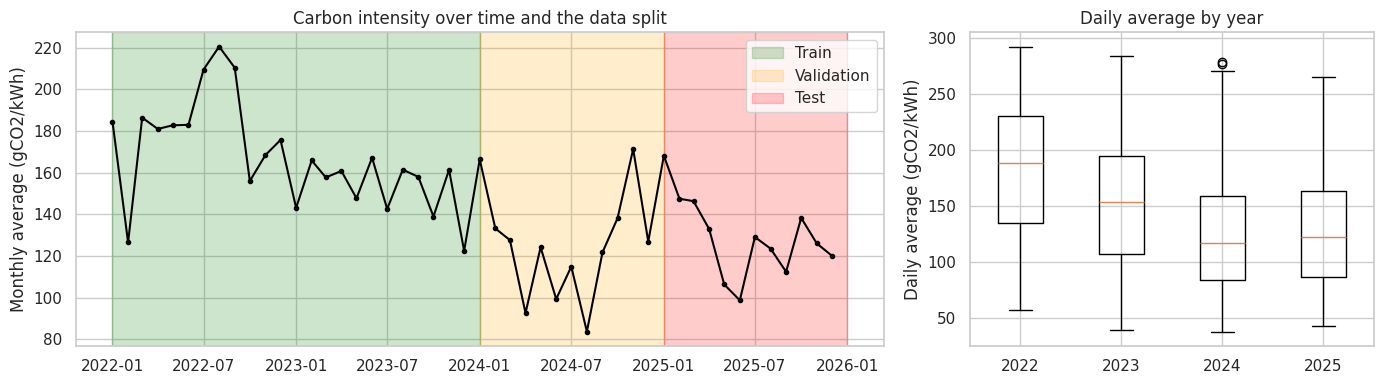

Average carbon intensity fell from 182.5 (2022) to 129.2 (2025): a drop of 29.2%
Best (lowest) month: 2024-08 with 83.8
Worst (highest) month: 2022-08 with 220.6


In [5]:
#  NUMBERS FOR EACH YEAR
yearly = df["actual"].groupby(df.index.year).agg(["mean", "std", "min", "max"])
yearly["missing"] = df["actual"].isna().groupby(df.index.year).sum()
print("Carbon intensity by year:")
display(yearly.round(1))

#  Number of days in each part 
split_days = pd.DataFrame({
    "part": ["Train (2022-2023)", "Validation (2024)", "Test (2025)"],
    "days used": [int(tr.sum()), int(va.sum()), int(te.sum())],
    "model": ["learns from these", "used to tune settings", "used only at the end"]})
display(split_days)

#  Monthly average (also as a table, so it can be read) 
monthly = df["actual"].resample("MS").mean()
monthly_table = monthly.groupby([monthly.index.month, monthly.index.year]).mean().unstack()
monthly_table.index.name = "month"
print("Monthly average carbon intensity (rows = month, columns = year):")
display(monthly_table.round(0))

# Picture 1: monthly line with the split
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.plot(monthly.index, monthly.values, color="black", marker="o", markersize=3)
ax.axvspan(pd.Timestamp("2022-01-01", tz="UTC"), pd.Timestamp("2024-01-01", tz="UTC"), alpha=0.2, color="green", label="Train")
ax.axvspan(pd.Timestamp("2024-01-01", tz="UTC"), pd.Timestamp("2025-01-01", tz="UTC"), alpha=0.2, color="orange", label="Validation")
ax.axvspan(pd.Timestamp("2025-01-01", tz="UTC"), pd.Timestamp("2026-01-01", tz="UTC"), alpha=0.2, color="red", label="Test")
ax.set(ylabel=f"Monthly average ({UNIT})", title="Carbon intensity over time and the data split")
ax.legend()

# Picture 2: spread of daily average for each year 
daily_mean = df["actual"].resample("D").mean()
data_by_year = [daily_mean[daily_mean.index.year == y].dropna().values for y in [2022, 2023, 2024, 2025]]
axes[1].boxplot(data_by_year, labels=["2022", "2023", "2024", "2025"])
axes[1].set(ylabel=f"Daily average ({UNIT})", title="Daily average by year")
plt.tight_layout()
plt.show()

#  Drift in simple words 
m22 = yearly.loc[2022, "mean"]
m25 = yearly.loc[2025, "mean"]
print(f"Average carbon intensity fell from {m22:.1f} (2022) to {m25:.1f} (2025): a drop of {100 * (1 - m25 / m22):.1f}%")
print("Best (lowest) month:", monthly.idxmin().strftime("%Y-%m"), "with", round(monthly.min(), 1))
print("Worst (highest) month:", monthly.idxmax().strftime("%Y-%m"), "with", round(monthly.max(), 1))

**Observation.** Average carbon intensity fell from 182.5 (2022) to 152.2 (2023), 125.1 (2024) and 129.2 (2025), a drop of 29.2% from 2022 to 2025. The same month can be very different in different years (August: 221 in 2022 and 84 in 2024). This is called drift: the data is not stationary, so a model trained on old years sees higher values than the new years it must predict. This is the main difficulty of the project, and we will see its effect again as a positive bias in the models. 2025 is close to 2024, so for the final model we also train on 2024. Missing carbon intensity values: 51 (2022), 101 (2023), 31 (2024) and 0 (2025) half-hours.

## Step 4: Evaluation helper functions and baselines

In [6]:
from IPython.display import display

#  Helper functions (we reuse them for all models) 

def to_np(a):
    # make sure we have a plain number array
    return a.to_numpy(float) if hasattr(a, "to_numpy") else np.asarray(a, float)

def scores(P, A):
    # P = predictions, A = actual values. Error = prediction - actual
    e = to_np(P) - to_np(A)
    return {"MAE": np.abs(e).mean(),             # average error size
            "RMSE": np.sqrt((e ** 2).mean()),    # error that punishes big mistakes more
            "Bias": e.mean()}                    # + means we predict too high

def day_mae(P, A):
    # one MAE number for each day
    return np.abs(to_np(P) - to_np(A)).mean(axis=1)

def slot_mae(P, A):
    # one MAE number for each of the 48 half-hours
    return np.abs(to_np(P) - to_np(A)).mean(axis=0)

def boot_mean_ci(v, n_boot=2000, seed=SEED):
    # 95% confidence interval of the mean, by re-sampling days again and again
    v = np.asarray(v, float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(v), (n_boot, len(v)))
    means = v[idx].mean(axis=1)
    return v.mean(), np.quantile(means, 0.025), np.quantile(means, 0.975)

def boot_slot_ci(P, A, n_boot=1000, seed=SEED):
    # MAE for each of the 48 half-hours with a 95% confidence interval (for RQ2)
    E = np.abs(to_np(P) - to_np(A))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(E), (n_boot, len(E)))
    means = E[idx].mean(axis=1)
    return pd.DataFrame({"mae": E.mean(axis=0),
                         "lo": np.quantile(means, 0.025, axis=0),
                         "hi": np.quantile(means, 0.975, axis=0)})

def boot_paired_diff(P_a, P_b, A, seed=SEED):
    # MAE(a) - MAE(b) with a confidence interval (for RQ3). Negative = a is better
    return boot_mean_ci(day_mae(P_a, A) - day_mae(P_b, A), seed=seed)

def window_eval(P, A):
    # For each day, pick the best 3-hour window using the predictions (for RQ4)
    P, A = to_np(P), to_np(A)
    pred_win = np.stack([P[:, s:s + WINDOW].mean(axis=1) for s in range(N_WIN)], axis=1)
    true_win = np.stack([A[:, s:s + WINDOW].mean(axis=1) for s in range(N_WIN)], axis=1)
    pick = pred_win.argmin(axis=1)          # window we choose
    best = true_win.argmin(axis=1)          # truly best window
    rows = np.arange(len(P))
    chosen = true_win[rows, pick]           # real value of the window we chose
    return pd.DataFrame({"pick": pick, "best": best,
                         "regret": chosen - true_win.min(axis=1),      # how much worse than the best
                         "reduction": true_win.mean(axis=1) - chosen,  # how much better than an average window
                         "hit": (np.abs(pick - best) <= 2).astype(int)})  # 2 slots = 1 hour

def window_summary(w):
    return w[["regret", "reduction", "hit"]].mean().rename({"hit": "hit_rate"})

#  Baselines 
# Use only the days where all methods (and NESO) have values, so the comparison is fair
va_c = va & common      # validation days (2024)
te_c = te & common      # test days (2025)
print("Validation days:", int(va_c.sum()), "| Test days:", int(te_c.sum()))

rows = []
for name, B in {"Yesterday": Y_yday, "7-day average": Y_wk7, "NESO (reference)": NESO}.items():
    for split_name, mask in [("val 2024", va_c), ("test 2025", te_c)]:
        rows.append({"method": name, "split": split_name, "days": int(mask.sum()),
                     **scores(B[mask], Y[mask])})
base_tbl = pd.DataFrame(rows)
display(base_tbl.round(2))

# RQ1 target: our model must be at least 20% better than the BEST simple baseline in 2025
best_base_mae = min(scores(Y_yday[te_c], Y[te_c])["MAE"], scores(Y_wk7[te_c], Y[te_c])["MAE"])
rq1_target = 0.8 * best_base_mae
print("Best simple baseline MAE (2025):", round(best_base_mae, 2))
print("RQ1 target: model MAE must be below", round(rq1_target, 2))

Validation days: 357 | Test days: 361


,method,split,days,MAE,RMSE,Bias
0,Yesterday,val 2024,357,40.62,53.38,0.19
1,Yesterday,test 2025,361,38.87,50.73,-0.15
2,7-day average,val 2024,357,42.25,53.09,0.01
3,7-day average,test 2025,361,42.08,52.58,-0.09
4,NESO (reference),val 2024,357,10.01,14.30,-0.89
5,NESO (reference),test 2025,361,9.19,12.49,1.13


Best simple baseline MAE (2025): 38.87
RQ1 target: model MAE must be below 31.09


**Observation.** On the 2025 test days, the "Yesterday" baseline has MAE 38.87 and the 7-day average has MAE 42.08, so Yesterday is the stronger simple baseline. The RQ1 target is therefore 0.8 x 38.87 = 31.09: our model must be below this value. NESO's own forecast has MAE 9.19, but it is a reference only: it is made with a different time horizon, so the comparison is not fair. (The proposal mentions 9.3, the small difference comes from the exact days used.) On validation 2024 the baselines have MAE 40.62 (Yesterday) and 42.25 (7-day average).

## Step 5: Model 1 - Ridge Regression

Ridge is a simple linear model. It learns a straight-line relationship between the features and the 48 values.
It has one setting called alpha (bigger alpha = simpler model).
We train on 2022-2023 and test different alpha values on 2024 (validation).
We try two feature sets: ALL (222 features) and SELECTED (68 features from Part 1).

,features,alpha,MAE,RMSE,Bias
7,ALL,31.62,20.75,27.76,8.65
19,SELECTED,10.00,21.33,28.74,8.01


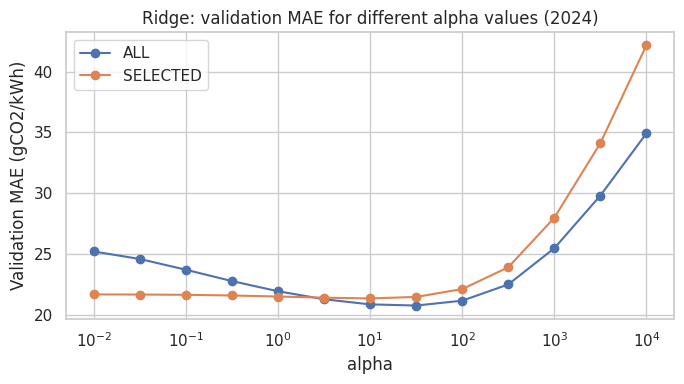

Best alpha is at the edge of the list: False


In [7]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# The two feature sets we compare
FEATSETS = {"ALL": ALL, "SELECTED": SELECTED}

# A list where we save every validation result (we will use it for all models)
VAL_LOG = []
def log_val(model, features, params, P):
    VAL_LOG.append({"model": model, "features": features, "params": params, **scores(P, Y[va_c])})

# Alpha values to try (from very small to very big)
alphas = np.logspace(-2, 4, 13)

for fs_name, cols in FEATSETS.items():
    for a in alphas:
        # The pipeline first scales the features, then fits Ridge.
        # The scaler learns only from the training days (no leakage).
        model = make_pipeline(StandardScaler(), Ridge(alpha=a))
        model.fit(X.loc[tr, cols], Y[tr])                    # train on 2022-2023
        P = model.predict(X.loc[va_c, cols])                 # predict 2024
        log_val("Ridge", fs_name, {"alpha": float(a)}, P)

# Show the best alpha for each feature set
ridge_val = pd.DataFrame([r for r in VAL_LOG if r["model"] == "Ridge"])
ridge_val["alpha"] = ridge_val["params"].map(lambda p: p["alpha"])
best_idx = ridge_val.groupby("features")["MAE"].idxmin()
display(ridge_val.loc[best_idx, ["features", "alpha", "MAE", "RMSE", "Bias"]].round(2))

# Plot: validation MAE for each alpha
fig, ax = plt.subplots(figsize=(7, 4))
for fs_name, g in ridge_val.groupby("features"):
    ax.plot(g["alpha"], g["MAE"], marker="o", label=fs_name)
ax.set(xscale="log", xlabel="alpha", ylabel=f"Validation MAE ({UNIT})",
       title="Ridge: validation MAE for different alpha values (2024)")
ax.legend()
plt.tight_layout()
plt.show()

# Check: is the best alpha at the edge of our list? (if True, we should try more values)
edge = ridge_val.loc[best_idx, "alpha"].isin([alphas[0], alphas[-1]]).any()
print("Best alpha is at the edge of the list:", bool(edge))

**Observation.** Ridge with all 222 features (ALL) gives the best validation MAE of 20.75 (alpha = 31.62), about 49% better than the Yesterday baseline (40.62). The 68 selected features (SELECTED) are slightly worse (21.33). The best alpha is inside the grid, not at the edge, so the grid was wide enough. The bias is +8.65: the model predicts too high on average, because it was trained on 2022-2023 when carbon intensity was higher than in 2024.

## Step 6: Model 2 - Random Forest

Random Forest builds many decision trees and averages them. It can learn non-linear patterns that Ridge cannot.
We train on 2022-2023, try a small grid of settings, and pick the best one on 2024 (validation).
Settings we tune:
- max_depth: how deep each tree can grow
- min_samples_leaf: minimum days in each leaf (bigger = simpler trees)
- max_features: share of features each split can look at

Settings per feature set: 12 | Total models to train: 24
Done in 85 seconds

Best setting for each feature set:


,features,max_depth,min_samples_leaf,max_features,MAE,RMSE,Bias
8,ALL,NaN,3,0.3,29.01,37.10,14.81
19,SELECTED,NaN,1,0.6,29.53,37.89,17.03


Top 5 Random Forest settings overall:


,features,max_depth,min_samples_leaf,max_features,MAE
8,ALL,NaN,3,0.3,29.01
6,ALL,NaN,1,0.3,29.02
0,ALL,8.0,1,0.3,29.18
2,ALL,8.0,3,0.3,29.19
10,ALL,NaN,5,0.3,29.20


Best result of each model on validation 2024 (Yesterday baseline MAE = 40.62):


,model,features,MAE,RMSE,Bias
0,Ridge,ALL,20.75,27.76,8.65
1,Ridge,SELECTED,21.33,28.74,8.01
2,Random Forest,ALL,29.01,37.10,14.81
3,Random Forest,SELECTED,29.53,37.89,17.03


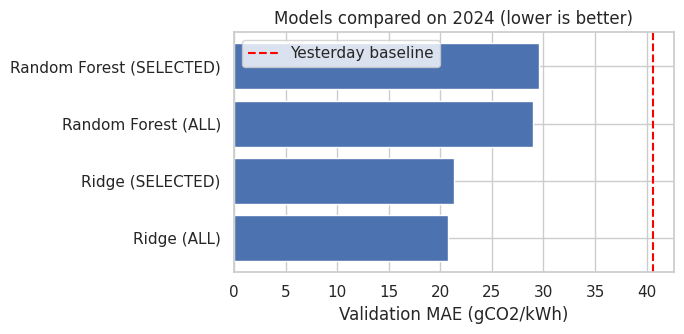

Ridge (ALL): MAE = 20.75
Ridge (SELECTED): MAE = 21.33
Random Forest (ALL): MAE = 29.01
Random Forest (SELECTED): MAE = 29.53


In [8]:
import itertools, time
from sklearn.ensemble import RandomForestRegressor

# Settings to try
depths = [8, None]            # None = no limit
leaves = [1, 3, 5]
max_feats = [0.3, 0.6]
combos = list(itertools.product(depths, leaves, max_feats))
print("Settings per feature set:", len(combos), "| Total models to train:", len(combos) * len(FEATSETS))

start = time.time()
for fs_name, cols in FEATSETS.items():
    for depth, leaf, mf in combos:
        rf = RandomForestRegressor(n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
                                   max_features=mf, n_jobs=-1, random_state=SEED)
        rf.fit(X.loc[tr, cols], Y[tr])               # train on 2022-2023
        P = rf.predict(X.loc[va_c, cols])            # predict 2024
        log_val("Random Forest", fs_name,
                {"max_depth": depth, "min_samples_leaf": leaf, "max_features": mf}, P)
print("Done in", round(time.time() - start), "seconds")

# Put the Random Forest results in a table
rf_val = pd.DataFrame([r for r in VAL_LOG if r["model"] == "Random Forest"])
rf_val = pd.concat([rf_val.drop(columns="params"), pd.DataFrame(rf_val["params"].tolist())], axis=1)

print("\nBest setting for each feature set:")
best_idx = rf_val.groupby("features")["MAE"].idxmin()
display(rf_val.loc[best_idx, ["features", "max_depth", "min_samples_leaf", "max_features", "MAE", "RMSE", "Bias"]].round(2))

print("Top 5 Random Forest settings overall:")
display(rf_val.sort_values("MAE").head(5)[["features", "max_depth", "min_samples_leaf", "max_features", "MAE"]].round(2))

#  Compare all models so far (validation 2024) 
all_val = pd.DataFrame(VAL_LOG)
best_all = all_val.loc[all_val.groupby(["model", "features"])["MAE"].idxmin(), ["model", "features", "MAE", "RMSE", "Bias"]]
best_all = best_all.sort_values("MAE").reset_index(drop=True)
print("Best result of each model on validation 2024 (Yesterday baseline MAE = 40.62):")
display(best_all.round(2))

# Bar chart of the same numbers
labels = best_all["model"] + " (" + best_all["features"] + ")"
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(labels, best_all["MAE"])
ax.axvline(40.62, color="red", linestyle="--", label="Yesterday baseline")
ax.set(xlabel=f"Validation MAE ({UNIT})", title="Models compared on 2024 (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

# Text version of the chart (so it can be read without the image)
for lab, m in zip(labels, best_all["MAE"]):
    print(f"{lab}: MAE = {m:.2f}")

**Observation.** The best Random Forest (ALL features, no depth limit, min_samples_leaf = 3, max_features = 0.3) has validation MAE 29.01 and bias +14.81. It is clearly worse than Ridge (20.75). ALL features are again better than SELECTED (29.53). A forest can only predict values it has seen in training, so it follows the drop in carbon intensity less well than a linear model.

## Step 6b: Random Forest - tuning pictures

Picture 1 shows the validation MAE for every setting we tried (a heatmap, darker = better).
Picture 2 shows what happens when we add more trees. We also show the training error.
If the training error is much lower than the validation error, the model is memorizing the training data (overfitting).


Validation MAE table, ALL features (rows = depth and leaf size, columns = max_features):


max_features,0.3,0.6
setting,,
"depth=8, leaf=1",29.18,29.45
"depth=8, leaf=3",29.19,29.52
"depth=8, leaf=5",29.31,29.45
"depth=None, leaf=1",29.02,29.23
"depth=None, leaf=3",29.01,29.38
"depth=None, leaf=5",29.20,29.49



Validation MAE table, SELECTED features (rows = depth and leaf size, columns = max_features):


max_features,0.3,0.6
setting,,
"depth=8, leaf=1",29.64,29.72
"depth=8, leaf=3",29.78,29.96
"depth=8, leaf=5",29.77,29.95
"depth=None, leaf=1",29.59,29.53
"depth=None, leaf=3",29.67,29.71
"depth=None, leaf=5",29.67,29.88


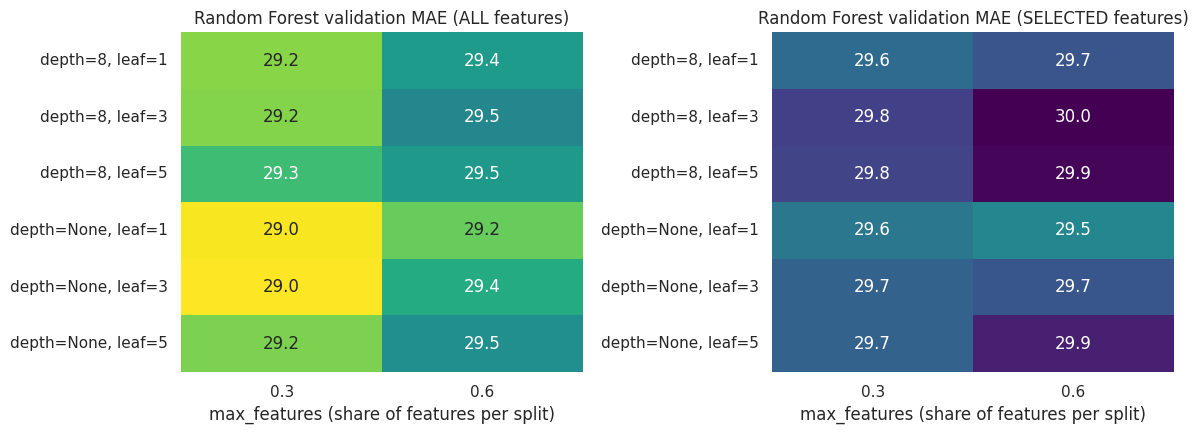

Best setting: depth=None, leaf=3, max_features=0.3, MAE=29.01
Worst setting: MAE=29.96 | difference between best and worst: 0.95

Random Forest: error for different numbers of trees


,trees,train MAE,validation MAE
0,10,14.08,30.04
1,25,13.60,29.33
2,50,13.29,28.93
3,100,13.14,28.86
4,150,13.08,29.06
5,200,13.07,29.01
6,300,13.07,28.98
7,400,13.06,29.01


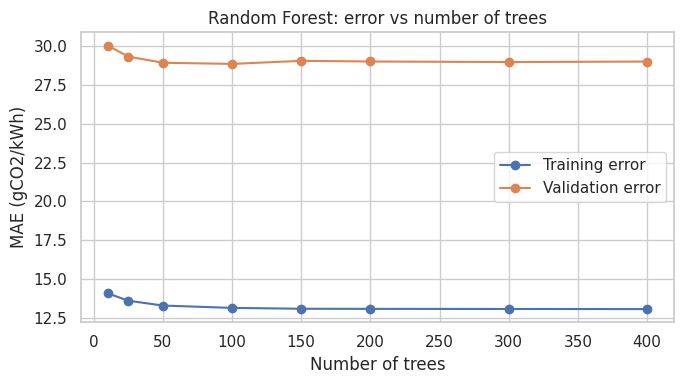

With 400 trees: training MAE = 13.06, validation MAE = 29.01
Gap between validation and training error: 15.95


In [9]:
#  Part 1: heatmap of all Random Forest settings 
rf_all = rf_val.copy()
rf_all["depth"] = rf_all["max_depth"].fillna(-1).astype(int).map(lambda d: "None" if d == -1 else str(d))
rf_all["setting"] = "depth=" + rf_all["depth"] + ", leaf=" + rf_all["min_samples_leaf"].astype(int).astype(str)

low, high = rf_all["MAE"].min(), rf_all["MAE"].max()      # same colors in both pictures
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, fs in zip(axes, ["ALL", "SELECTED"]):
    table = rf_all[rf_all["features"] == fs].pivot(index="setting", columns="max_features", values="MAE")
    sns.heatmap(table, annot=True, fmt=".1f", cmap="viridis_r", vmin=low, vmax=high, ax=ax, cbar=False)
    ax.set(title=f"Random Forest validation MAE ({fs} features)", xlabel="max_features (share of features per split)", ylabel="")
    print(f"\nValidation MAE table, {fs} features (rows = depth and leaf size, columns = max_features):")
    display(table.round(2))
plt.tight_layout()
plt.show()

best_row = rf_all.sort_values("MAE").iloc[0]
print(f"Best setting: {best_row['setting']}, max_features={best_row['max_features']}, MAE={best_row['MAE']:.2f}")
print(f"Worst setting: MAE={high:.2f} | difference between best and worst: {high - low:.2f}")

#  Part 2: more trees -> what happens to the error? 
rf_curve = RandomForestRegressor(n_estimators=10, max_depth=None, min_samples_leaf=3, max_features=0.3,
                                 warm_start=True, n_jobs=-1, random_state=SEED)   # warm_start: keep old trees, add new ones
rows = []
for n in [10, 25, 50, 100, 150, 200, 300, 400]:
    rf_curve.set_params(n_estimators=n)
    rf_curve.fit(X.loc[tr, ALL], Y[tr])
    rows.append({"trees": n,
                 "train MAE": scores(rf_curve.predict(X.loc[tr, ALL]), Y[tr])["MAE"],
                 "validation MAE": scores(rf_curve.predict(X.loc[va_c, ALL]), Y[va_c])["MAE"]})
tree_tbl = pd.DataFrame(rows)
print("\nRandom Forest: error for different numbers of trees")
display(tree_tbl.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tree_tbl["trees"], tree_tbl["train MAE"], marker="o", label="Training error")
ax.plot(tree_tbl["trees"], tree_tbl["validation MAE"], marker="o", label="Validation error")
ax.set(xlabel="Number of trees", ylabel=f"MAE ({UNIT})", title="Random Forest: error vs number of trees")
ax.legend()
plt.tight_layout()
plt.show()

last = tree_tbl.iloc[-1]
print(f"With {int(last['trees'])} trees: training MAE = {last['train MAE']:.2f}, validation MAE = {last['validation MAE']:.2f}")
print(f"Gap between validation and training error: {last['validation MAE'] - last['train MAE']:.2f}")

**Observation.** All 24 Random Forest settings give a validation MAE between 29.0 and 30.0 (the best and the worst differ by only 0.95), so the settings matter very little. The error stops improving after about 100 trees. The training MAE (13.06) is much lower than the validation MAE (29.01), a gap of 15.95: the forest memorizes the training years and does not generalize well to 2024.

## Step 7: Model 3 - LightGBM (one model for all 48 half-hours)

LightGBM builds trees one after another, and each tree fixes the mistakes of the previous ones.
We use a "long" table: one row for each day and each half-hour step (about 32,000 rows for training).
The step number (0 to 47) is a feature, so one model can predict all 48 values.

We test two targets:
- plain: predict the real carbon intensity.
- diff: predict the difference from the 7-day average at the same time, then add the average back.
  This helps because carbon intensity went down over the years, and trees cannot predict levels they have not seen.

In [10]:
import lightgbm as lgb
import time

# Day-level columns = all columns that are NOT the 48-step history columns
SLOT_PREFIX = ("ci_lag1d_s", "ci_lag7d_s", "ci_avg7d_s")
DAY_COLS = [c for c in ALL if not c.startswith(SLOT_PREFIX)]
print("Day-level features:", len(DAY_COLS))

# The 3 history columns that we pick for each step
STEP_COLS = {"ci_lag1d_s": "lag1d_now", "ci_lag7d_s": "lag7d_now", "ci_avg7d_s": "avg7d_now"}

def make_long(mask):
    # Make a table with one row for every (day, step)
    days = X.index[mask]
    n = len(days)
    # each day is repeated 48 times
    Xl = pd.DataFrame(np.repeat(X.loc[days, DAY_COLS].to_numpy(), HORIZON, axis=0), columns=DAY_COLS)
    Xl["step"] = np.tile(np.arange(HORIZON), n)          # step number 0..47
    for prefix, new_name in STEP_COLS.items():
        vals = X.loc[days, [f"{prefix}{s}" for s in range(HORIZON)]].to_numpy()
        Xl[new_name] = vals.reshape(-1)                  # the value for that exact step
    y = Y.loc[days].to_numpy().reshape(-1)               # real value for each row
    return Xl, y

# Build the long tables for train and validation
Xl_tr, y_tr = make_long(tr)
Xl_va, y_va = make_long(va_c)
print("Long table sizes -> train:", Xl_tr.shape, "| validation:", Xl_va.shape)

# Settings to try
leaves_list = [15, 31]
min_child_list = [20, 100]
target_types = ["plain", "diff"]

start = time.time()
for ttype in target_types:
    for leaves in leaves_list:
        for mc in min_child_list:
            lgbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=leaves,
                                     min_child_samples=mc, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)
            if ttype == "plain":
                lgbm.fit(Xl_tr, y_tr)
                pred = lgbm.predict(Xl_va)
            else:
                # learn the difference from the 7-day average, then add it back
                lgbm.fit(Xl_tr, y_tr - Xl_tr["avg7d_now"])
                pred = lgbm.predict(Xl_va) + Xl_va["avg7d_now"].to_numpy()
            P = pred.reshape(-1, HORIZON)                # back to 1 row per day
            log_val(f"LightGBM ({ttype})", "ALL", {"num_leaves": leaves, "min_child_samples": mc}, P)
print("Done in", round(time.time() - start), "seconds")

# Show the LightGBM results
lgb_val = pd.DataFrame([r for r in VAL_LOG if r["model"].startswith("LightGBM")])
lgb_val = pd.concat([lgb_val.drop(columns="params"), pd.DataFrame(lgb_val["params"].tolist())], axis=1)
print("\nAll LightGBM results (validation 2024):")
display(lgb_val[["model", "num_leaves", "min_child_samples", "MAE", "RMSE", "Bias"]].sort_values("MAE").round(2))

# Final comparison of the best result of each model
all_val = pd.DataFrame(VAL_LOG)
best_all = all_val.loc[all_val.groupby(["model", "features"])["MAE"].idxmin(), ["model", "features", "MAE", "RMSE", "Bias"]]
best_all = best_all.sort_values("MAE").reset_index(drop=True)
print("Best result of each model on validation 2024 (Yesterday baseline MAE = 40.62):")
display(best_all.round(2))

Day-level features: 78
Long table sizes -> train: (32400, 82) | validation: (17136, 82)
Done in 17 seconds

All LightGBM results (validation 2024):


,model,num_leaves,min_child_samples,MAE,RMSE,Bias
3,LightGBM (plain),31,100,23.81,30.79,11.23
7,LightGBM (diff),31,100,24.01,31.00,3.56
5,LightGBM (diff),15,100,24.11,31.10,3.30
2,LightGBM (plain),31,20,24.12,31.08,11.83
4,LightGBM (diff),15,20,24.17,31.01,3.56
1,LightGBM (plain),15,100,24.25,31.17,10.84
6,LightGBM (diff),31,20,24.28,31.32,2.67
0,LightGBM (plain),15,20,24.37,31.29,11.00


Best result of each model on validation 2024 (Yesterday baseline MAE = 40.62):


,model,features,MAE,RMSE,Bias
0,Ridge,ALL,20.75,27.76,8.65
1,Ridge,SELECTED,21.33,28.74,8.01
2,LightGBM (plain),ALL,23.81,30.79,11.23
3,LightGBM (diff),ALL,24.01,31.00,3.56
4,Random Forest,ALL,29.01,37.10,14.81
5,Random Forest,SELECTED,29.53,37.89,17.03


**Observation.** One pooled LightGBM model predicts all 48 half-hours (the step number is a feature; about 32,400 training rows). The best setting (plain target, num_leaves = 31, min_child_samples = 100) has validation MAE 23.81. Predicting the difference from the 7-day average ("diff" target) reduces the bias from +11.23 to +3.56 but gives almost the same MAE (24.01), so the drift is reduced but the accuracy is not better. LightGBM is better than Random Forest (29.01) and worse than Ridge (20.75).

## Step 7b: LightGBM - training curve

LightGBM builds trees one after another. Here we watch the error while the trees are added.
If the validation error stops going down (or goes up) while the training error keeps going down, more trees only add overfitting.
We also try different learning rates, because we used a fixed learning rate of 0.05 before.

Done in 13 seconds

LightGBM error after different numbers of trees:


,learning rate,trees,train MAE,validation MAE
0,0.02,50,30.53,40.91
1,0.02,100,21.13,32.46
2,0.02,200,14.69,27.13
3,0.02,300,12.02,25.40
4,0.02,400,10.62,24.68
5,0.02,600,9.05,24.08
6,0.05,50,18.71,29.76
7,0.05,100,13.09,25.91
8,0.05,200,9.77,24.25
9,0.05,300,8.33,23.81


Best number of trees (lowest validation MAE) for each learning rate:


,learning rate,best trees,validation MAE at best,train MAE at best,validation MAE at 600 trees
0,0.02,598,24.08,9.07,24.08
1,0.05,597,23.55,6.26,23.55
2,0.10,286,24.23,6.55,24.41


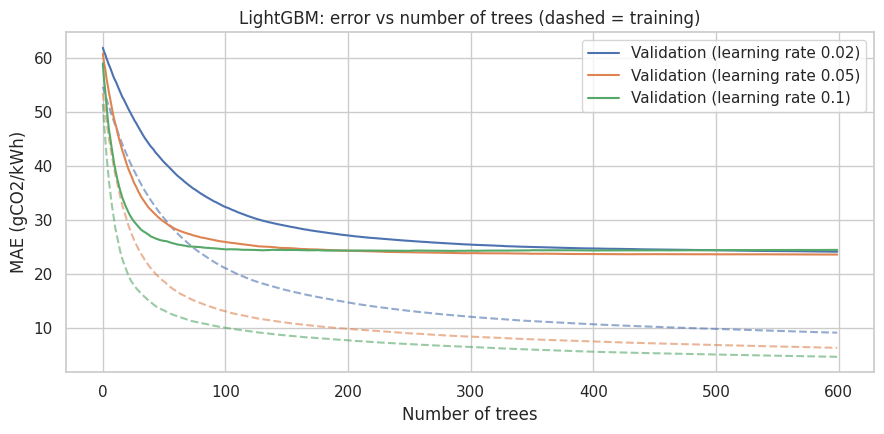


Our final setting (learning rate 0.05, 300 trees): validation MAE = 23.81
Best possible with learning rate 0.05: 23.55 at 597 trees


In [11]:
# We train 3 models with different learning rates and record the error after every tree
curves = {}
start = time.time()
for lr in [0.02, 0.05, 0.1]:
    model = lgb.LGBMRegressor(n_estimators=600, learning_rate=lr, num_leaves=31, min_child_samples=100,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=SEED, n_jobs=-1, verbose=-1)
    model.fit(Xl_tr, y_tr,
              eval_set=[(Xl_tr, y_tr), (Xl_va, y_va)],      # watch both training and validation data
              eval_metric="l1")                              # l1 = MAE
    res = model.evals_result_
    curves[lr] = {"train": np.array(res["training"]["l1"]), "validation": np.array(res["valid_1"]["l1"])}
print("Done in", round(time.time() - start), "seconds")

#  Table: error after some numbers of trees 
checkpoints = [50, 100, 200, 300, 400, 600]
rows = []
for lr, c in curves.items():
    for n in checkpoints:
        rows.append({"learning rate": lr, "trees": n, "train MAE": c["train"][n - 1], "validation MAE": c["validation"][n - 1]})
curve_tbl = pd.DataFrame(rows)
print("\nLightGBM error after different numbers of trees:")
display(curve_tbl.round(2))

#  Best number of trees for each learning rate 
print("Best number of trees (lowest validation MAE) for each learning rate:")
best_rows = []
for lr, c in curves.items():
    best_n = int(c["validation"].argmin()) + 1
    best_rows.append({"learning rate": lr, "best trees": best_n,
                      "validation MAE at best": c["validation"].min(),
                      "train MAE at best": c["train"][best_n - 1],
                      "validation MAE at 600 trees": c["validation"][-1]})
best_tbl = pd.DataFrame(best_rows)
display(best_tbl.round(2))

#  Picture 
fig, ax = plt.subplots(figsize=(9, 4.5))
for lr, c in curves.items():
    line, = ax.plot(c["validation"], label=f"Validation (learning rate {lr})")
    ax.plot(c["train"], linestyle="--", color=line.get_color(), alpha=0.6)
ax.set(xlabel="Number of trees", ylabel=f"MAE ({UNIT})", title="LightGBM: error vs number of trees (dashed = training)")
ax.legend()
plt.tight_layout()
plt.show()

# What we used in the final model
c05 = curves[0.05]
print(f"\nOur final setting (learning rate 0.05, 300 trees): validation MAE = {c05['validation'][299]:.2f}")
print(f"Best possible with learning rate 0.05: {c05['validation'].min():.2f} at {int(c05['validation'].argmin()) + 1} trees")

**Observation.** Our chosen setting (learning rate 0.05, 300 trees) has validation MAE 23.81. The best possible with this learning rate is 23.55 at about 600 trees, so we lose only 0.26 and keep the simpler model. A learning rate of 0.10 starts to overfit after about 286 trees (validation MAE goes from 24.23 to 24.41), and 0.02 is too slow. LightGBM overfits more than Ridge: training MAE is 6.26 and validation MAE is 23.55.

## Step 8: Optimization 1 - Recent-year weighting and a wider LightGBM grid

Carbon intensity went down over the years, so older data is less like the future.
Here we give more weight to 2023 (compared to 2022) while training.
recent_weight = 1 means no extra weight. recent_weight = 4 means a 2023 day counts 4 times more than a 2022 day.
We also test a wider LightGBM grid, because the best LightGBM setting was at the edge of the first grid.

In [12]:
# Years of the training days (so we can give weights)
tr_years = X.index[tr].year

def day_weights(r):
    # 2023 days get weight r, 2022 days get weight 1
    return np.where(tr_years == 2023, r, 1.0)

weights_to_try = [1, 2, 4, 8]

#  Ridge with weights 
for a in [10, 31.62, 100]:
    for r in weights_to_try:
        model = make_pipeline(StandardScaler(), Ridge(alpha=a))
        model.fit(X.loc[tr, ALL], Y[tr], ridge__sample_weight=day_weights(r))
        P = model.predict(X.loc[va_c, ALL])
        log_val("Ridge (weighted)", "ALL", {"alpha": a, "recent_weight": r}, P)

#  LightGBM (plain target) with weights and a wider grid 
start = time.time()
for leaves in [31, 63]:
    for mc in [100, 200, 400]:
        for r in [1, 2, 4]:
            lgbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=leaves,
                                     min_child_samples=mc, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)
            w_long = np.repeat(day_weights(r), HORIZON)       # each day is repeated 48 times
            lgbm.fit(Xl_tr, y_tr, sample_weight=w_long)
            P = lgbm.predict(Xl_va).reshape(-1, HORIZON)
            log_val("LightGBM (weighted)", "ALL",
                    {"num_leaves": leaves, "min_child_samples": mc, "recent_weight": r}, P)
print("LightGBM done in", round(time.time() - start), "seconds")

#  Show the results 
def show_top(model_name, n=5):
    d = pd.DataFrame([r for r in VAL_LOG if r["model"] == model_name])
    d = pd.concat([d.drop(columns="params"), pd.DataFrame(d["params"].tolist())], axis=1)
    print(f"\nTop {n} settings for {model_name}:")
    cols = [c for c in d.columns if c not in ("model", "features")]
    display(d.sort_values("MAE").head(n)[cols].round(2))

show_top("Ridge (weighted)")
show_top("LightGBM (weighted)")

# Compare with the best results before weighting
all_val = pd.DataFrame(VAL_LOG)
best_all = all_val.loc[all_val.groupby(["model", "features"])["MAE"].idxmin(), ["model", "features", "MAE", "RMSE", "Bias"]]
best_all = best_all.sort_values("MAE").reset_index(drop=True)
print("\nBest result of each model on validation 2024 (Yesterday baseline MAE = 40.62):")
display(best_all.round(2))

LightGBM done in 56 seconds

Top 5 settings for Ridge (weighted):


,MAE,RMSE,Bias,alpha,recent_weight
5,20.72,27.73,8.59,31.62,2
4,20.75,27.76,8.65,31.62,1
9,20.78,27.56,8.46,100.00,2
0,20.84,28.03,8.76,10.00,1
10,20.90,27.80,8.70,100.00,4



Top 5 settings for LightGBM (weighted):


,MAE,RMSE,Bias,num_leaves,min_child_samples,recent_weight
5,23.79,30.77,12.03,31,200,4
0,23.81,30.79,11.23,31,100,1
4,23.83,30.73,11.80,31,200,2
6,23.93,30.94,11.38,31,400,1
3,23.95,30.83,11.41,31,200,1



Best result of each model on validation 2024 (Yesterday baseline MAE = 40.62):


,model,features,MAE,RMSE,Bias
0,Ridge (weighted),ALL,20.72,27.73,8.59
1,Ridge,ALL,20.75,27.76,8.65
2,Ridge,SELECTED,21.33,28.74,8.01
3,LightGBM (weighted),ALL,23.79,30.77,12.03
4,LightGBM (plain),ALL,23.81,30.79,11.23
5,LightGBM (diff),ALL,24.01,31.00,3.56
6,Random Forest,ALL,29.01,37.10,14.81
7,Random Forest,SELECTED,29.53,37.89,17.03


**Observation.** Giving more weight to 2023 days did not help: Ridge changed from 20.75 to 20.72 and LightGBM from 23.81 to 23.79. These differences are tiny, so we do not use weighting in the final model. A wider LightGBM grid also did not give a real improvement, so the first grid was good enough. The positive bias stays (+8.6 for Ridge), because both 2022 and 2023 have higher carbon intensity than 2024.

## Step 9: Optimization 2 - Ridge with "diff" target and feature group ablation

Part A: Ridge learns the difference from the 7-day average (then we add the average back).
This pulls the prediction toward the recent level, which should reduce the bias.

Part B: Ablation. We remove one feature group at a time and check the validation MAE.
If the MAE goes UP when a group is removed, that group is helpful.

In [13]:
#  Part A: Ridge with the "diff" target 
base_tr = to_np(Y_wk7[tr])        # 7-day average for the train days
base_va = to_np(Y_wk7[va_c])      # 7-day average for the validation days

for a in [10, 31.62, 100, 316, 1000, 3160]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=a))
    model.fit(X.loc[tr, ALL], to_np(Y[tr]) - base_tr)        # learn the difference
    P = model.predict(X.loc[va_c, ALL]) + base_va            # add the average back
    log_val("Ridge (diff)", "ALL", {"alpha": a}, P)

d = pd.DataFrame([r for r in VAL_LOG if r["model"] == "Ridge (diff)"])
d["alpha"] = d["params"].map(lambda p: p["alpha"])
print("Ridge (diff) results on validation 2024 (plain Ridge best: MAE 20.75, Bias 8.65):")
display(d[["alpha", "MAE", "RMSE", "Bias"]].round(2))

#  Part B: Feature group ablation (Ridge, alpha = 31.62) 
GROUPS = ("ci_lag1d", "ci_lag7d", "ci_avg7d", "ci_prev", "gen_prev", "wx_prev", "wx_tgt")
def group_of(col):
    # find which group a column belongs to
    return next((g for g in GROUPS if col.startswith(g)), "calendar")

groups = pd.Series({c: group_of(c) for c in ALL})
print("\nNumber of features in each group:")
print(groups.value_counts().to_string())

def ridge_check(cols):
    model = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
    model.fit(X.loc[tr, cols], Y[tr])
    return scores(model.predict(X.loc[va_c, cols]), Y[va_c])

rows = [{"removed": "nothing (ALL)", "n_features": len(ALL), **ridge_check(ALL)}]
for g in groups.unique():
    cols = [c for c in ALL if groups[c] != g]                 # keep everything except group g
    rows.append({"removed": g, "n_features": len(cols), **ridge_check(cols)})

# also remove ALL weather together
cols = [c for c in ALL if groups[c] not in ("wx_prev", "wx_tgt")]
rows.append({"removed": "all weather (wx_prev + wx_tgt)", "n_features": len(cols), **ridge_check(cols)})

abl = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print("\nAblation results on validation 2024 (lower MAE = better):")
display(abl.round(2))

Ridge (diff) results on validation 2024 (plain Ridge best: MAE 20.75, Bias 8.65):


,alpha,MAE,RMSE,Bias
0,10.00,20.87,28.06,8.74
1,31.62,20.78,27.81,8.59
2,100.00,21.19,28.02,8.77
3,316.00,22.45,29.19,9.56
4,1000.00,25.09,32.06,10.62
5,3160.00,28.73,36.17,10.08



Number of features in each group:
ci_lag1d    48
ci_lag7d    48
ci_avg7d    48
wx_tgt      48
wx_prev     12
gen_prev     8
calendar     6
ci_prev      4

Ablation results on validation 2024 (lower MAE = better):


,removed,n_features,MAE,RMSE,Bias
0,ci_lag7d,174,20.63,27.62,8.50
1,nothing (ALL),222,20.75,27.76,8.65
2,ci_avg7d,174,20.95,28.12,9.26
3,ci_prev,218,20.96,27.91,8.75
4,wx_prev,210,21.23,28.22,9.80
5,gen_prev,214,21.30,28.17,10.01
6,ci_lag1d,174,21.55,28.45,9.32
7,calendar,216,22.32,29.88,8.49
8,wx_tgt,174,27.07,35.86,3.36
9,all weather (wx_prev + wx_tgt),162,27.27,36.13,3.69


**Observation.** Part A: Ridge with the "diff" target (MAE 20.78) is not better than normal Ridge (20.75), so we keep normal Ridge. Part B (ablation): the weather of the target day (wx_tgt) is by far the most important group: removing it raises the MAE from 20.75 to 27.07, and removing all weather gives 27.27. The calendar features (22.32), yesterday's values (21.55), the fuel mix (21.30) and yesterday's weather (21.23) matter less. Removing the same-time-last-week values (ci_lag7d) changes the MAE by only 0.12 (20.63), which is within noise, so we keep ALL features.

## Step 10: Ensemble and per-slot LightGBM

Ensemble: we average the predictions of Ridge and LightGBM. Different models make different mistakes,
so their average can be better than each one alone.

Per-slot LightGBM: one separate model for each of the 48 half-hours (the proposal said we may test this).
Each model only has about 675 training rows, so we use small trees.

In [14]:
#  Refit the best Ridge and best LightGBM, and keep their validation predictions 
best_ridge = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
best_ridge.fit(X.loc[tr, ALL], Y[tr])
P_ridge_va = best_ridge.predict(X.loc[va_c, ALL])

best_lgbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=100, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)
best_lgbm.fit(Xl_tr, y_tr)
P_lgbm_va = best_lgbm.predict(Xl_va).reshape(-1, HORIZON)

#  Ensemble: weighted average of Ridge and LightGBM 
print("Ensemble results on validation 2024:")
rows = []
for w in [1.0, 0.8, 0.7, 0.6, 0.5, 0.0]:          # w = share given to Ridge
    P = w * P_ridge_va + (1 - w) * P_lgbm_va
    rows.append({"Ridge share": w, "LightGBM share": round(1 - w, 1), **scores(P, Y[va_c])})
    if 0 < w < 1:
        log_val("Ensemble (Ridge+LightGBM)", "ALL", {"ridge_share": w}, P)
ens_tbl = pd.DataFrame(rows)
display(ens_tbl.round(2))

#  Per-slot LightGBM: 48 separate models 
start = time.time()
P_slot_va = np.zeros((int(va_c.sum()), HORIZON))
for k in range(HORIZON):
    # day-level features + the 3 history values for this exact half-hour
    cols_k = DAY_COLS + [f"ci_lag1d_s{k}", f"ci_lag7d_s{k}", f"ci_avg7d_s{k}"]
    m = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=SEED, n_jobs=-1, verbose=-1)
    m.fit(X.loc[tr, cols_k], Y.loc[tr, k])
    P_slot_va[:, k] = m.predict(X.loc[va_c, cols_k])
print("\nPer-slot LightGBM done in", round(time.time() - start), "seconds")
log_val("LightGBM (per-slot)", "ALL", {"num_leaves": 7}, P_slot_va)
print("Per-slot LightGBM validation:", {k: round(v, 2) for k, v in scores(P_slot_va, Y[va_c]).items()})
print("Pooled LightGBM validation  :", {k: round(v, 2) for k, v in scores(P_lgbm_va, Y[va_c]).items()})

#  Final comparison table (validation 2024) 
all_val = pd.DataFrame(VAL_LOG)
best_all = all_val.loc[all_val.groupby(["model", "features"])["MAE"].idxmin(), ["model", "features", "MAE", "RMSE", "Bias"]]
best_all = best_all.sort_values("MAE").reset_index(drop=True)
print("\nAll models on validation 2024 (Yesterday baseline MAE = 40.62):")
display(best_all.round(2))

Ensemble results on validation 2024:


,Ridge share,LightGBM share,MAE,RMSE,Bias
0,1.0,0.0,20.75,27.76,8.65
1,0.8,0.2,20.59,27.34,9.16
2,0.7,0.3,20.68,27.33,9.42
3,0.6,0.4,20.86,27.45,9.68
4,0.5,0.5,21.13,27.71,9.94
5,0.0,1.0,23.81,30.79,11.23



Per-slot LightGBM done in 7 seconds
Per-slot LightGBM validation: {'MAE': np.float64(24.24), 'RMSE': np.float64(31.77), 'Bias': np.float64(14.73)}
Pooled LightGBM validation  : {'MAE': np.float64(23.81), 'RMSE': np.float64(30.79), 'Bias': np.float64(11.23)}

All models on validation 2024 (Yesterday baseline MAE = 40.62):


,model,features,MAE,RMSE,Bias
0,Ensemble (Ridge+LightGBM),ALL,20.59,27.34,9.16
1,Ridge (weighted),ALL,20.72,27.73,8.59
2,Ridge,ALL,20.75,27.76,8.65
3,Ridge (diff),ALL,20.78,27.81,8.59
4,Ridge,SELECTED,21.33,28.74,8.01
5,LightGBM (weighted),ALL,23.79,30.77,12.03
6,LightGBM (plain),ALL,23.81,30.79,11.23
7,LightGBM (diff),ALL,24.01,31.00,3.56
8,LightGBM (per-slot),ALL,24.24,31.77,14.73
9,Random Forest,ALL,29.01,37.10,14.81


**Observation.** An ensemble of 80% Ridge and 20% LightGBM gives the lowest validation MAE of all models (20.59, bias +9.16), slightly better than Ridge alone (20.75) and clearly better than LightGBM alone (23.81). The per-slot LightGBM (48 separate models, each with only about 675 rows) is a little worse than the pooled model (24.24 vs 23.81), so the pooled model is the better choice. Final choice, made on the validation data only: the 80/20 ensemble with ALL features.

## Step 10b: Learning curve - how much training data do we need?

We train Ridge and LightGBM on the first 25%, 50%, 75% and 100% of the training days (2022-2023),
and always check on the same validation days (2024).
Because we take the OLDEST days first, this also shows the value of having more data.
If the validation error is still going down at 100%, more data would help.

Learning curve numbers:


,model,share of training days,days,train MAE,validation MAE
0,Ridge,0.25,168,14.12,36.89
1,LightGBM,0.25,168,4.93,36.45
2,Ridge,0.50,337,15.37,30.67
3,LightGBM,0.50,337,6.32,30.38
4,Ridge,0.75,506,16.01,23.37
5,LightGBM,0.75,506,7.45,26.63
6,Ridge,1.00,675,16.51,20.75
7,LightGBM,1.00,675,8.33,23.81


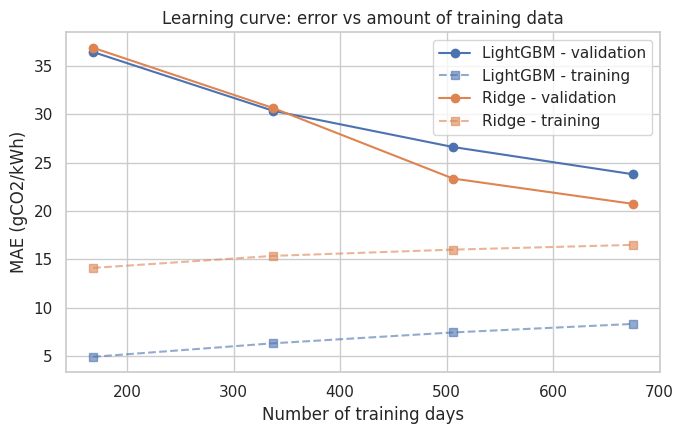

LightGBM: validation MAE went from 36.45 (168 days) to 23.81 (675 days)
Ridge: validation MAE went from 36.89 (168 days) to 20.75 (675 days)


In [15]:
# Train days in time order
train_days = X.index[tr]
n_total = len(train_days)

rows = []
for frac in [0.25, 0.5, 0.75, 1.0]:
    n = int(n_total * frac)
    use = train_days[:n]                         # the first n days (oldest days first)

    #  Ridge 
    ridge_m = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
    ridge_m.fit(X.loc[use, ALL], Y.loc[use])
    p_tr = ridge_m.predict(X.loc[use, ALL])
    p_va = ridge_m.predict(X.loc[va_c, ALL])
    rows.append({"model": "Ridge", "share of training days": frac, "days": n,
                 "train MAE": scores(p_tr, Y.loc[use])["MAE"],
                 "validation MAE": scores(p_va, Y[va_c])["MAE"]})

    #  LightGBM (long table made only from these days) 
    mask_use = pd.Series(X.index.isin(use), index=X.index) & tr
    Xl_use, y_use = make_long(mask_use)
    lgbm_m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               random_state=SEED, n_jobs=-1, verbose=-1)
    lgbm_m.fit(Xl_use, y_use)
    p_tr = lgbm_m.predict(Xl_use)
    p_va = lgbm_m.predict(Xl_va)
    rows.append({"model": "LightGBM", "share of training days": frac, "days": n,
                 "train MAE": np.abs(p_tr - y_use).mean(),
                 "validation MAE": np.abs(p_va - y_va).mean()})

lc = pd.DataFrame(rows)
print("Learning curve numbers:")
display(lc.round(2))

#  Picture 
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, g in lc.groupby("model"):
    line, = ax.plot(g["days"], g["validation MAE"], marker="o", label=f"{name} - validation")
    ax.plot(g["days"], g["train MAE"], marker="s", linestyle="--", color=line.get_color(), alpha=0.6, label=f"{name} - training")
ax.set(xlabel="Number of training days", ylabel=f"MAE ({UNIT})", title="Learning curve: error vs amount of training data")
ax.legend()
plt.tight_layout()
plt.show()

#  What it says 
for name, g in lc.groupby("model"):
    first, last = g.iloc[0], g.iloc[-1]
    print(f"{name}: validation MAE went from {first['validation MAE']:.2f} ({int(first['days'])} days) to {last['validation MAE']:.2f} ({int(last['days'])} days)")

**Observation.** With more training data the validation error goes down a lot: Ridge from 36.89 (168 days) to 20.75 (675 days), LightGBM from 36.45 to 23.81. The curve is still falling at 100%, so more data would probably help; this supports training the final model on 2022-2024. LightGBM has a big gap between training error (8.33) and validation error (23.81), Ridge has a smaller gap (16.51 vs 20.75). Note: we add the oldest days first, so this curve shows the effect of more data and of data closer to 2024 together.

## Step 10c: Time-series cross-validation

Until now we tuned and compared the models on one validation year (2024).
Here we check if the ranking of the models is the same on 4 different validation periods.
We always train on the PAST only and validate on the period right after it (expanding window).
The test year 2025 is not used here.

- Fold 1: train 2022, validate 2023 first half
- Fold 2: train 2022 to mid 2023, validate 2023 second half
- Fold 3: train 2022 to 2023, validate 2024 first half
- Fold 4: train 2022 to mid 2024, validate 2024 second half

Done in 21 seconds

MAE in each fold:


model,Yesterday,Ridge,Random Forest,LightGBM,Ensemble
fold,,,,,
Fold 1 (val 2023 H1),38.61,24.60,25.36,23.58,23.63
Fold 2 (val 2023 H2),45.84,20.48,26.95,22.52,20.12
Fold 3 (val 2024 H1),41.10,19.70,28.42,23.46,19.62
Fold 4 (val 2024 H2),40.16,20.10,25.71,21.02,19.49
Average of 4 folds,41.43,21.22,26.61,22.64,20.72
Std between folds,3.11,2.28,1.38,1.18,1.96


Number of days in each fold:


,train days,validation days
fold,,
Fold 1 (val 2023 H1),341,160
Fold 2 (val 2023 H2),501,174
Fold 3 (val 2024 H1),675,173
Fold 4 (val 2024 H2),848,184


Bias in each fold (positive = model predicts too high):


model,Yesterday,Ridge,Random Forest,LightGBM,Ensemble
fold,,,,,
Fold 1 (val 2023 H1),0.04,18.29,12.98,12.90,17.21
Fold 2 (val 2023 H2),0.14,7.21,7.14,5.38,6.84
Fold 3 (val 2024 H1),0.16,5.84,13.26,9.59,6.59
Fold 4 (val 2024 H2),0.21,7.81,8.79,7.31,7.71


Best model in each fold:
  Fold 1 (val 2023 H1): LightGBM (MAE 23.58, Yesterday 38.61)
  Fold 2 (val 2023 H2): Ensemble (MAE 20.12, Yesterday 45.84)
  Fold 3 (val 2024 H1): Ensemble (MAE 19.62, Yesterday 41.10)
  Fold 4 (val 2024 H2): Ensemble (MAE 19.49, Yesterday 40.16)

Average improvement over Yesterday:
  Ridge: 48.8% better
  Random Forest: 35.8% better
  LightGBM: 45.3% better
  Ensemble: 50.0% better


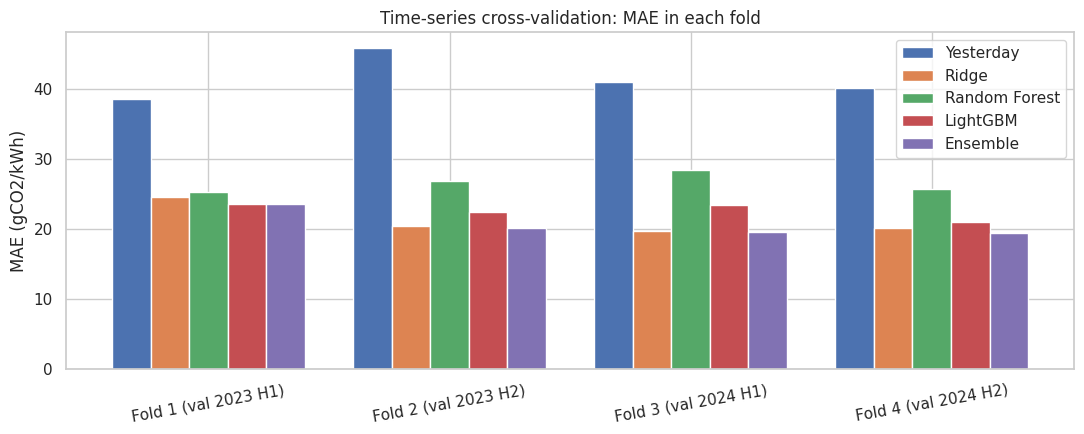

In [16]:
def T(text):
    # make a date with the UTC time zone
    return pd.Timestamp(text, tz="UTC")

# (name, train ends before, validation starts, validation ends before)
folds = [
    ("Fold 1 (val 2023 H1)", "2023-01-01", "2023-01-01", "2023-07-01"),
    ("Fold 2 (val 2023 H2)", "2023-07-01", "2023-07-01", "2024-01-01"),
    ("Fold 3 (val 2024 H1)", "2024-01-01", "2024-01-01", "2024-07-01"),
    ("Fold 4 (val 2024 H2)", "2024-07-01", "2024-07-01", "2025-01-01"),
]

idx = X.index
results = []
start = time.time()
for name, train_end, val_start, val_end in folds:
    # days to train on: everything BEFORE the validation period (only valid days)
    m_tr = ok & pd.Series(idx < T(train_end), index=idx)
    # days to validate on
    m_va = ok & pd.Series((idx >= T(val_start)) & (idx < T(val_end)), index=idx)
    A = to_np(Y[m_va])
    preds = {}

    # Baseline: yesterday
    preds["Yesterday"] = to_np(Y_yday[m_va])

    # Ridge
    ridge_cv = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
    ridge_cv.fit(X.loc[m_tr, ALL], Y[m_tr])
    preds["Ridge"] = ridge_cv.predict(X.loc[m_va, ALL])

    # LightGBM (one model for all 48 steps)
    Xl_a, y_a = make_long(m_tr)
    Xl_b, _ = make_long(m_va)
    lgbm_cv = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                random_state=SEED, n_jobs=-1, verbose=-1)
    lgbm_cv.fit(Xl_a, y_a)
    preds["LightGBM"] = lgbm_cv.predict(Xl_b).reshape(-1, HORIZON)

    # Ensemble (80% Ridge + 20% LightGBM)
    preds["Ensemble"] = 0.8 * preds["Ridge"] + 0.2 * preds["LightGBM"]

    # Random Forest
    rf_cv = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.3,
                                  n_jobs=-1, random_state=SEED)
    rf_cv.fit(X.loc[m_tr, ALL], Y[m_tr])
    preds["Random Forest"] = rf_cv.predict(X.loc[m_va, ALL])

    for model_name, P in preds.items():
        s = scores(P, A)
        results.append({"fold": name, "train days": int(m_tr.sum()), "validation days": int(m_va.sum()),
                        "model": model_name, "MAE": s["MAE"], "Bias": s["Bias"]})
print("Done in", round(time.time() - start), "seconds")

cv = pd.DataFrame(results)
order = ["Yesterday", "Ridge", "Random Forest", "LightGBM", "Ensemble"]
fold_names = [f[0] for f in folds]

#  Table of MAE 
mae_tbl = cv.pivot(index="fold", columns="model", values="MAE").reindex(fold_names)[order]
mae_tbl.loc["Average of 4 folds"] = mae_tbl.mean()
mae_tbl.loc["Std between folds"] = mae_tbl.iloc[:4].std()
print("\nMAE in each fold:")
display(mae_tbl.round(2))

#  Table of days and bias 
info = cv[cv["model"] == "Ridge"][["fold", "train days", "validation days"]].set_index("fold").reindex(fold_names)
print("Number of days in each fold:")
display(info)
bias_tbl = cv.pivot(index="fold", columns="model", values="Bias").reindex(fold_names)[order]
print("Bias in each fold (positive = model predicts too high):")
display(bias_tbl.round(2))

#  Which model wins? 
models_only = [m for m in order if m != "Yesterday"]
winners = mae_tbl.iloc[:4][models_only].idxmin(axis=1)
print("Best model in each fold:")
for f, w in winners.items():
    print(f"  {f}: {w} (MAE {mae_tbl.loc[f, w]:.2f}, Yesterday {mae_tbl.loc[f, 'Yesterday']:.2f})")
avg = mae_tbl.loc["Average of 4 folds"]
print("\nAverage improvement over Yesterday:")
for m in models_only:
    print(f"  {m}: {100 * (1 - avg[m] / avg['Yesterday']):.1f}% better")

#  Picture 
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(fold_names)); w = 0.16
for i, m in enumerate(order):
    ax.bar(x + (i - 2) * w, mae_tbl.iloc[:4][m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(fold_names, rotation=10)
ax.set(ylabel=f"MAE ({UNIT})", title="Time-series cross-validation: MAE in each fold")
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** In time-series cross-validation (4 folds, 2023 and 2024) the average MAE is 20.72 for the ensemble, 21.22 for Ridge, 22.64 for LightGBM, 26.61 for Random Forest and 41.43 for the Yesterday baseline. The ensemble is the best in 3 of 4 folds (LightGBM wins fold 1, where only 2022 is available for training). So the ranking of the models is not only a result of the 2024 validation year. The bias is positive in every fold and largest in fold 1 (Ridge +18.29), the fold where the training years are most different from the validation period. Note: the model settings were chosen on 2024, so folds 3 and 4 are not completely independent.

## Step 11: Final refit (2022-2024) and one-time test on 2025

All settings are now fixed (they were chosen on 2024 validation).
We train every model again on 2022-2024 and test ONCE on 2025.
The 2025 data was never used for training, tuning or choosing models.

Final model chosen by lowest validation MAE: Ensemble (80% Ridge + 20% LightGBM).
We also show Ridge alone, LightGBM, Random Forest and per-slot LightGBM for comparison.

Training days: 1032 | Long training rows: 49536 | Test days: 361

TEST RESULTS on 2025 ( 361 days )


,model,MAE,RMSE,Bias,better than Yesterday (%),better than 7-day avg (%)
0,NESO (reference),9.19,12.49,1.13,76.34,78.15
1,LightGBM (per-slot),18.94,25.39,7.78,51.28,55.00
2,LightGBM,19.65,26.00,5.89,49.45,53.30
3,Ensemble (80% Ridge + 20% LightGBM),19.81,26.14,7.66,49.04,52.93
4,Ridge,20.55,27.17,8.10,47.13,51.16
5,Random Forest,22.65,29.72,6.76,41.71,46.16
6,Yesterday,38.87,50.73,-0.15,0.00,7.63
7,7-day average,42.08,52.58,-0.09,-8.26,0.00


RQ1 target: MAE below 31.09 (20% better than the best simple baseline)
Final model MAE: 19.81 -> RQ1 PASSED


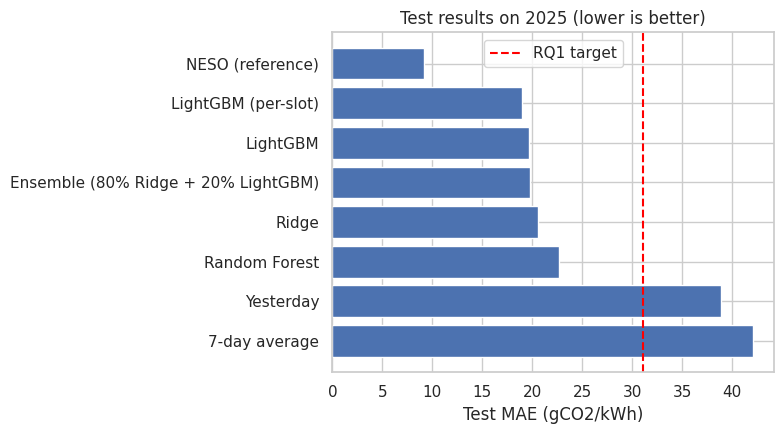

NESO (reference): MAE = 9.19
LightGBM (per-slot): MAE = 18.94
LightGBM: MAE = 19.65
Ensemble (80% Ridge + 20% LightGBM): MAE = 19.81
Ridge: MAE = 20.55
Random Forest: MAE = 22.65
Yesterday: MAE = 38.87
7-day average: MAE = 42.08


In [17]:
# Train on all days of 2022-2024
train_full = tr | va
Xl_full, y_full = make_long(train_full)       # long table for LightGBM (about 50,000 rows)
Xl_te, _ = make_long(te_c)                    # long table for the 2025 test days
A_te = to_np(Y[te_c])                         # real values of 2025
print("Training days:", int(train_full.sum()), "| Long training rows:", Xl_full.shape[0], "| Test days:", int(te_c.sum()))

PRED_TE = {}                                  # we keep all test predictions here

#  Baselines 
PRED_TE["Yesterday"] = to_np(Y_yday[te_c])
PRED_TE["7-day average"] = to_np(Y_wk7[te_c])
PRED_TE["NESO (reference)"] = to_np(NESO[te_c])

#  Ridge 
final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
final_ridge.fit(X.loc[train_full, ALL], Y[train_full])
PRED_TE["Ridge"] = final_ridge.predict(X.loc[te_c, ALL])

#  LightGBM (one model for all 48 steps) 
final_lgbm = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                               min_child_samples=100, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)
final_lgbm.fit(Xl_full, y_full)
PRED_TE["LightGBM"] = final_lgbm.predict(Xl_te).reshape(-1, HORIZON)

#  Random Forest 
final_rf = RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_leaf=3,
                                 max_features=0.3, n_jobs=-1, random_state=SEED)
final_rf.fit(X.loc[train_full, ALL], Y[train_full])
PRED_TE["Random Forest"] = final_rf.predict(X.loc[te_c, ALL])

#  Per-slot LightGBM (48 small models) 
P_slot = np.zeros((int(te_c.sum()), HORIZON))
for k in range(HORIZON):
    cols_k = DAY_COLS + [f"ci_lag1d_s{k}", f"ci_lag7d_s{k}", f"ci_avg7d_s{k}"]
    m = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=SEED, n_jobs=-1, verbose=-1)
    m.fit(X.loc[train_full, cols_k], Y.loc[train_full, k])
    P_slot[:, k] = m.predict(X.loc[te_c, cols_k])
PRED_TE["LightGBM (per-slot)"] = P_slot

#  Final model: Ensemble 
FINAL_NAME = "Ensemble (80% Ridge + 20% LightGBM)"
PRED_TE[FINAL_NAME] = 0.8 * PRED_TE["Ridge"] + 0.2 * PRED_TE["LightGBM"]

#  Results table 
mae_yday = scores(PRED_TE["Yesterday"], A_te)["MAE"]
mae_wk7 = scores(PRED_TE["7-day average"], A_te)["MAE"]
rows = []
for name, P in PRED_TE.items():
    s = scores(P, A_te)
    rows.append({"model": name, **s,
                 "better than Yesterday (%)": 100 * (1 - s["MAE"] / mae_yday),
                 "better than 7-day avg (%)": 100 * (1 - s["MAE"] / mae_wk7)})
test_tbl = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print("\nTEST RESULTS on 2025 (", int(te_c.sum()), "days )")
display(test_tbl.round(2))

#  RQ1 check 
fin = scores(PRED_TE[FINAL_NAME], A_te)["MAE"]
print("RQ1 target: MAE below", round(rq1_target, 2), "(20% better than the best simple baseline)")
print("Final model MAE:", round(fin, 2), "->", "RQ1 PASSED" if fin < rq1_target else "RQ1 NOT passed")

#  Bar chart + same numbers as text 
plot_df = test_tbl.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_df["model"], plot_df["MAE"])
ax.axvline(rq1_target, color="red", linestyle="--", label="RQ1 target")
ax.set(xlabel=f"Test MAE ({UNIT})", title="Test results on 2025 (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()
for _, r in test_tbl.iterrows():
    print(f"{r['model']}: MAE = {r['MAE']:.2f}")

**Observation.** After training on 2022-2024 (1,032 days, 49,536 long rows) and testing once on 2025 (361 days), the final ensemble has MAE 19.81, RMSE 26.14 and bias +7.66. This is 49% better than the Yesterday baseline (38.87) and 53% better than the 7-day average (42.08), so RQ1 is passed (target 31.09). On the test set, per-slot LightGBM (18.94) and pooled LightGBM (19.65) are slightly better than the ensemble. We did not change the final model after seeing the test results, because it was chosen on the validation data; the differences are small. The NESO forecast (MAE 9.19) is much more accurate, but it is made with a different time horizon.

## Step 11b: Overfitting check - training vs validation vs test error

If a model has a very low training error but a much higher error on new data, it is overfitting (it memorizes the training days).
We show two phases:
- Development phase: trained on 2022-2023, checked on 2024 (validation).
- Final phase: trained on 2022-2024, checked on 2025 (test).
The test numbers are only reported here. Nothing was tuned on the test data.

Training vs validation vs test error (gap = new-data error minus training error):


,train MAE (2022-23),validation MAE (2024),gap 1,train MAE (2022-24),test MAE (2025),gap 2
model,,,,,,
Ridge,16.51,20.75,4.24,16.93,20.55,3.62
Random Forest,13.07,29.01,15.94,13.14,22.65,9.51
LightGBM,8.33,23.81,15.48,9.52,19.65,10.13
Ensemble,14.25,20.59,6.35,14.79,19.81,5.02


Ridge: training 16.9 -> test 20.5 (test is 1.2 times the training error)
Random Forest: training 13.1 -> test 22.7 (test is 1.7 times the training error)
LightGBM: training 9.5 -> test 19.6 (test is 2.1 times the training error)
Ensemble: training 14.8 -> test 19.8 (test is 1.3 times the training error)


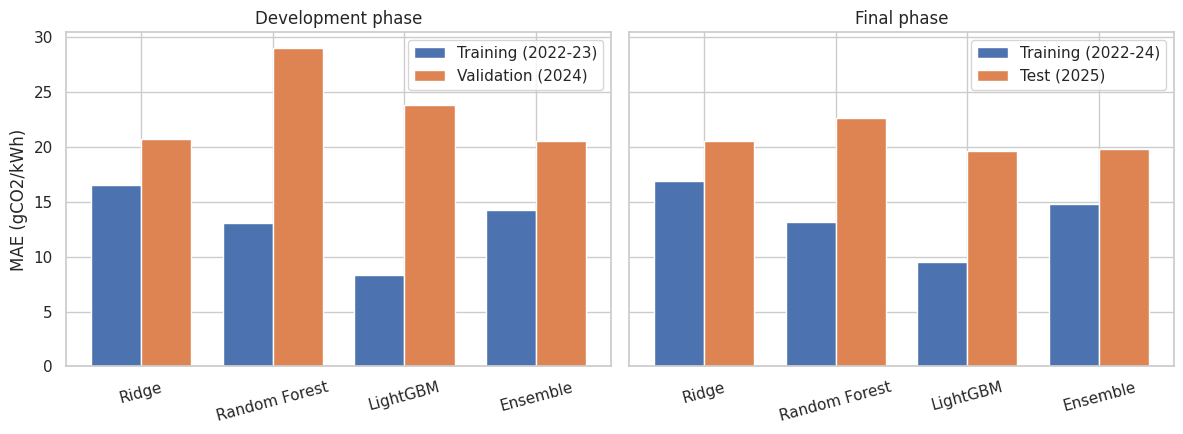

In [18]:
#  Development phase: models trained on 2022-2023 
# Ridge and LightGBM from Step 10 (best_ridge, best_lgbm). Random Forest is fitted again here.
rf_dev = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.3,
                               n_jobs=-1, random_state=SEED)
rf_dev.fit(X.loc[tr, ALL], Y[tr])

dev_train = {   # predictions on the training days
    "Ridge": best_ridge.predict(X.loc[tr, ALL]),
    "Random Forest": rf_dev.predict(X.loc[tr, ALL]),
    "LightGBM": best_lgbm.predict(Xl_tr).reshape(-1, HORIZON),
}
dev_train["Ensemble"] = 0.8 * dev_train["Ridge"] + 0.2 * dev_train["LightGBM"]

dev_val = {     # predictions on the validation days (2024)
    "Ridge": P_ridge_va,
    "Random Forest": rf_dev.predict(X.loc[va_c, ALL]),
    "LightGBM": P_lgbm_va,
}
dev_val["Ensemble"] = 0.8 * P_ridge_va + 0.2 * P_lgbm_va

#  Final phase: models trained on 2022-2024 
fin_train = {
    "Ridge": final_ridge.predict(X.loc[train_full, ALL]),
    "Random Forest": final_rf.predict(X.loc[train_full, ALL]),
    "LightGBM": final_lgbm.predict(Xl_full).reshape(-1, HORIZON),
}
fin_train["Ensemble"] = 0.8 * fin_train["Ridge"] + 0.2 * fin_train["LightGBM"]

fin_test = {
    "Ridge": PRED_TE["Ridge"],
    "Random Forest": PRED_TE["Random Forest"],
    "LightGBM": PRED_TE["LightGBM"],
    "Ensemble": PRED_TE[FINAL_NAME],
}

#  Table 
rows = []
for m in ["Ridge", "Random Forest", "LightGBM", "Ensemble"]:
    tr1 = scores(dev_train[m], Y[tr])["MAE"]
    va1 = scores(dev_val[m], Y[va_c])["MAE"]
    tr2 = scores(fin_train[m], Y[train_full])["MAE"]
    te2 = scores(fin_test[m], A_te)["MAE"]
    rows.append({"model": m,
                 "train MAE (2022-23)": tr1, "validation MAE (2024)": va1, "gap 1": va1 - tr1,
                 "train MAE (2022-24)": tr2, "test MAE (2025)": te2, "gap 2": te2 - tr2})
over = pd.DataFrame(rows).set_index("model")
print("Training vs validation vs test error (gap = new-data error minus training error):")
display(over.round(2))

#  Text summary 
for m, r in over.iterrows():
    print(f"{m}: training {r['train MAE (2022-24)']:.1f} -> test {r['test MAE (2025)']:.1f} "
          f"(test is {r['test MAE (2025)'] / r['train MAE (2022-24)']:.1f} times the training error)")

#  Picture 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
x = np.arange(len(over)); w = 0.38
axes[0].bar(x - w / 2, over["train MAE (2022-23)"], w, label="Training (2022-23)")
axes[0].bar(x + w / 2, over["validation MAE (2024)"], w, label="Validation (2024)")
axes[0].set_title("Development phase")
axes[1].bar(x - w / 2, over["train MAE (2022-24)"], w, label="Training (2022-24)")
axes[1].bar(x + w / 2, over["test MAE (2025)"], w, label="Test (2025)")
axes[1].set_title("Final phase")
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(over.index, rotation=15)
    ax.legend()
axes[0].set_ylabel(f"MAE ({UNIT})")
plt.tight_layout()
plt.show()

**Observation.** Ridge overfits the least: training MAE 16.93 and test MAE 20.55 (gap 3.62). LightGBM (9.52 vs 19.65) and Random Forest (13.14 vs 22.65) have bigger gaps, 10.13 and 9.51. The ensemble is in the middle (14.79 vs 19.81, gap 5.02) and has almost the lowest test error. In the development phase the tree models had a gap of about 15.5 to 15.9 (2022-2023 training, 2024 validation); it became smaller after 2024 was added to the training data, because 2024 is closer to 2025.

## Step 11c: More metrics and "is the difference real?" tests (2025 test)

R squared (R2) shows how much of the ups and downs of carbon intensity the model explains (1 is perfect, 0 is no better than always predicting the average).
Skill score shows how much better a model is than a simple baseline (in percent).
Some models have very close MAE values. To know if a difference is real or just luck, we compare two models on the same days
and build a 95% confidence interval for the difference. If the interval does not include 0, the difference is real.

More metrics on the 2025 test days:


,model,R2,correlation,MAE,MAE skill vs Yesterday (%),RMSE skill vs Yesterday (%)
0,NESO (reference),0.953,0.979,9.195,76.343,75.384
1,LightGBM (per-slot),0.807,0.909,18.936,51.280,49.955
2,LightGBM,0.797,0.899,19.649,49.447,48.756
3,Ensemble (80% Ridge + 20% LightGBM),0.795,0.902,19.807,49.039,48.481
4,Ridge,0.778,0.895,20.549,47.129,46.438
5,Random Forest,0.735,0.866,22.654,41.714,41.426
6,Yesterday,0.227,0.613,38.867,0.000,0.000
7,7-day average,0.170,0.472,42.076,-8.256,-3.648



Paired comparison (negative difference = first model has lower error):


,first model,second model,MAE difference,CI low,CI high,result
0,Ensemble (80% Ridge + 20% LightGBM),Ridge,-0.74,-0.95,-0.55,first model is clearly better
1,Ensemble (80% Ridge + 20% LightGBM),LightGBM,0.16,-0.57,0.92,no clear difference
2,Ensemble (80% Ridge + 20% LightGBM),Random Forest,-2.85,-3.92,-1.72,first model is clearly better
3,Ensemble (80% Ridge + 20% LightGBM),LightGBM (per-slot),0.87,0.25,1.51,first model is clearly worse
4,LightGBM,Ridge,-0.90,-1.84,0.02,no clear difference
5,Ensemble (80% Ridge + 20% LightGBM),Yesterday,-19.06,-21.33,-16.77,first model is clearly better


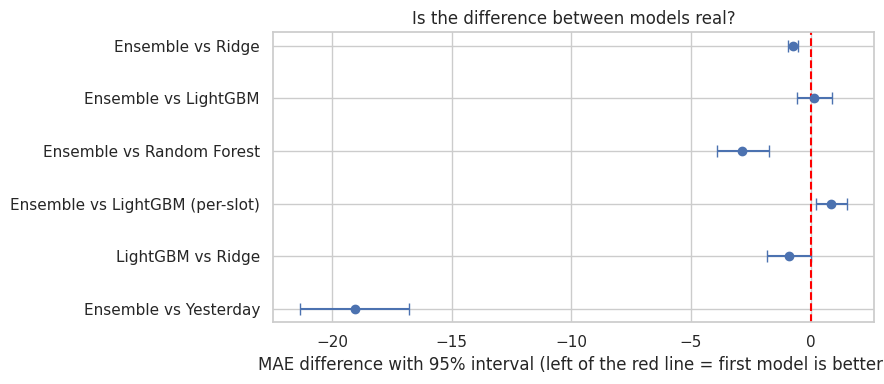

In [19]:
# R2 = 1 - (squared errors of the model) / (squared distance of the real values from their average)
def r2_simple(P, A):
    P, A = to_np(P), to_np(A)
    return 1 - ((A - P) ** 2).sum() / ((A - A.mean()) ** 2).sum()

#  Table: R2, correlation and skill scores for every model 
rmse_yday = scores(PRED_TE["Yesterday"], A_te)["RMSE"]
rows = []
for name, P in PRED_TE.items():
    s = scores(P, A_te)
    rows.append({"model": name,
                 "R2": r2_simple(P, A_te),
                 "correlation": np.corrcoef(to_np(P).ravel(), A_te.ravel())[0, 1],
                 "MAE": s["MAE"],
                 "MAE skill vs Yesterday (%)": 100 * (1 - s["MAE"] / mae_yday),
                 "RMSE skill vs Yesterday (%)": 100 * (1 - s["RMSE"] / rmse_yday)})
more = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
print("More metrics on the 2025 test days:")
display(more.round(3))

#  Is the difference between two models real? 
pairs = [
    (FINAL_NAME, "Ridge"),
    (FINAL_NAME, "LightGBM"),
    (FINAL_NAME, "Random Forest"),
    (FINAL_NAME, "LightGBM (per-slot)"),
    ("LightGBM", "Ridge"),
    (FINAL_NAME, "Yesterday"),
]
rows = []
for a, b in pairs:
    d, lo, hi = boot_paired_diff(PRED_TE[a], PRED_TE[b], A_te)   # MAE(a) minus MAE(b)
    if hi < 0:
        verdict = "first model is clearly better"
    elif lo > 0:
        verdict = "first model is clearly worse"
    else:
        verdict = "no clear difference"
    rows.append({"first model": a, "second model": b, "MAE difference": d, "CI low": lo, "CI high": hi, "result": verdict})
sig = pd.DataFrame(rows)
print("\nPaired comparison (negative difference = first model has lower error):")
display(sig.round(2))

#  Picture 
fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{a.split(' (')[0]} vs {b}" for a, b in pairs]
y = np.arange(len(sig))
ax.errorbar(sig["MAE difference"], y,
            xerr=[sig["MAE difference"] - sig["CI low"], sig["CI high"] - sig["MAE difference"]],
            fmt="o", capsize=4)
ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set(xlabel="MAE difference with 95% interval (left of the red line = first model is better)",
       title="Is the difference between models real?")
plt.tight_layout()
plt.show()

**Observation.** On the 2025 test days the ensemble has R2 = 0.795 (it explains about 80% of the ups and downs of carbon intensity) and correlation 0.90, compared with R2 = 0.227 for the Yesterday baseline. The paired comparison shows that the ensemble is clearly better than Ridge (MAE difference -0.74, 95% CI -0.95 to -0.55), Random Forest (-2.85) and the Yesterday baseline (-19.06). There is no clear difference between the ensemble and pooled LightGBM (+0.16, CI -0.57 to 0.92). Per-slot LightGBM is slightly but significantly better than the ensemble (0.87, CI 0.25 to 1.51), but we keep the ensemble because it was chosen on validation data and was more stable in cross-validation.

## Step 12: RQ1 confidence interval and RQ2 - error across the 48 half-hour steps

We use bootstrap: we re-sample the test days many times to get a 95% confidence interval.
RQ2 asks how the error changes from the first half-hour (00:00) to the last (23:30) of the forecast day.

Final model MAE: 19.81  (95% CI 18.74 to 20.84)
Yesterday MAE:   38.87  (95% CI 36.62 to 41.17)
Difference (final - Yesterday): -19.06  (95% CI -21.33 to -16.77)  -> negative means final is better

MAE by 3-hour block of the forecast day:


,time block,final model MAE,Yesterday MAE
0,00:00 to 02:30,6.21,37.22
1,03:00 to 05:30,13.21,39.58
2,06:00 to 08:30,19.66,40.56
3,09:00 to 11:30,22.52,36.13
4,12:00 to 14:30,23.36,35.28
5,15:00 to 17:30,21.23,38.99
6,18:00 to 20:30,23.35,42.09
7,21:00 to 23:30,28.92,41.09


5 best half-hours:


,mae,lo,hi
00:00,3.65,3.37,3.98
00:30,4.88,4.53,5.26
01:00,5.78,5.36,6.27
01:30,6.66,6.13,7.29
02:00,7.68,7.07,8.38


5 worst half-hours:


,mae,lo,hi
21:30,28.45,26.45,30.53
22:00,28.80,26.78,30.89
22:30,29.53,27.38,31.84
23:00,29.57,27.39,31.81
23:30,29.69,27.52,31.95


First half-hour (00:00): MAE = 3.65
Last half-hour (23:30):  MAE = 29.69
Lowest MAE: 3.65 | Highest MAE: 29.69


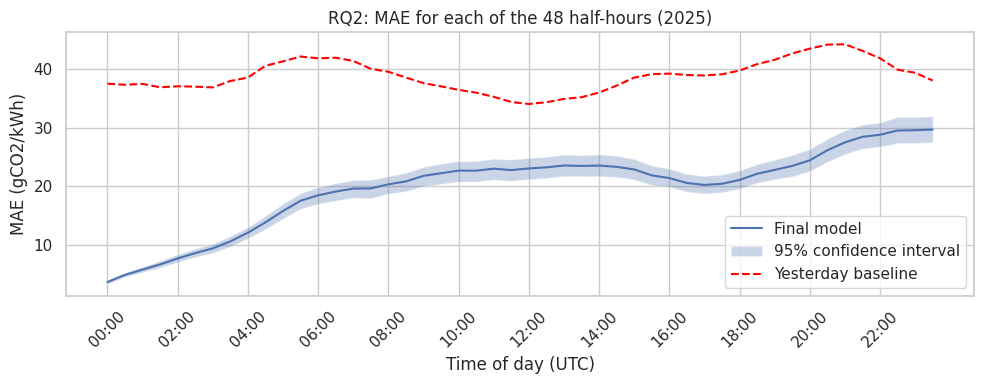

In [20]:
final_P = PRED_TE[FINAL_NAME]
yday_P = PRED_TE["Yesterday"]

#  RQ1: MAE with 95% confidence interval 
m, lo, hi = boot_mean_ci(day_mae(final_P, A_te))
print(f"Final model MAE: {m:.2f}  (95% CI {lo:.2f} to {hi:.2f})")
m0, lo0, hi0 = boot_mean_ci(day_mae(yday_P, A_te))
print(f"Yesterday MAE:   {m0:.2f}  (95% CI {lo0:.2f} to {hi0:.2f})")
d, dlo, dhi = boot_paired_diff(final_P, yday_P, A_te)
print(f"Difference (final - Yesterday): {d:.2f}  (95% CI {dlo:.2f} to {dhi:.2f})  -> negative means final is better")

#  RQ2: MAE for each of the 48 half-hours 
slot_ci = boot_slot_ci(final_P, A_te)
yday_slot = slot_mae(yday_P, A_te)
times = [f"{k // 2:02d}:{'30' if k % 2 else '00'}" for k in range(HORIZON)]
slot_ci.index = times

# Summary for each 3-hour block (so the table is short)
rows = []
for b in range(8):
    sl = slice(6 * b, 6 * b + 6)
    rows.append({"time block": f"{times[6 * b]} to {times[6 * b + 5]}",
                 "final model MAE": slot_ci["mae"].iloc[sl].mean(),
                 "Yesterday MAE": yday_slot[sl].mean()})
block_tbl = pd.DataFrame(rows)
print("\nMAE by 3-hour block of the forecast day:")
display(block_tbl.round(2))

print("5 best half-hours:")
display(slot_ci.sort_values("mae").head(5).round(2))
print("5 worst half-hours:")
display(slot_ci.sort_values("mae").tail(5).round(2))

print(f"First half-hour (00:00): MAE = {slot_ci['mae'].iloc[0]:.2f}")
print(f"Last half-hour (23:30):  MAE = {slot_ci['mae'].iloc[-1]:.2f}")
print(f"Lowest MAE: {slot_ci['mae'].min():.2f} | Highest MAE: {slot_ci['mae'].max():.2f}")

#  Plot 
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(HORIZON)
ax.plot(x, slot_ci["mae"], label="Final model")
ax.fill_between(x, slot_ci["lo"], slot_ci["hi"], alpha=0.3, label="95% confidence interval")
ax.plot(x, yday_slot, linestyle="--", color="red", label="Yesterday baseline")
ax.set_xticks(range(0, HORIZON, 4))
ax.set_xticklabels(times[::4], rotation=45)
ax.set(xlabel="Time of day (UTC)", ylabel=f"MAE ({UNIT})", title="RQ2: MAE for each of the 48 half-hours (2025)")
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** RQ1: the final MAE is 19.81 (95% CI 18.74 to 20.84) and the Yesterday baseline has 38.87 (CI 36.62 to 41.17); the difference is -19.06 (CI -21.33 to -16.77), so the improvement is real. RQ2: the error grows with the forecast time. MAE is 3.65 at 00:00 and 29.69 at 23:30. By 3-hour block it goes from 6.21 (00:00-02:30) to 28.92 (21:00-23:30), while the Yesterday baseline stays between 35 and 42 all day. This is expected because the model knows the end of the previous day, which helps the first hours the most.

## Step 13: RQ3 - Historical weather vs one-day-ahead weather forecast

Our model was trained with historical weather (what really happened). In real life we only have a weather FORECAST made one day before.
To see how much this matters, we test the same trained model on 2025 twice:
- A: with historical weather
- B: with the one-day-ahead forecast weather (Open-Meteo Previous Runs)
Only the weather of the target day (wx_tgt) is swapped. Yesterday's weather stays the same because it was already observed.

First we download the forecast weather and check that it looks correct.

In [21]:
import requests, time

URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
PLACES = {"london": (51.51, -0.13), "scotland": (55.95, -3.19), "east_coast": (52.90, 1.30)}

# previous_day1 = the forecast that was made one day before
hourly_names = ",".join(f"{v}_previous_day1" for v in MODEL_WX)

def get_forecast(lat, lon):
    params = {"latitude": lat, "longitude": lon,
              "start_date": "2025-01-01", "end_date": "2025-12-31",
              "hourly": hourly_names, "timezone": "UTC"}
    for attempt in range(5):                       # try up to 5 times
        r = requests.get(URL, params=params, timeout=60)
        if r.status_code == 200:
            break
        print("Problem:", r.status_code, r.text[:200])
        time.sleep(10 * (attempt + 1))             # wait and try again
    else:
        raise RuntimeError("Could not download the forecast data")
    d = pd.DataFrame(r.json()["hourly"])
    d["time"] = pd.to_datetime(d["time"], utc=True)
    return d.set_index("time")

#  Use the saved file if it exists, otherwise download 
SAVED_FC = f"{FOLDER}/previous_day1_2025.csv"
if os.path.exists(SAVED_FC):
    wx_fc = pd.read_csv(SAVED_FC)
    wx_fc["time"] = pd.to_datetime(wx_fc["time"], utc=True)
    wx_fc = wx_fc.set_index("time")
    print("Loaded the saved forecast file:", wx_fc.shape)
else:
    frames = []
    for loc, (lat, lon) in PLACES.items():
        d = get_forecast(lat, lon)
        d.columns = [c.replace("_previous_day1", f"_{loc}") for c in d.columns]   # same names as in df
        frames.append(d)
        print("Downloaded:", loc, d.shape)
    wx_fc = pd.concat(frames, axis=1)
    wx_fc.to_csv("/kaggle/working/previous_day1_2025.csv")

#  Put it on the 30-minute grid (same method as Part 1) 
grid25 = FULL[FULL >= pd.Timestamp("2025-01-01", tz="UTC")]
wx_fc30 = wx_fc.reindex(grid25, method="ffill")
wcols = [f"{v}_{loc}" for v in MODEL_WX for loc in PLACES]
print("\nMissing values in forecast weather:", int(wx_fc30[wcols].isna().sum().sum()))

#  Check: is the forecast similar to the historical weather
rows = []
for v in MODEL_WX:
    hist = pd.concat([df.loc[grid25, f"{v}_{loc}"] for loc in PLACES])
    fc = pd.concat([wx_fc30[f"{v}_{loc}"] for loc in PLACES])
    rows.append({"variable": v,
                 "mean historical": hist.mean(), "mean forecast": fc.mean(),
                 "average difference (abs)": (hist.to_numpy() - fc.to_numpy()).__abs__().mean(),
                 "correlation": np.corrcoef(hist.to_numpy(), fc.to_numpy())[0, 1]})
display(pd.DataFrame(rows).round(2))

Downloaded: london (8760, 4)
Downloaded: scotland (8760, 4)
Downloaded: east_coast (8760, 4)

Missing values in forecast weather: 0


,variable,mean historical,mean forecast,average difference (abs),correlation
0,wind_speed_10m,13.66,14.05,2.46,0.88
1,cloud_cover,67.43,62.27,20.62,0.65
2,temperature_2m,11.43,11.51,0.78,0.99
3,shortwave_radiation,110.27,118.64,31.20,0.92


**Observation.** The one-day-ahead forecast weather for 2025 has no missing values and is similar to the historical weather: the correlation is 0.99 for temperature, 0.92 for solar radiation, 0.88 for wind speed and 0.65 for cloud cover (cloud cover is the hardest to forecast).

Number of columns swapped: 48
Other columns unchanged: True
Average size of change in swapped columns: 9.64
Check: A predictions match the earlier test result: True

RQ3 results on 2025 (positive difference = forecast weather is worse):


,model,MAE historical (A),MAE forecast (B),difference (B - A),CI low,CI high
0,Ridge,20.55,20.05,-0.50,-0.96,0.01
1,LightGBM,19.65,19.24,-0.41,-0.90,0.08
2,Final ensemble,19.81,19.27,-0.54,-1.00,-0.06


Ridge with NO target-day weather: MAE = 28.43
Ridge with historical weather:    MAE = 20.55
Ridge with forecast weather:      MAE = 20.05


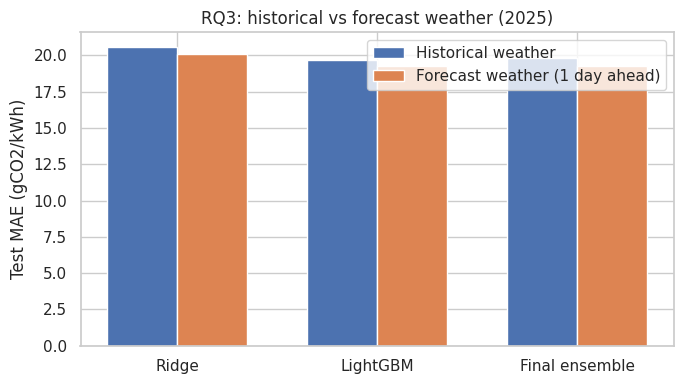

In [22]:
#  Step 1: make 2025 features again, but with FORECAST weather 
df_fc = df.copy()
df_fc.loc[grid25, wcols] = wx_fc30[wcols]      # replace 2025 weather with forecast weather
X_fc = build_features(df_fc)

# Only the "target day weather" columns (wx_tgt) will change
WX_TGT = [c for c in ALL if c.startswith("wx_tgt")]
X_te_A = X.loc[te_c, ALL].copy()               # A: historical weather
X_te_B = X_te_A.copy()                         # B: same, but wx_tgt from the forecast
X_te_B[WX_TGT] = X_fc.loc[te_c, WX_TGT]

print("Number of columns swapped:", len(WX_TGT))
print("Other columns unchanged:", bool((X_te_A.drop(columns=WX_TGT) == X_te_B.drop(columns=WX_TGT)).all().all()))
print("Average size of change in swapped columns:", round(float((X_te_A[WX_TGT] - X_te_B[WX_TGT]).abs().mean().mean()), 2))

#  Step 2: make the long table for LightGBM (same method as before) 
def make_long_from(Xsrc):
    n = len(Xsrc)
    Xl = pd.DataFrame(np.repeat(Xsrc[DAY_COLS].to_numpy(), HORIZON, axis=0), columns=DAY_COLS)
    Xl["step"] = np.tile(np.arange(HORIZON), n)
    for prefix, new_name in STEP_COLS.items():
        vals = Xsrc[[f"{prefix}{s}" for s in range(HORIZON)]].to_numpy()
        Xl[new_name] = vals.reshape(-1)
    return Xl

#  Step 3: predict with the SAME trained models 
def predict_all(Xsrc):
    p_ridge = final_ridge.predict(Xsrc[ALL])
    p_lgbm = final_lgbm.predict(make_long_from(Xsrc)).reshape(-1, HORIZON)
    return {"Ridge": p_ridge, "LightGBM": p_lgbm, "Final ensemble": 0.8 * p_ridge + 0.2 * p_lgbm}

PA = predict_all(X_te_A)       # historical weather
PB = predict_all(X_te_B)       # forecast weather
print("Check: A predictions match the earlier test result:", bool(np.allclose(PA["Final ensemble"], PRED_TE[FINAL_NAME])))

#  Step 4: compare A and B 
rows = []
for name in PA:
    mA = scores(PA[name], A_te)["MAE"]
    mB = scores(PB[name], A_te)["MAE"]
    d, lo, hi = boot_paired_diff(PB[name], PA[name], A_te)    # MAE(B) - MAE(A), positive = forecast is worse
    rows.append({"model": name, "MAE historical (A)": mA, "MAE forecast (B)": mB,
                 "difference (B - A)": d, "CI low": lo, "CI high": hi})
rq3_tbl = pd.DataFrame(rows)
print("\nRQ3 results on 2025 (positive difference = forecast weather is worse):")
display(rq3_tbl.round(2))

#  Step 5: for comparison, a model with NO target-day weather at all 
cols_nowx = [c for c in ALL if not c.startswith("wx_tgt")]
ridge_nowx = make_pipeline(StandardScaler(), Ridge(alpha=31.62))
ridge_nowx.fit(X.loc[train_full, cols_nowx], Y[train_full])
mae_nowx = scores(ridge_nowx.predict(X.loc[te_c, cols_nowx]), A_te)["MAE"]
print(f"Ridge with NO target-day weather: MAE = {mae_nowx:.2f}")
print(f"Ridge with historical weather:    MAE = {rq3_tbl.loc[0, 'MAE historical (A)']:.2f}")
print(f"Ridge with forecast weather:      MAE = {rq3_tbl.loc[0, 'MAE forecast (B)']:.2f}")

#  Step 6: simple bar chart 
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(rq3_tbl)); w = 0.35
ax.bar(x - w / 2, rq3_tbl["MAE historical (A)"], w, label="Historical weather")
ax.bar(x + w / 2, rq3_tbl["MAE forecast (B)"], w, label="Forecast weather (1 day ahead)")
ax.set_xticks(x); ax.set_xticklabels(rq3_tbl["model"])
ax.set(ylabel=f"Test MAE ({UNIT})", title="RQ3: historical vs forecast weather (2025)")
ax.legend()
plt.tight_layout()
plt.show()

# keep the forecast-weather predictions for the next steps
FINAL_FC = PB["Final ensemble"]

**Observation.** RQ3: replacing the historical weather by the one-day-ahead forecast did not make the model worse. The MAE of the final ensemble was 19.81 with historical weather and 19.27 with forecast weather (difference -0.54, 95% CI -1.00 to -0.06). For Ridge (20.55 vs 20.05) and LightGBM (19.65 vs 19.24) the intervals include 0. So the effect is very small and we cannot say that forecast weather is better; we can only say that it is not worse. A possible reason is that our "historical" weather also comes from a weather-model API (Open-Meteo Historical Forecast), so it is close to the forecast data; this is a limitation. Weather itself is very important: Ridge without any target-day weather has MAE 28.43, compared with 20.05 with forecast weather.

## Step 14: RQ4 - Recommending the best 3-hour window

For each day of 2025, we use the predictions to pick the 3-hour window (6 half-hours) with the lowest predicted carbon intensity.
There are 43 possible windows in a day. Then we check how good the chosen window really was.
- Regret: how much higher the chosen window was compared to the truly best window (lower is better).
- Reduction: how much lower the chosen window was compared to the average window of that day (higher is better).
- Hit rate: percentage of days when the chosen start time was within 1 hour of the best start time.
We compare our model with the baselines. "Perfect (oracle)" uses the real values, so it must give regret 0 and hit rate 100% (a safety check).

RQ4 results on 2025 (regret: lower is better | reduction and hit rate: higher is better):


,method,regret,reduction,hit rate (%)
0,Final model (historical weather),5.82,38.50,58.73
1,Final model (forecast weather),6.10,38.22,57.62
2,Yesterday baseline,21.72,22.60,31.02
3,7-day average baseline,14.36,29.96,44.04
4,NESO (reference),2.27,42.05,81.16
5,Perfect (oracle),0.00,44.32,100.00



Regret difference (final model - baseline). Negative = final model has less regret:
  vs Yesterday baseline: -15.91  (95% CI -19.21 to -12.83)
  vs 7-day average baseline: -8.54  (95% CI -11.44 to -5.96)

Most common start times chosen by the final model:
pick
00:00    83
21:00    58
11:00    54
10:30    38
00:30    31

Most common start times of the truly best window:
best
21:00    59
00:00    47
11:00    40
11:30    30
00:30    24


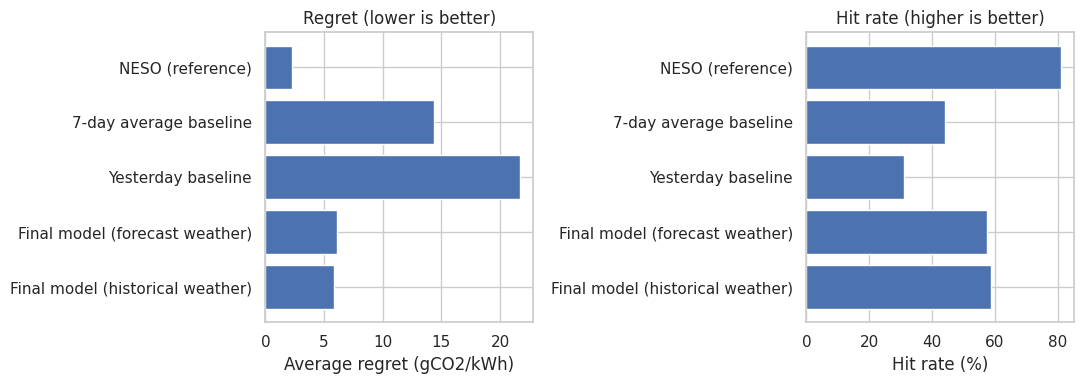

In [23]:
# All the predictions we want to compare (361 test days of 2025)
CANDIDATES = {
    "Final model (historical weather)": PRED_TE[FINAL_NAME],
    "Final model (forecast weather)": FINAL_FC,
    "Yesterday baseline": PRED_TE["Yesterday"],
    "7-day average baseline": PRED_TE["7-day average"],
    "NESO (reference)": PRED_TE["NESO (reference)"],
    "Perfect (oracle)": A_te,
}

#  Window results for every method 
WIN = {}
rows = []
for name, P in CANDIDATES.items():
    w = window_eval(P, A_te)
    WIN[name] = w
    s = window_summary(w)
    rows.append({"method": name, "regret": s["regret"], "reduction": s["reduction"],
                 "hit rate (%)": 100 * s["hit_rate"]})
win_tbl = pd.DataFrame(rows)
print("RQ4 results on 2025 (regret: lower is better | reduction and hit rate: higher is better):")
display(win_tbl.round(2))

#  Is our model better than the baselines? (95% confidence interval) 
mine = WIN["Final model (historical weather)"]["regret"].to_numpy()
print("\nRegret difference (final model - baseline). Negative = final model has less regret:")
for base in ["Yesterday baseline", "7-day average baseline"]:
    d, lo, hi = boot_mean_ci(mine - WIN[base]["regret"].to_numpy())
    print(f"  vs {base}: {d:.2f}  (95% CI {lo:.2f} to {hi:.2f})")

#  Which start times are chosen most? 
print("\nMost common start times chosen by the final model:")
print(WIN["Final model (historical weather)"]["pick"].map(lambda i: times[i]).value_counts().head(5).to_string())
print("\nMost common start times of the truly best window:")
print(WIN["Final model (historical weather)"]["best"].map(lambda i: times[i]).value_counts().head(5).to_string())

#  Plot (numbers are already in the table above) 
show = win_tbl[win_tbl["method"] != "Perfect (oracle)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(show["method"], show["regret"])
axes[0].set(xlabel=f"Average regret ({UNIT})", title="Regret (lower is better)")
axes[1].barh(show["method"], show["hit rate (%)"])
axes[1].set(xlabel="Hit rate (%)", title="Hit rate (higher is better)")
plt.tight_layout()
plt.show()

**Observation.** RQ4: the final model chooses a much better 3-hour window than the baselines. Average regret is 5.82 gCO2/kWh, compared with 21.72 (Yesterday) and 14.36 (7-day average); the differences are -15.91 (CI -19.21 to -12.83) and -8.54 (CI -11.44 to -5.96). The hit rate (start within 1 hour of the best start) is 58.7%, compared with 31.0% and 44.0%. The chosen window is 38.5 gCO2/kWh lower than an average window, which is about 87% of the best possible reduction (44.3). With forecast weather the results are almost the same (regret 6.10, hit rate 57.6%). The NESO forecast is better (regret 2.27, hit rate 81.2%), but it has a different time horizon. The perfect (oracle) row has regret 0 and hit rate 100%, which confirms that the evaluation code is correct.

## Step 15: Robustness - windy vs calm days, seasons, weekdays and years

We check if the final model works well in different situations (2025 test days).
- Windy days: days with average wind speed above the median. Calm days: below the median.
- Seasons: Winter (Dec-Feb), Spring (Mar-May), Summer (Jun-Aug), Autumn (Sep-Nov).
- Years: validation 2024 (model trained on 2022-2023) and test 2025 (model trained on 2022-2024).

Median daily wind speed in 2025: 12.91 km/h

Results on 2025 test days by group:


,group type,group,days,mean actual CI,Yesterday MAE,final model MAE,final model bias,window regret
0,Wind,Windy,180,96.82,38.81,21.31,10.58,6.10
1,Wind,Calm,181,160.82,38.92,18.31,4.76,5.54
2,Season,Winter,88,144.63,42.26,21.88,10.00,5.83
3,Season,Spring,92,128.56,40.89,19.66,7.64,5.70
4,Season,Summer,90,117.05,31.82,17.32,5.11,5.49
5,Season,Autumn,91,125.78,40.51,20.41,7.95,6.24
6,Day type,Weekday,259,135.43,39.42,19.61,8.43,5.70
7,Day type,Weekend,102,112.35,37.46,20.30,5.70,6.13


Year to year comparison:


,year,days,mean actual CI,Yesterday MAE,final model MAE,final model bias
0,"2024 (validation, trained 2022-2023)",357,125.31,40.62,20.59,9.16
1,"2025 (test, trained 2022-2024)",361,128.91,38.87,19.81,7.66


3 easiest days (lowest MAE):
  2025-02-12 MAE = 4.1 | mean wind = 12.8
  2025-08-13 MAE = 5.0 | mean wind = 8.3
  2025-07-22 MAE = 5.03 | mean wind = 11.8
3 hardest days (highest MAE):
  2025-02-18 MAE = 60.84 | mean wind = 14.0
  2025-01-01 MAE = 63.28 | mean wind = 23.4
  2025-11-23 MAE = 65.04 | mean wind = 13.1


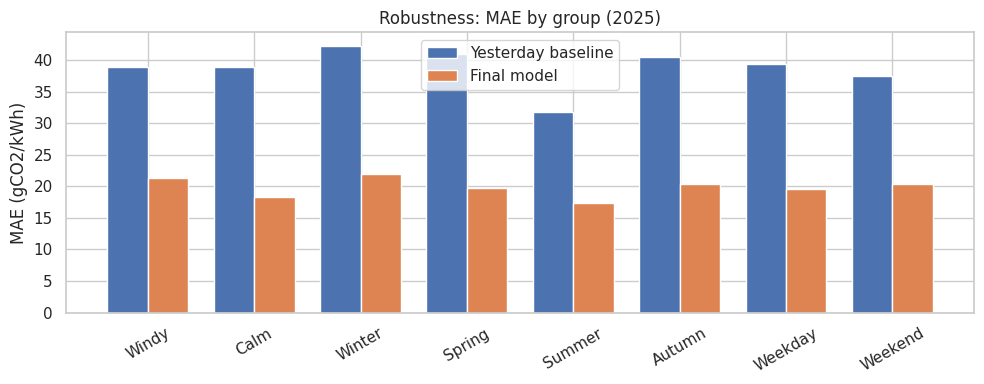

In [24]:
#  Average wind speed of every day (mean of the 3 places) 
wind_cols = [f"wind_speed_10m_{loc}" for loc in LOCATIONS]
wind_day = df[wind_cols].mean(axis=1).groupby(df.index.floor("D")).mean()

test_days = X.index[te_c]
wind_te = wind_day.reindex(test_days)
is_windy = (wind_te > wind_te.median()).to_numpy()
print("Median daily wind speed in 2025:", round(float(wind_te.median()), 2), "km/h")

#  Per-day numbers for the final model 
dm_final = day_mae(final_P, A_te)                      # MAE of each day (final model)
dm_yday = day_mae(yday_P, A_te)                        # MAE of each day (Yesterday)
bias_day = (to_np(final_P) - A_te).mean(axis=1)        # bias of each day
regret_day = WIN["Final model (historical weather)"]["regret"].to_numpy()

#  Groups 
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
GROUP_SETS = {
    "Wind": (np.where(is_windy, "Windy", "Calm"), ["Windy", "Calm"]),
    "Season": (np.array([season_map[m] for m in test_days.month]), ["Winter", "Spring", "Summer", "Autumn"]),
    "Day type": (np.where(test_days.dayofweek >= 5, "Weekend", "Weekday"), ["Weekday", "Weekend"]),
}

rows = []
for set_name, (labels, order) in GROUP_SETS.items():
    for g in order:
        m = labels == g
        rows.append({"group type": set_name, "group": g, "days": int(m.sum()),
                     "mean actual CI": A_te[m].mean(),
                     "Yesterday MAE": dm_yday[m].mean(),
                     "final model MAE": dm_final[m].mean(),
                     "final model bias": bias_day[m].mean(),
                     "window regret": regret_day[m].mean()})
robust_tbl = pd.DataFrame(rows)
print("\nResults on 2025 test days by group:")
display(robust_tbl.round(2))

#  Year to year: 2024 (validation) vs 2025 (test) 
P_va_final = 0.8 * P_ridge_va + 0.2 * P_lgbm_va         # models trained on 2022-2023 only
A_va = to_np(Y[va_c])
P_va_yday = to_np(Y_yday[va_c])
year_tbl = pd.DataFrame([
    {"year": "2024 (validation, trained 2022-2023)", "days": int(va_c.sum()),
     "mean actual CI": A_va.mean(), "Yesterday MAE": scores(P_va_yday, A_va)["MAE"],
     "final model MAE": scores(P_va_final, A_va)["MAE"], "final model bias": scores(P_va_final, A_va)["Bias"]},
    {"year": "2025 (test, trained 2022-2024)", "days": int(te_c.sum()),
     "mean actual CI": A_te.mean(), "Yesterday MAE": scores(yday_P, A_te)["MAE"],
     "final model MAE": scores(final_P, A_te)["MAE"], "final model bias": scores(final_P, A_te)["Bias"]},
])
print("Year to year comparison:")
display(year_tbl.round(2))

#  Best and worst days 
order_days = np.argsort(dm_final)
print("3 easiest days (lowest MAE):")
for i in order_days[:3]:
    print(" ", test_days[i].date(), "MAE =", round(dm_final[i], 2), "| mean wind =", round(float(wind_te.iloc[i]), 1))
print("3 hardest days (highest MAE):")
for i in order_days[-3:]:
    print(" ", test_days[i].date(), "MAE =", round(dm_final[i], 2), "| mean wind =", round(float(wind_te.iloc[i]), 1))

#  Plot (numbers are in the table above) 
labels_plot = robust_tbl["group"]
x = np.arange(len(robust_tbl)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w / 2, robust_tbl["Yesterday MAE"], w, label="Yesterday baseline")
ax.bar(x + w / 2, robust_tbl["final model MAE"], w, label="Final model")
ax.set_xticks(x); ax.set_xticklabels(labels_plot, rotation=30)
ax.set(ylabel=f"MAE ({UNIT})", title="Robustness: MAE by group (2025)")
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** The model is better than the Yesterday baseline in every group. Windy days are harder (MAE 21.31, bias +10.58) than calm days (18.31, bias +4.76). This may be because the model does not fully capture how much strong wind lowers carbon intensity, but we did not test this. Winter is the hardest season (21.88) and summer the easiest (17.32). Weekdays and weekends are similar (19.61 and 20.30). The model MAE is 20.59 in 2024 and 19.81 in 2025, even though the average carbon intensity changed, so the error was stable across years. The hardest days (2025-11-23, 2025-01-01 and 2025-02-18) have MAE above 60.

## Step 16: Visualizations - predictions, error distribution and feature importance

1. Predicted vs actual for three test days: the easiest day, a typical day and the hardest day.
2. How the errors are spread over all test days.
3. Which feature groups matter most for the models (Ridge coefficients and LightGBM gain).

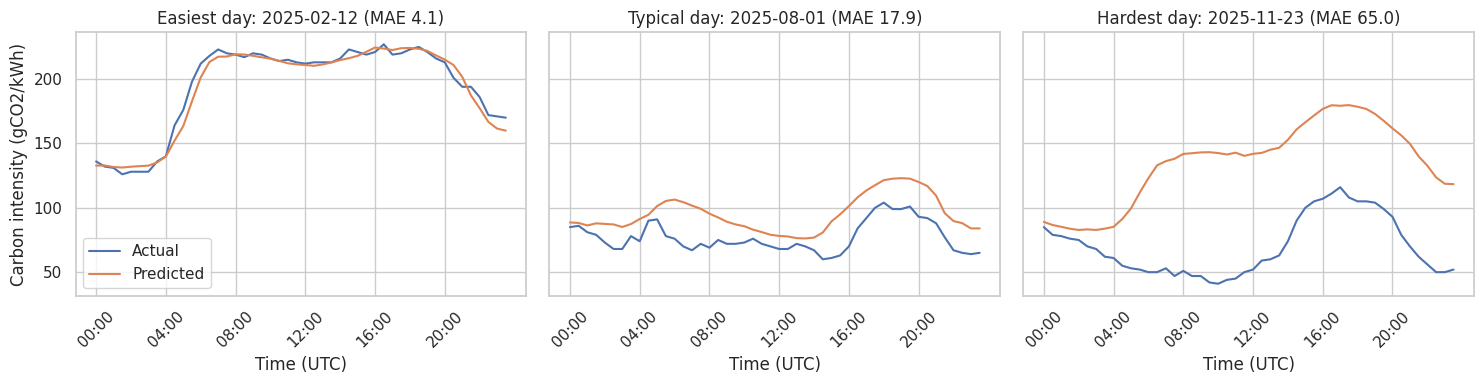


Easiest day: 2025-02-12 (day MAE 4.10)


time,00:00,03:00,06:00,09:00,12:00,15:00,18:00,21:00
actual,136.0,128.0,212.0,220.0,212.0,221.0,223.0,194.0
predicted,132.8,132.7,201.3,218.1,210.9,218.0,224.1,201.7
error,-3.2,4.7,-10.7,-1.9,-1.1,-3.0,1.1,7.7



Typical day: 2025-08-01 (day MAE 17.91)


time,00:00,03:00,06:00,09:00,12:00,15:00,18:00,21:00
actual,85.0,68.0,76.0,72.0,68.0,61.0,104.0,88.0
predicted,88.6,85.1,106.4,89.2,78.1,89.4,121.5,109.5
error,3.6,17.1,30.4,17.2,10.1,28.4,17.5,21.5



Hardest day: 2025-11-23 (day MAE 65.04)


time,00:00,03:00,06:00,09:00,12:00,15:00,18:00,21:00
actual,85.0,68.0,50.0,47.0,52.0,100.0,105.0,70.0
predicted,89.1,82.8,123.0,143.0,141.9,166.4,178.5,149.7
error,4.1,14.8,73.0,96.0,89.9,66.4,73.5,79.7



Half-hour errors (predicted - actual), percentiles:
{5: -33.1, 25: -7.1, 50: 6.3, 75: 22.3, 95: 50.2}
Share of half-hours with error inside +-10: 36.0 %
Share of half-hours with error inside +-20: 60.2 %
Share of DAYS with day MAE below 10: 11.9 %
Share of DAYS with day MAE below 20: 60.7 %
Share of DAYS with day MAE below 30: 86.4 %


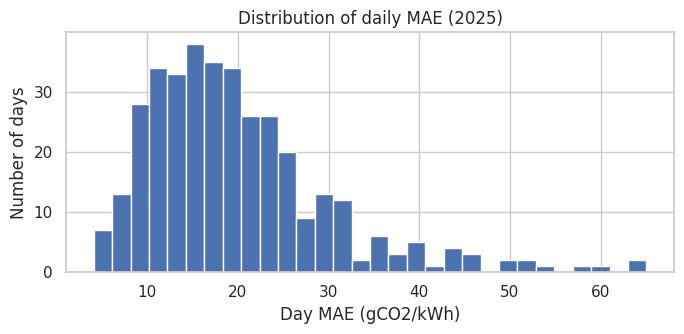


Importance of each feature group (each column adds up to 100%):


,Ridge (%),LightGBM (%)
ci_prev,4.2,51.7
wx_tgt,29.0,22.2
step,0.0,7.5
ci_lag1d,24.0,5.5
ci_avg7d,13.8,4.6
calendar,6.4,3.3
gen_prev,4.8,2.5
wx_prev,5.4,2.3
ci_lag7d,12.3,0.3


Top 10 single features in LightGBM (share of total gain):
ci_prev_last                           47.9
step                                    7.5
lag1d_now                               5.5
avg7d_now                               4.6
wx_tgt_wind_speed_10m_east_coast_b2     4.2
ci_prev_min                             3.1
wx_tgt_wind_speed_10m_london_b3         3.0
wx_tgt_wind_speed_10m_east_coast_b3     2.5
dow                                     2.4
wx_tgt_wind_speed_10m_scotland_b3       1.7


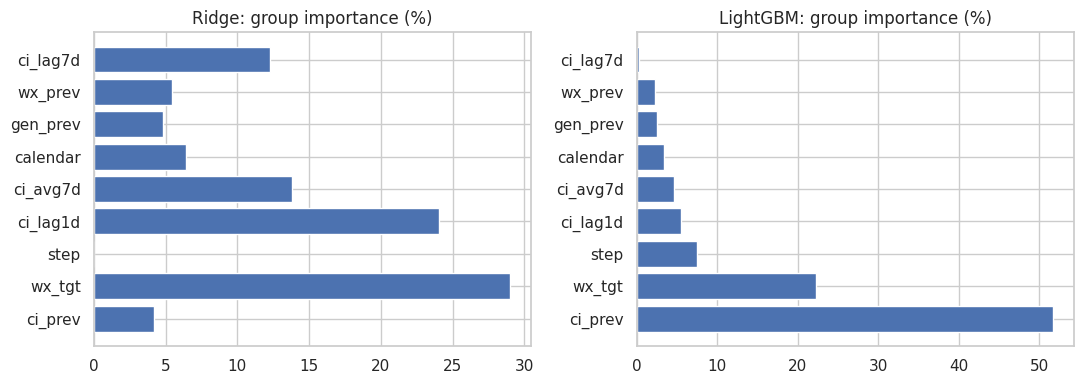

In [25]:
#  1. Predicted vs actual for 3 sample days 
pick_days = {"Easiest day": order_days[0],
             "Typical day": order_days[len(order_days) // 2],
             "Hardest day": order_days[-1]}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, i) in zip(axes, pick_days.items()):
    ax.plot(A_te[i], label="Actual")
    ax.plot(to_np(final_P)[i], label="Predicted")
    ax.set_title(f"{title}: {test_days[i].date()} (MAE {dm_final[i]:.1f})")
    ax.set_xticks(range(0, HORIZON, 8))
    ax.set_xticklabels(times[::8], rotation=45)
    ax.set_xlabel("Time (UTC)")
axes[0].set_ylabel(f"Carbon intensity ({UNIT})")
axes[0].legend()
plt.tight_layout()
plt.show()

# Same information as text: values every 3 hours
for title, i in pick_days.items():
    t = pd.DataFrame({"time": times[::6], "actual": A_te[i][::6], "predicted": to_np(final_P)[i][::6]})
    t["error"] = t["predicted"] - t["actual"]
    print(f"\n{title}: {test_days[i].date()} (day MAE {dm_final[i]:.2f})")
    display(t.round(1).set_index("time").T)

#  2. Error distribution 
err = (to_np(final_P) - A_te).flatten()                       # every half-hour error
print("\nHalf-hour errors (predicted - actual), percentiles:")
print({p: round(float(np.percentile(err, p)), 1) for p in [5, 25, 50, 75, 95]})
print("Share of half-hours with error inside +-10:", round(100 * float((np.abs(err) <= 10).mean()), 1), "%")
print("Share of half-hours with error inside +-20:", round(100 * float((np.abs(err) <= 20).mean()), 1), "%")
print("Share of DAYS with day MAE below 10:", round(100 * float((dm_final < 10).mean()), 1), "%")
print("Share of DAYS with day MAE below 20:", round(100 * float((dm_final < 20).mean()), 1), "%")
print("Share of DAYS with day MAE below 30:", round(100 * float((dm_final < 30).mean()), 1), "%")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(dm_final, bins=30)
ax.set(xlabel=f"Day MAE ({UNIT})", ylabel="Number of days", title="Distribution of daily MAE (2025)")
plt.tight_layout()
plt.show()

#  3. Feature importance by group 
# Ridge: average size of the coefficients (the features were scaled, so they can be compared)
coef = np.abs(final_ridge.named_steps["ridge"].coef_).mean(axis=0)
ridge_imp = pd.Series(coef, index=ALL)
ridge_group = ridge_imp.groupby(groups).sum()
ridge_group = 100 * ridge_group / ridge_group.sum()

# LightGBM: gain importance (how much each feature improved the model)
def group_long(c):
    if c == "step": return "step"
    if c == "lag1d_now": return "ci_lag1d"
    if c == "lag7d_now": return "ci_lag7d"
    if c == "avg7d_now": return "ci_avg7d"
    return group_of(c)

gain = pd.Series(final_lgbm.booster_.feature_importance(importance_type="gain"), index=Xl_full.columns)
lgb_group = gain.groupby({c: group_long(c) for c in gain.index}).sum()
lgb_group = 100 * lgb_group / lgb_group.sum()

imp_tbl = pd.DataFrame({"Ridge (%)": ridge_group, "LightGBM (%)": lgb_group}).fillna(0)
imp_tbl = imp_tbl.sort_values("LightGBM (%)", ascending=False)
print("\nImportance of each feature group (each column adds up to 100%):")
display(imp_tbl.round(1))

print("Top 10 single features in LightGBM (share of total gain):")
print((100 * gain.sort_values(ascending=False).head(10) / gain.sum()).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(imp_tbl.index, imp_tbl["Ridge (%)"]); axes[0].set_title("Ridge: group importance (%)")
axes[1].barh(imp_tbl.index, imp_tbl["LightGBM (%)"]); axes[1].set_title("LightGBM: group importance (%)")
plt.tight_layout()
plt.show()

**Observation.** On the easiest day (2025-02-12, MAE 4.10) the forecast follows the real curve closely. On the hardest day (2025-11-23, MAE 65.04) the real carbon intensity fell to 47-52, but the model predicted 123-143 in the morning. 36.0% of all half-hours have an error within +-10 and 60.2% within +-20. 60.7% of the days have a daily MAE below 20 and 86.4% below 30. In LightGBM the most important single feature is the last value of the previous day (ci_prev_last, 47.9% of the gain), followed by the step number (7.5%) and wind speed forecasts. The Ridge group percentages are only a rough guide, because groups with many columns look larger; the permutation importance below is more reliable.

## Step 16b: Predicted vs actual (scatter) and error by month

Picture 1: every dot is one half-hour of 2025. If the model was perfect, all dots would be on the red diagonal line.
We also group the half-hours by their real value to see where the model makes mistakes (low, middle or high carbon intensity).
Picture 2: the error of the final model for each month of 2025, to see if some months are harder.

Correlation between predicted and actual: 0.902
Best-fit line: predicted = 0.84 x actual + 28.0   (perfect model: 1.00 x actual + 0)
Share of half-hours where the model predicts too high: 62.8%

Error for different real carbon intensity levels (2025):


,half_hours,mean_actual,mean_predicted,bias,MAE
group,,,,,
0-50,854,43.4,61.1,17.7,23.2
50-100,5778,74.2,90.9,16.7,22.5
100-150,4451,125.5,135.7,10.3,18.8
150-200,3933,174.0,172.0,-2.0,17.1
200-250,1957,220.8,212.9,-7.9,18.7
250+,355,262.1,257.8,-4.3,17.5


Error by month (2025):


,MAE,Yesterday MAE,bias,mean actual,mean predicted,days
month,,,,,,
1,23.4,40.2,14.8,167.9,182.7,29
2,24.0,44.3,11.3,147.5,158.8,28
3,21.2,47.0,10.0,146.4,156.4,31
4,19.3,41.8,4.3,133.0,137.3,30
5,18.4,33.9,8.5,106.4,114.9,31
6,18.4,35.9,6.5,98.8,105.3,30
7,17.5,31.5,7.0,129.2,136.2,31
8,16.1,27.9,1.7,123.0,124.7,29
9,18.4,38.5,4.3,112.5,116.8,30


Easiest month: 8 (MAE 16.1) | Hardest month: 2 (MAE 24.0)
Month with the highest bias: 1 (14.8) | lowest bias: 8 (1.7)


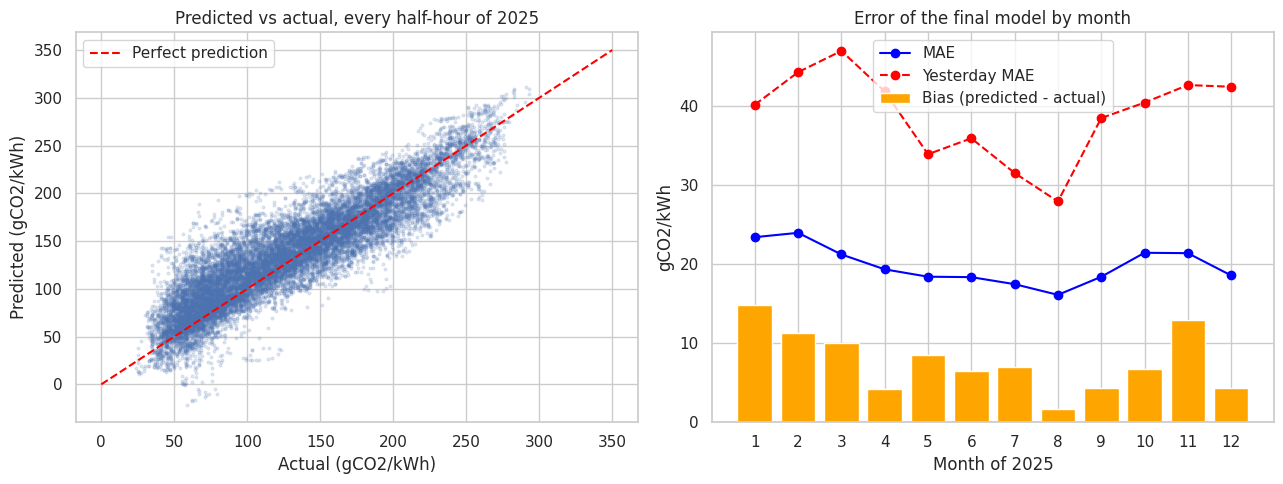

In [26]:
# Final model predictions and real values for the 2025 test days
pred_flat = to_np(final_P).ravel()
act_flat = A_te.ravel()

#  Part 1: scatter plot numbers 
slope, intercept = np.polyfit(act_flat, pred_flat, 1)    # best straight line through the dots
corr = np.corrcoef(act_flat, pred_flat)[0, 1]
print(f"Correlation between predicted and actual: {corr:.3f}")
print(f"Best-fit line: predicted = {slope:.2f} x actual + {intercept:.1f}   (perfect model: 1.00 x actual + 0)")
print(f"Share of half-hours where the model predicts too high: {100 * (pred_flat > act_flat).mean():.1f}%")

#  Part 2: error for different real values 
bins = [0, 50, 100, 150, 200, 250, 400]
bin_names = ["0-50", "50-100", "100-150", "150-200", "200-250", "250+"]
group = pd.cut(act_flat, bins=bins, labels=bin_names)
by_value = pd.DataFrame({"group": group, "actual": act_flat, "predicted": pred_flat})
by_value["error"] = by_value["predicted"] - by_value["actual"]
by_value["abs error"] = by_value["error"].abs()
value_tbl = by_value.groupby("group", observed=True).agg(
    half_hours=("actual", "size"), mean_actual=("actual", "mean"), mean_predicted=("predicted", "mean"),
    bias=("error", "mean"), MAE=("abs error", "mean"))
print("\nError for different real carbon intensity levels (2025):")
display(value_tbl.round(1))

#  Part 3: error by month 
month_df = pd.DataFrame({"month": test_days.month, "MAE": dm_final, "Yesterday MAE": dm_yday,
                         "bias": bias_day, "mean actual": A_te.mean(axis=1),
                         "mean predicted": to_np(final_P).mean(axis=1)})
month_tbl = month_df.groupby("month").mean()
month_tbl["days"] = month_df.groupby("month").size()
print("Error by month (2025):")
display(month_tbl.round(1))
print(f"Easiest month: {int(month_tbl['MAE'].idxmin())} (MAE {month_tbl['MAE'].min():.1f}) | "
      f"Hardest month: {int(month_tbl['MAE'].idxmax())} (MAE {month_tbl['MAE'].max():.1f})")
print(f"Month with the highest bias: {int(month_tbl['bias'].idxmax())} ({month_tbl['bias'].max():.1f}) | "
      f"lowest bias: {int(month_tbl['bias'].idxmin())} ({month_tbl['bias'].min():.1f})")

#  Pictures 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(act_flat, pred_flat, s=4, alpha=0.15)
axes[0].plot([0, 350], [0, 350], color="red", linestyle="--", label="Perfect prediction")
axes[0].set(xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})", title="Predicted vs actual, every half-hour of 2025")
axes[0].legend()

x = np.arange(len(month_tbl))
axes[1].bar(x, month_tbl["bias"], color="orange", label="Bias (predicted - actual)")
axes[1].plot(x, month_tbl["MAE"], color="blue", marker="o", label="MAE")
axes[1].plot(x, month_tbl["Yesterday MAE"], color="red", marker="o", linestyle="--", label="Yesterday MAE")
axes[1].set_xticks(x); axes[1].set_xticklabels(month_tbl.index)
axes[1].set(xlabel="Month of 2025", ylabel=UNIT, title="Error of the final model by month")
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation.** Predicted and actual values have a correlation of 0.90. The best-fit line is predicted = 0.84 x actual + 28.0, so the model pulls extreme values toward the middle (very low values are predicted too high, very high values too low). The model predicts too high in 62.8% of the half-hours. For real values of 0-50 the average bias is +17.7 and for 200-250 it is -7.9. By month, August is the easiest (MAE 16.1) and February the hardest (24.0); the bias is highest in January (+14.8). The model is better than the Yesterday baseline in every month.

## Step 16c: Where is the model weak? Error heatmap (month x time of day)

Each square shows the average error for one month and one time of day (UTC).
Left picture: MAE (darker = bigger error). Right picture: bias (red = model predicts too high, blue = too low).
This shows the hardest situations for the model, and helps us explain the model's weak points.

MAE by month and 3-hour block (UTC):


,00:00-02:30,03:00-05:30,06:00-08:30,09:00-11:30,12:00-14:30,15:00-17:30,18:00-20:30,21:00-23:30
month,,,,,,,,
1,6.6,15.8,22.0,24.8,27.1,24.8,28.4,37.8
2,8.1,16.4,24.3,27.1,28.9,25.5,27.2,34.2
3,6.7,13.6,20.5,26.1,29.9,21.4,21.1,30.4
4,5.9,12.9,15.1,20.5,21.7,20.7,25.3,32.5
5,6.2,12.5,17.8,19.1,21.2,21.1,23.4,26.0
6,7.0,12.5,18.3,21.2,20.3,19.4,21.1,27.0
7,6.2,11.4,17.4,20.9,22.8,18.9,18.0,24.0
8,6.2,10.4,13.7,19.3,20.1,18.2,18.2,22.9
9,5.0,12.2,19.6,20.9,19.7,19.7,23.3,26.7


Bias by month and 3-hour block (positive = model predicts too high):


,00:00-02:30,03:00-05:30,06:00-08:30,09:00-11:30,12:00-14:30,15:00-17:30,18:00-20:30,21:00-23:30
month,,,,,,,,
1,2.9,8.0,12.4,14.4,18.0,18.1,21.2,23.5
2,0.8,3.4,12.6,18.1,18.5,12.1,10.2,14.7
3,1.6,6.3,11.4,16.5,17.3,10.1,6.5,10.4
4,-0.1,-2.0,2.3,8.4,10.2,3.5,1.7,10.2
5,2.4,7.8,11.4,11.7,11.5,8.0,5.6,9.8
6,2.1,1.4,6.0,10.7,13.2,7.1,3.1,8.3
7,3.1,4.5,10.7,15.1,16.5,5.9,1.2,-0.9
8,-1.2,-0.9,3.8,4.4,6.5,5.0,-0.6,-3.7
9,-1.0,1.2,3.7,7.1,8.9,4.8,5.4,4.6


Hardest: month 1, 21:00-23:30 (MAE 37.8)
Easiest: month 9, 00:00-02:30 (MAE 5.0)

Average MAE by 3-hour block over the year: {'00:00-02:30': 6.2, '03:00-05:30': 13.2, '06:00-08:30': 19.7, '09:00-11:30': 22.6, '12:00-14:30': 23.4, '15:00-17:30': 21.2, '18:00-20:30': 23.4, '21:00-23:30': 29.0}
Average MAE by season: {'Winter (12,1,2)': 22.0, 'Spring (3,4,5)': 19.7, 'Summer (6,7,8)': 17.3, 'Autumn (9,10,11)': 20.4}


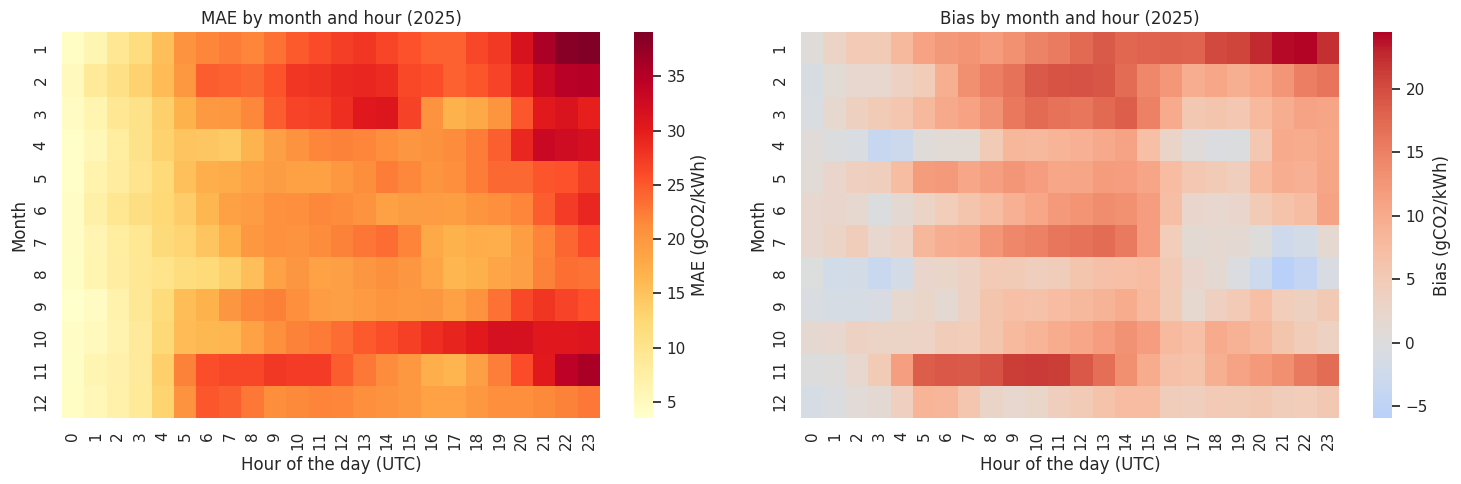

In [27]:
# Error of every half-hour: shape (361 days, 48 half-hours)
err_signed = to_np(final_P) - A_te
err_abs = np.abs(err_signed)
months = np.array(test_days.month)

#  Make hourly numbers (24 columns) and 3-hour block numbers (8 columns) 
def to_hours(M):
    return M.reshape(M.shape[0], 24, 2).mean(axis=2)    # 2 half-hours = 1 hour

def to_blocks(M):
    return M.reshape(M.shape[0], 8, 6).mean(axis=2)     # 6 half-hours = 3 hours

def month_grid(M):
    # average over the days of each month
    return pd.DataFrame([M[months == m].mean(axis=0) for m in range(1, 13)], index=range(1, 13))

mae_hour, bias_hour = month_grid(to_hours(err_abs)), month_grid(to_hours(err_signed))
mae_blk, bias_blk = month_grid(to_blocks(err_abs)), month_grid(to_blocks(err_signed))

block_names = [f"{times[6 * b]}-{times[6 * b + 5]}" for b in range(8)]
mae_blk.columns = bias_blk.columns = block_names
mae_blk.index = bias_blk.index = bias_hour.index.rename("month")

#  Tables (the same information as the picture, in text) 
print("MAE by month and 3-hour block (UTC):")
display(mae_blk.round(1))
print("Bias by month and 3-hour block (positive = model predicts too high):")
display(bias_blk.round(1))

# Hardest and easiest square
stacked = mae_blk.stack()
print(f"Hardest: month {stacked.idxmax()[0]}, {stacked.idxmax()[1]} (MAE {stacked.max():.1f})")
print(f"Easiest: month {stacked.idxmin()[0]}, {stacked.idxmin()[1]} (MAE {stacked.min():.1f})")
print("\nAverage MAE by 3-hour block over the year:", mae_blk.mean().round(1).to_dict())
print("Average MAE by season:",
      {"Winter (12,1,2)": round(float(mae_blk.loc[[12, 1, 2]].values.mean()), 1),
       "Spring (3,4,5)": round(float(mae_blk.loc[[3, 4, 5]].values.mean()), 1),
       "Summer (6,7,8)": round(float(mae_blk.loc[[6, 7, 8]].values.mean()), 1),
       "Autumn (9,10,11)": round(float(mae_blk.loc[[9, 10, 11]].values.mean()), 1)})

#  Pictures (hourly columns, so the picture has more detail) 
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(mae_hour, cmap="YlOrRd", ax=axes[0], cbar_kws={"label": f"MAE ({UNIT})"})
axes[0].set(xlabel="Hour of the day (UTC)", ylabel="Month", title="MAE by month and hour (2025)")
sns.heatmap(bias_hour, cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"label": f"Bias ({UNIT})"})
axes[1].set(xlabel="Hour of the day (UTC)", ylabel="Month", title="Bias by month and hour (2025)")
plt.tight_layout()
plt.show()

**Observation.** In every month the error grows during the day: the average MAE is 6.2 for 00:00-02:30 and 29.0 for 21:00-23:30. The hardest part is January 21:00-23:30 (MAE 37.8) and the easiest is September 00:00-02:30 (MAE 5.0). By season the average MAE is 22.0 in winter, 19.7 in spring, 17.3 in summer and 20.4 in autumn. The model over-predicts mostly around midday and in winter (for example January 15:00-20:30: +18 to +21), and the bias is close to zero at night. We did not test the reasons for this pattern.

## Step 16d: Permutation importance (which feature groups matter most?)

Idea: if a group of features is important, mixing up (shuffling) its values between days should make the predictions worse.
We shuffle one feature group at a time (all columns of the group together) and see how much the MAE goes up.
A bigger increase means a more important group. We repeat the shuffle 5 times and take the average.

We use the ensemble trained on 2022-2023 and the 2024 validation days, so the test data is not used.

MAE with no shuffling: 20.59  (it should be 20.59, the same as in the validation table)

Permutation importance (validation 2024, ensemble):


,feature group,number of features,MAE after shuffling,std,MAE increase,increase (%)
0,wx_tgt,48,38.06,0.48,17.46,84.80
1,ci_lag1d,48,30.12,0.65,9.52,46.25
2,ci_prev,4,27.29,0.28,6.70,32.53
3,calendar,6,24.61,0.31,4.02,19.53
4,wx_prev,12,23.27,0.35,2.67,12.98
5,ci_avg7d,48,22.48,0.18,1.88,9.15
6,gen_prev,8,22.09,0.07,1.50,7.28
7,ci_lag7d,48,20.93,0.06,0.34,1.64


Ranking of feature groups (most important first):
  1. wx_tgt: MAE goes up by 17.46 (84.8%) when shuffled
  2. ci_lag1d: MAE goes up by 9.52 (46.2%) when shuffled
  3. ci_prev: MAE goes up by 6.70 (32.5%) when shuffled
  4. calendar: MAE goes up by 4.02 (19.5%) when shuffled
  5. wx_prev: MAE goes up by 2.67 (13.0%) when shuffled
  6. ci_avg7d: MAE goes up by 1.88 (9.1%) when shuffled
  7. gen_prev: MAE goes up by 1.50 (7.3%) when shuffled
  8. ci_lag7d: MAE goes up by 0.34 (1.6%) when shuffled


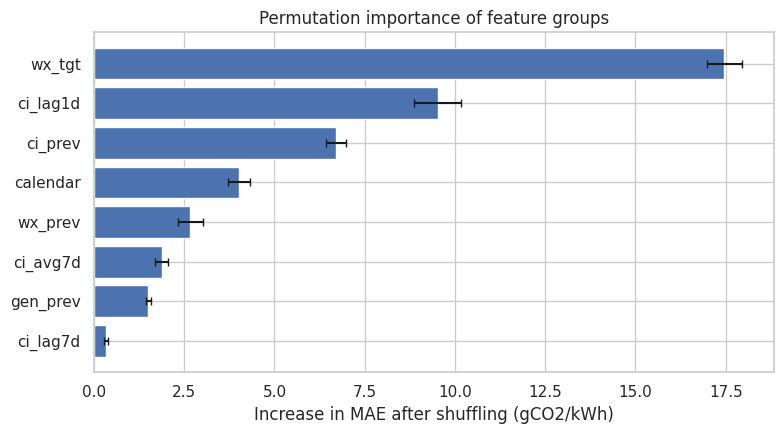

In [28]:
# Validation days (2024) and the ensemble trained on 2022-2023
X_val = X.loc[va_c, ALL].copy()
A_val = to_np(Y[va_c])

def ensemble_predict(Xrows):
    # same ensemble as before: 80% Ridge + 20% LightGBM
    p_ridge = best_ridge.predict(Xrows[ALL])
    p_lgbm = best_lgbm.predict(make_long_from(Xrows)).reshape(-1, HORIZON)
    return 0.8 * p_ridge + 0.2 * p_lgbm

base_mae = np.abs(ensemble_predict(X_val) - A_val).mean()
print(f"MAE with no shuffling: {base_mae:.2f}  (it should be 20.59, the same as in the validation table)")

#  Shuffle one group at a time 
rng = np.random.default_rng(SEED)
rows = []
for g in groups.unique():
    cols = [c for c in ALL if groups[c] == g]
    maes = []
    for rep in range(5):
        Xp = X_val.copy()
        order_rows = rng.permutation(len(Xp))                  # a random new order of the days
        Xp[cols] = X_val[cols].to_numpy()[order_rows]          # all columns of the group move together
        maes.append(np.abs(ensemble_predict(Xp) - A_val).mean())
    rows.append({"feature group": g, "number of features": len(cols),
                 "MAE after shuffling": np.mean(maes), "std": np.std(maes),
                 "MAE increase": np.mean(maes) - base_mae})

perm = pd.DataFrame(rows).sort_values("MAE increase", ascending=False).reset_index(drop=True)
perm["increase (%)"] = 100 * perm["MAE increase"] / base_mae
print("\nPermutation importance (validation 2024, ensemble):")
display(perm.round(2))

#  Text summary 
print("Ranking of feature groups (most important first):")
for i, r in perm.iterrows():
    print(f"  {i + 1}. {r['feature group']}: MAE goes up by {r['MAE increase']:.2f} ({r['increase (%)']:.1f}%) when shuffled")

#  Picture 
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = perm.sort_values("MAE increase")
ax.barh(plot_df["feature group"], plot_df["MAE increase"], xerr=plot_df["std"], capsize=3)
ax.set(xlabel=f"Increase in MAE after shuffling ({UNIT})", title="Permutation importance of feature groups")
plt.tight_layout()
plt.show()

**Observation.** Permutation importance (2024 validation, ensemble): shuffling the target-day weather (wx_tgt) raises the MAE the most (+17.46, 85%), followed by yesterday's carbon intensity (ci_lag1d, +9.52), the summary numbers of yesterday (ci_prev, +6.70, only 4 features), the calendar features (+4.02), yesterday's weather (+2.67), the 7-day average (+1.88) and the fuel mix (+1.50). The same time last week (ci_lag7d) is almost useless (+0.34). This agrees with the ablation. Note: some groups carry similar information, so one group may partly replace another.

## Step 17: Save the final model and build the predict(date) function

We save the final model (Ridge + LightGBM ensemble) with joblib.
Then we write predict(date): for a chosen date it gives 48 half-hourly predictions and recommends the best 3-hour window.
The model only uses data up to 23:30 UTC of the day before, plus the weather of the target day.
All times are in UTC (in British Summer Time, UK local time is UTC + 1 hour).
Dates in 2025 are a fair test. Dates in 2022-2024 were used for training.

Model saved. File size (MB): 0.97
Saved model matches the test predictions: True
Date: 2025-08-01
Recommended 3-hour window: 11:30 to 14:30 (UTC)
  Predicted average in the window: 77.4 gCO2/kWh
  Predicted average of an average window: 96.0 gCO2/kWh
  Actual average in the chosen window: 69.2 gCO2/kWh
  Truly best window was 13:30 to 16:30 with 65.2 gCO2/kWh
  Regret: 4.0 | Day MAE: 17.9


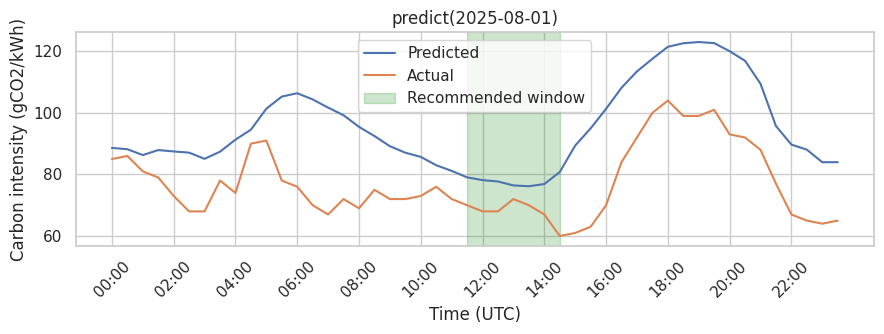


Date: 2025-11-23
Recommended 3-hour window: 01:30 to 04:30 (UTC)
  Predicted average in the window: 83.6 gCO2/kWh
  Predicted average of an average window: 138.4 gCO2/kWh
  Actual average in the chosen window: 68.7 gCO2/kWh
  Truly best window was 08:30 to 11:30 with 44.3 gCO2/kWh
  Regret: 24.3 | Day MAE: 65.0


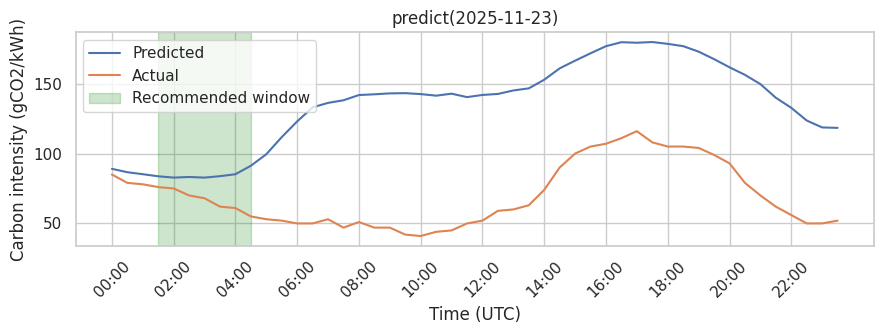


Date: 2025-02-12
Recommended 3-hour window: 00:30 to 03:30 (UTC)
  Predicted average in the window: 131.9 gCO2/kWh
  Predicted average of an average window: 193.1 gCO2/kWh
  Actual average in the chosen window: 128.8 gCO2/kWh
  Truly best window was 00:30 to 03:30 with 128.8 gCO2/kWh
  Regret: 0.0 | Day MAE: 7.2

Files in /kaggle/working:
  __notebook__.ipynb
  figures
  final_model.joblib
  previous_day1_2025.csv
  results_robustness.csv
  results_rq2_per_slot.csv
  results_rq3.csv
  results_test_2025.csv
  results_window_rq4.csv


In [29]:
import joblib

#  1. Save the final model 
final_package = {
    "ridge": final_ridge, "lightgbm": final_lgbm,
    "ridge_share": 0.8, "lgbm_share": 0.2,
    "all_features": ALL, "day_cols": DAY_COLS, "step_cols": STEP_COLS,
}
joblib.dump(final_package, "/kaggle/working/final_model.joblib")
loaded = joblib.load("/kaggle/working/final_model.joblib")
print("Model saved. File size (MB):", round(os.path.getsize("/kaggle/working/final_model.joblib") / 1e6, 2))

#  2. A function that uses the saved model 
def predict_from_package(pkg, X_rows):
    p_ridge = pkg["ridge"].predict(X_rows[pkg["all_features"]])
    n = len(X_rows)
    Xl = pd.DataFrame(np.repeat(X_rows[pkg["day_cols"]].to_numpy(), HORIZON, axis=0), columns=pkg["day_cols"])
    Xl["step"] = np.tile(np.arange(HORIZON), n)
    for prefix, new_name in pkg["step_cols"].items():
        Xl[new_name] = X_rows[[f"{prefix}{s}" for s in range(HORIZON)]].to_numpy().reshape(-1)
    p_lgbm = pkg["lightgbm"].predict(Xl).reshape(-1, HORIZON)
    return pkg["ridge_share"] * p_ridge + pkg["lgbm_share"] * p_lgbm

# Check: the saved model gives the same answers as before
P_check = predict_from_package(loaded, X.loc[te_c, ALL + [c for c in X.columns if c not in ALL]])
print("Saved model matches the test predictions:", bool(np.allclose(P_check, PRED_TE[FINAL_NAME])))

#  3. predict(date) 
def predict(date, use_forecast_weather=False, show_plot=True):
    day = pd.Timestamp(date, tz="UTC").normalize()
    if day not in X.index:
        print("This date is not in the data (we have 2022-01-01 to 2025-12-31).")
        return None
    source = X_fc if use_forecast_weather else X          # X_fc = 2025 forecast weather
    row = source.loc[[day]]
    if row.isna().any(axis=1).iloc[0]:
        print("Some input data is missing for this date, so we cannot predict it.")
        return None

    pred = predict_from_package(loaded, row)[0]
    out = pd.DataFrame({"time (UTC)": times, "predicted": pred})
    has_actual = not Y.loc[day].isna().any()
    if has_actual:
        out["actual"] = Y.loc[day].to_numpy()

    # Best 3-hour window = the 6 half-hours with the lowest average predicted value
    win_means = np.array([pred[s:s + WINDOW].mean() for s in range(N_WIN)])
    b = int(win_means.argmin())
    end = times[b + WINDOW] if b + WINDOW < HORIZON else "24:00"

    print(f"Date: {day.date()}")
    if day.year <= 2024:
        print("WARNING: the model was trained on this date, so this is not a fair test.")
    print(f"Recommended 3-hour window: {times[b]} to {end} (UTC)")
    print(f"  Predicted average in the window: {win_means[b]:.1f} {UNIT}")
    print(f"  Predicted average of an average window: {win_means.mean():.1f} {UNIT}")
    if has_actual:
        act = out["actual"].to_numpy()
        act_win = np.array([act[s:s + WINDOW].mean() for s in range(N_WIN)])
        ab = int(act_win.argmin())
        a_end = times[ab + WINDOW] if ab + WINDOW < HORIZON else "24:00"
        print(f"  Actual average in the chosen window: {act_win[b]:.1f} {UNIT}")
        print(f"  Truly best window was {times[ab]} to {a_end} with {act_win[ab]:.1f} {UNIT}")
        print(f"  Regret: {act_win[b] - act_win[ab]:.1f} | Day MAE: {np.abs(pred - act).mean():.1f}")

    if show_plot:
        fig, ax = plt.subplots(figsize=(9, 3.5))
        ax.plot(pred, label="Predicted")
        if has_actual:
            ax.plot(out["actual"].to_numpy(), label="Actual")
        ax.axvspan(b, b + WINDOW, alpha=0.2, color="green", label="Recommended window")
        ax.set_xticks(range(0, HORIZON, 4)); ax.set_xticklabels(times[::4], rotation=45)
        ax.set(xlabel="Time (UTC)", ylabel=f"Carbon intensity ({UNIT})", title=f"predict({day.date()})")
        ax.legend()
        plt.tight_layout()
        plt.show()
    return out

#  4. Try it 
_ = predict("2025-08-01")
print()
_ = predict("2025-11-23")
print()
_ = predict("2025-02-12", use_forecast_weather=True, show_plot=False)

#  5. Save the result tables (for GitHub) 
test_tbl.to_csv("/kaggle/working/results_test_2025.csv", index=False)
win_tbl.to_csv("/kaggle/working/results_window_rq4.csv", index=False)
rq3_tbl.to_csv("/kaggle/working/results_rq3.csv", index=False)
robust_tbl.to_csv("/kaggle/working/results_robustness.csv", index=False)
slot_ci.to_csv("/kaggle/working/results_rq2_per_slot.csv")
print("\nFiles in /kaggle/working:")
for f in sorted(os.listdir("/kaggle/working")):
    print(" ", f)

**Observation.** The final model (Ridge + LightGBM) is saved in one small file (0.97 MB). Loading it gives exactly the same test predictions as before. The function predict(date) returns 48 forecasts and the best 3-hour window. Examples: on 2025-02-12 it chose exactly the best window (regret 0.0); on 2025-08-01 it chose 11:30-14:30 while the best was 13:30-16:30 (regret 4.0); on 2025-11-23, the hardest day, it chose 01:30-04:30 while the best was 08:30-11:30 (regret 24.3). So the recommendation is good on average but not on every day.

## Step 17b: Prediction intervals (a range, not only one number)

A single predicted number does not tell us how sure the model is. Here we build a range for each half-hour.

Method (simple and honest):
1. On the 2024 validation days we look at the mistakes of the model: actual minus predicted, for each of the 48 half-hours.
2. For each half-hour we take the 10th and 90th percentile of these mistakes (for an 80% range), and the 25th and 75th percentile (for a 50% range).
3. For a new day, the range = prediction + these mistake limits.

Then we check on the 2025 test days how often the real value was really inside the range (this is called coverage).
A good 80% range should cover about 80% of the real values. The 2025 data was not used to build the ranges.

Coverage of the ranges on the 2025 test days (80% range should be near 80, 50% range near 50):


,range,coverage on 2025 (%),average width,"coverage, first 3 hours (%)","coverage, last 3 hours (%)"
0,80% range,81.0,61.2,85.9,76.4
1,50% range,50.4,31.2,58.0,44.8


80% range by 3-hour block of the day:


,time block,coverage 80% range (%),average width
0,00:00-02:30,85.9,23.0
1,03:00-05:30,83.7,45.0
2,06:00-08:30,81.4,59.6
3,09:00-11:30,80.1,64.1
4,12:00-14:30,81.5,66.5
5,15:00-17:30,80.1,67.0
6,18:00-20:30,79.3,75.3
7,21:00-23:30,76.4,88.9


Real value BELOW the 80% range: 8.0% (ideal: 10%)
Real value ABOVE the 80% range: 10.9% (ideal: 10%)


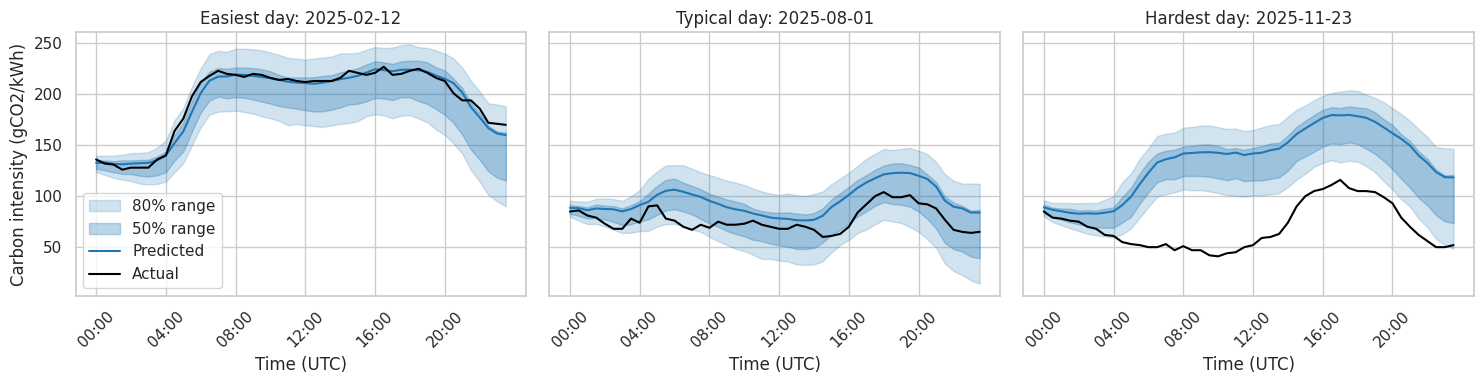

Easiest day (2025-02-12): 100% of the 48 real values are inside the 80% range
Typical day (2025-08-01): 96% of the 48 real values are inside the 80% range
Hardest day (2025-11-23): 21% of the 48 real values are inside the 80% range


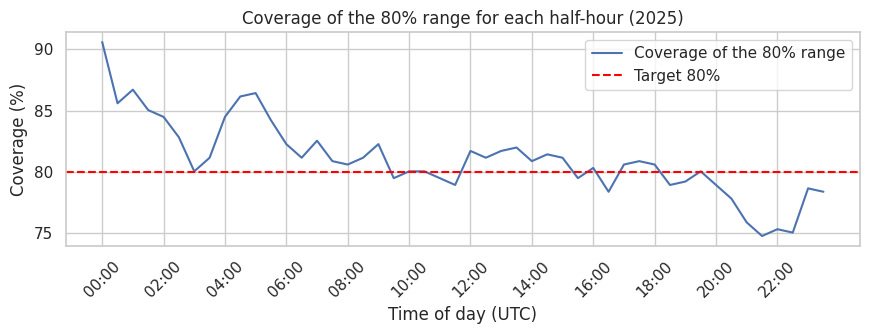

In [30]:
#  Step 1: mistakes on the validation days (2024) 
A_va = to_np(Y[va_c])
P_va_final = 0.8 * P_ridge_va + 0.2 * P_lgbm_va      # validation predictions of the ensemble
res_val = A_va - P_va_final                           # actual - predicted (shape: 357 days x 48 half-hours)

#  Step 2: percentiles of the mistakes for each half-hour 
LEVELS = {"80% range": (10, 90), "50% range": (25, 75)}
offsets = {}
for name, (p_lo, p_hi) in LEVELS.items():
    offsets[name] = (np.percentile(res_val, p_lo, axis=0), np.percentile(res_val, p_hi, axis=0))

# Save the offsets in a file (we can use them later in predict)
off_df = pd.DataFrame({"time (UTC)": times,
                       "p10": offsets["80% range"][0], "p90": offsets["80% range"][1],
                       "p25": offsets["50% range"][0], "p75": offsets["50% range"][1]})
off_df.to_csv("/kaggle/working/interval_offsets.csv", index=False)

#  Step 3: ranges for the 2025 test days and coverage 
P_test = to_np(final_P)
blocks = [f"{times[6 * b]}-{times[6 * b + 5]}" for b in range(8)]
rows = []
band = {}
for name, (lo_off, hi_off) in offsets.items():
    lo = np.maximum(P_test + lo_off, 0)               # carbon intensity cannot be below 0
    hi = P_test + hi_off
    band[name] = (lo, hi)
    inside = (A_te >= lo) & (A_te <= hi)              # True when the real value is inside the range
    rows.append({"range": name, "coverage on 2025 (%)": 100 * inside.mean(),
                 "average width": (hi - lo).mean(),
                 "coverage, first 3 hours (%)": 100 * inside[:, :6].mean(),
                 "coverage, last 3 hours (%)": 100 * inside[:, -6:].mean()})
cover_tbl = pd.DataFrame(rows)
print("Coverage of the ranges on the 2025 test days (80% range should be near 80, 50% range near 50):")
display(cover_tbl.round(1))

#  Coverage and width for each 3-hour block 
lo80, hi80 = band["80% range"]
inside80 = (A_te >= lo80) & (A_te <= hi80)
blk = pd.DataFrame({"time block": blocks,
                    "coverage 80% range (%)": [100 * inside80[:, 6 * b:6 * b + 6].mean() for b in range(8)],
                    "average width": [(hi80 - lo80)[:, 6 * b:6 * b + 6].mean() for b in range(8)]})
print("80% range by 3-hour block of the day:")
display(blk.round(1))

#  Coverage below and above 
print(f"Real value BELOW the 80% range: {100 * (A_te < lo80).mean():.1f}% (ideal: 10%)")
print(f"Real value ABOVE the 80% range: {100 * (A_te > hi80).mean():.1f}% (ideal: 10%)")

#  Three sample days (same days as before) 
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, i) in zip(axes, pick_days.items()):
    x = np.arange(HORIZON)
    ax.fill_between(x, band["80% range"][0][i], band["80% range"][1][i], alpha=0.2, color="tab:blue", label="80% range")
    ax.fill_between(x, band["50% range"][0][i], band["50% range"][1][i], alpha=0.3, color="tab:blue", label="50% range")
    ax.plot(x, P_test[i], color="tab:blue", label="Predicted")
    ax.plot(x, A_te[i], color="black", label="Actual")
    ax.set_title(f"{title}: {test_days[i].date()}")
    ax.set_xticks(range(0, HORIZON, 8)); ax.set_xticklabels(times[::8], rotation=45)
    ax.set_xlabel("Time (UTC)")
axes[0].set_ylabel(f"Carbon intensity ({UNIT})")
axes[0].legend()
plt.tight_layout()
plt.show()

for title, i in pick_days.items():
    inside_day = ((A_te[i] >= lo80[i]) & (A_te[i] <= hi80[i])).mean()
    print(f"{title} ({test_days[i].date()}): {100 * inside_day:.0f}% of the 48 real values are inside the 80% range")

#  Coverage over the 48 half-hours 
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(100 * inside80.mean(axis=0), label="Coverage of the 80% range")
ax.axhline(80, color="red", linestyle="--", label="Target 80%")
ax.set_xticks(range(0, HORIZON, 4)); ax.set_xticklabels(times[::4], rotation=45)
ax.set(xlabel="Time of day (UTC)", ylabel="Coverage (%)", title="Coverage of the 80% range for each half-hour (2025)")
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** The prediction ranges were built from the 2024 mistakes only. On the 2025 test days the 80% range contains 81.0% of the real values and the 50% range 50.4%, so they are well calibrated. The ranges are wider later in the day (average width 23.0 at 00:00-02:30 and 88.9 at 21:00-23:30), and the coverage of the 80% range is a little low at the end of the day (76.4%). The ranges have the same width on every day, so they do not adapt to difficult days: on the hardest day only 21% of the real values were inside the 80% range (easy day 100%, typical day 96%). A better method could make the range wider on windy or unusual days.

## Step 17c: Live forecast for today (bonus) - Part A: download the latest data

Until now predict(date) worked only for dates inside our saved data (2022-2025).
Here we connect the model to the real world: we download the latest data from the two APIs
and (in the next cell) forecast the carbon intensity of TODAY (UTC).
The model needs the last 8 days of carbon intensity, yesterday's electricity mix and weather, and today's weather forecast.

In [31]:
LIVE_OK = False
try:
    #  Settings 
    CI_API = "https://api.carbonintensity.org.uk"
    WX_API = "https://api.open-meteo.com/v1/forecast"          # live weather forecast
    NOW = pd.Timestamp.now(tz="UTC")
    TARGET = NOW.normalize()                                    # the day we want to predict = today (UTC)
    HISTORY_DAYS = 10                                           # how many past days we download
    START = TARGET - pd.Timedelta(days=HISTORY_DAYS)
    END = TARGET + pd.Timedelta(hours=23, minutes=30)           # last half-hour of today
    END_PAST = min(END, NOW.floor("30min"))                     # we cannot download the future
    print("Now (UTC):", NOW.strftime("%Y-%m-%d %H:%M"))
    print("Target day:", TARGET.date())
    
    def api_get(url, params=None, tries=4):
        # ask the API; if it fails, wait and try again
        for i in range(tries):
            try:
                r = requests.get(url, params=params, timeout=90)
                r.raise_for_status()
                return r.json()
            except Exception as e:
                if i == tries - 1:
                    print("FAILED:", url, e)
                    raise
                time.sleep(2 * (i + 1))
    
    def fmt(t):
        # the time format the Carbon Intensity API wants
        return t.strftime("%Y-%m-%dT%H:%MZ")
    
    #  1. Carbon intensity (actual values) 
    j = api_get(f"{CI_API}/intensity/{fmt(START)}/{fmt(END_PAST)}")
    ci_live = pd.DataFrame([{"time": d["from"],
                             "forecast_neso": (d.get("intensity") or {}).get("forecast"),
                             "actual": (d.get("intensity") or {}).get("actual")} for d in j["data"]])
    ci_live["time"] = pd.to_datetime(ci_live["time"], utc=True)
    ci_live = ci_live.drop_duplicates("time").set_index("time")
    print("\nCarbon intensity rows:", len(ci_live), "| from", ci_live.index.min(), "to", ci_live.index.max())
    
    #  2. Electricity mix (only up to the end of yesterday) 
    g = api_get(f"{CI_API}/generation/{fmt(START)}/{fmt(TARGET - pd.Timedelta(minutes=30))}")
    rows = []
    for d in g["data"]:
        row = {"time": d["from"]}
        for m in d.get("generationmix") or []:
            row[m["fuel"]] = m["perc"]               # fuel name -> percent
        rows.append(row)
    gen_live = pd.DataFrame(rows)
    gen_live["time"] = pd.to_datetime(gen_live["time"], utc=True)
    gen_live = gen_live.drop_duplicates("time").set_index("time")
    print("Electricity mix rows:", len(gen_live), "| fuels:", list(gen_live.columns))
    
    #  3. Weather (past days + today's forecast) for the 3 places 
    frames = []
    for loc, (lat, lon) in PLACES.items():
        params = {"latitude": lat, "longitude": lon, "hourly": ",".join(MODEL_WX),
                  "past_days": HISTORY_DAYS, "forecast_days": 3, "timezone": "UTC"}
        w = api_get(WX_API, params)
        d = pd.DataFrame(w["hourly"])
        d["time"] = pd.to_datetime(d["time"], utc=True)
        d = d.set_index("time")
        d.columns = [f"{c}_{loc}" for c in d.columns]      # same column names as in our data
        frames.append(d)
    wx_live = pd.concat(frames, axis=1)
    print("Weather rows:", len(wx_live), "| from", wx_live.index.min(), "to", wx_live.index.max())
    
    #  4. Put everything on one 30-minute table (same layout as master_clean) 
    GRID = pd.date_range(START, END, freq="30min")
    df_live = pd.DataFrame(index=GRID)
    df_live["actual"] = ci_live["actual"].reindex(GRID)
    df_live["forecast_neso"] = ci_live["forecast_neso"].reindex(GRID)
    for f in FUELS:
        df_live[f] = gen_live[f].reindex(GRID) if f in gen_live.columns else np.nan
    for c in wcols:
        df_live[c] = wx_live[c].reindex(GRID, method="ffill")   # hourly value is used for both half-hours
    print("\nLive table shape:", df_live.shape)
    
    #  Checks 
    days = df_live.index.floor("D")
    miss = df_live["actual"].isna().groupby(days).sum().rename("missing actual values (of 48)")
    print("\nMissing carbon intensity values per day (today is not finished, so it has missing values):")
    display(miss.to_frame())
    
    print("Missing values in electricity mix (past days):", int(df_live.loc[df_live.index < TARGET, FUELS].isna().sum().sum()))
    print("Missing values in weather:", int(df_live[wcols].isna().sum().sum()))
    
    # Compare the live data with our old data (to catch unit problems)
    cmp_rows = []
    for c in ["actual"] + FUELS + [f"{v}_london" for v in MODEL_WX]:
        cmp_rows.append({"column": c, "live mean": df_live[c].mean(), "old data mean (2025)": df.loc["2025", c].mean()})
    display(pd.DataFrame(cmp_rows).round(1))
    
    print("Carbon intensity today so far:", int(df_live.loc[df_live.index >= TARGET, "actual"].notna().sum()), "half-hours")

    LIVE_OK = True
except Exception as e:
    print("Live data could not be downloaded, so the live forecast is skipped. Reason:", e)

Now (UTC): 2026-11-21 10:40
Target day: 2026-11-21

Carbon intensity rows: 502 | from 2026-11-10 23:30:00+00:00 to 2026-11-21 10:00:00+00:00
Electricity mix rows: 480 | fuels: ['biomass', 'coal', 'imports', 'gas', 'nuclear', 'other', 'hydro', 'solar', 'wind']
Weather rows: 312 | from 2026-11-11 00:00:00+00:00 to 2026-11-23 23:00:00+00:00

Live table shape: (528, 22)

Missing carbon intensity values per day (today is not finished, so it has missing values):


,missing actual values (of 48)
2026-11-11 00:00:00+00:00,0
2026-11-12 00:00:00+00:00,0
2026-11-13 00:00:00+00:00,0
2026-11-14 00:00:00+00:00,0
2026-11-15 00:00:00+00:00,0
2026-11-16 00:00:00+00:00,0
2026-11-17 00:00:00+00:00,0
2026-11-18 00:00:00+00:00,0
2026-11-19 00:00:00+00:00,0
2026-11-20 00:00:00+00:00,0


Missing values in electricity mix (past days): 8
Missing values in weather: 0


,column,live mean,old data mean (2025)
0,actual,154.8,129.2
1,biomass,6.8,7.6
2,coal,0.0,0.0
3,imports,14.7,12.5
4,gas,30.8,28.2
5,nuclear,14.3,13.3
6,hydro,1.3,0.0
7,solar,2.2,6.3
8,wind,27.8,32.1
9,wind_speed_10m_london,9.0,11.6


Carbon intensity today so far: 20 half-hours


**Observation.** This cell downloads the latest data from the two APIs: carbon intensity for the last 10 days, the electricity mix up to yesterday, and the weather (past days and today's forecast) for the 3 places. The checks show how many values are missing and compare the live averages with our 2025 data, to catch problems with units. The live data has the same layout as our training data, so the same feature code can be used.

## Step 17d: Live forecast for today (bonus) - Part B: features, forecast, range and best window

We build the features for today from the live table, use the saved final model to forecast the 48 half-hours,
and add the 80% and 50% ranges from Step 17b.
Today is not finished, so we can already compare the forecast with the real values that exist so far
and with NESO's own forecast. We also recommend the best 3-hour window for the time that is still left today.

Features: 222 | missing values in today's row: 0
Today is a holiday: False | day of week (0=Monday): 5
Features outside the training range: 0 of 222

Forecast for 2026-11-21 (all times in UTC)
Best 3-hour window of the whole day: 21:00 to 24:00 | predicted average 197.4 gCO2/kWh
Predicted average of an average window: 217.0 gCO2/kWh
Best 3-hour window from now on: 21:00 to 24:00 | predicted average 197.4 gCO2/kWh

Forecast every 3 hours:


,predicted,80% low,80% high,actual so far,NESO forecast,yesterday
time (UTC),,,,,,
00:00,209.0,200.0,216.0,215.0,225.0,166.0
03:00,199.0,178.0,209.0,207.0,212.0,162.0
06:00,219.0,185.0,243.0,212.0,221.0,205.0
09:00,219.0,182.0,245.0,208.0,223.0,212.0
12:00,213.0,172.0,236.0,NaN,203.0,204.0
15:00,233.0,189.0,256.0,NaN,228.0,219.0
18:00,232.0,187.0,257.0,NaN,226.0,229.0
21:00,215.0,155.0,239.0,NaN,205.0,222.0


Real values available so far: 20 half-hours


,method,half-hours compared,MAE so far,bias
0,Our model,20,6.09,-0.69
1,NESO forecast,20,7.55,7.45
2,Yesterday,20,25.20,-22.20
3,7-day average,20,79.84,-79.84


Real values inside our 80% range so far: 95%


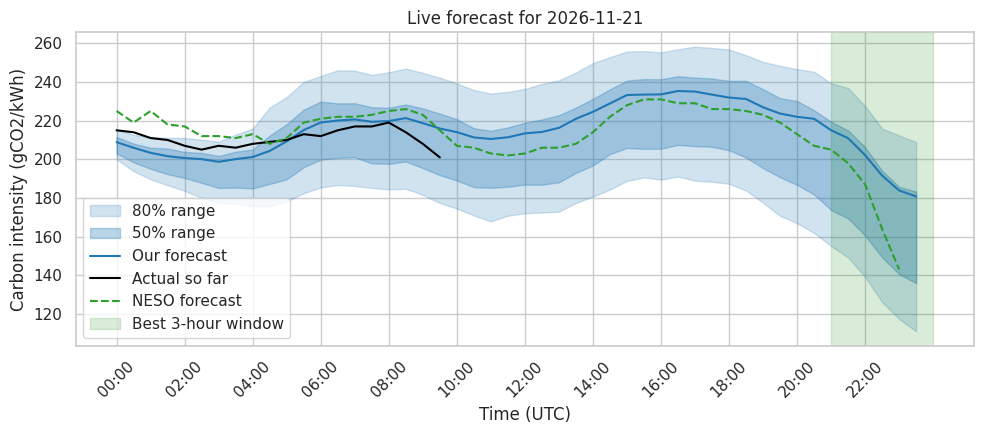

Saved: live_forecast_2026-11-21.csv


In [32]:
try:
    assert LIVE_OK, "Live data is not available, so this step is skipped."
    #  Step 1: build the features for today 
    UK_HOLIDAYS = holidays.UK(subdiv="England", years=range(2022, 2028))   # add 2026 holidays (the old list ended in 2025)
    X_live_all = build_features(df_live)
    row = X_live_all.loc[[TARGET], ALL]                                      # today's row, same columns as in training
    
    n_missing = int(row.isna().sum(axis=1).iloc[0])
    print("Features:", row.shape[1], "| missing values in today's row:", n_missing)
    assert n_missing == 0, "Some features are missing. Look at: " + str(list(row.columns[row.isna().iloc[0]]))
    print("Today is a holiday:", bool(row["is_holiday"].iloc[0]), "| day of week (0=Monday):", int(row["dow"].iloc[0]))
    
    # Check: are any features outside the range the model saw in training (2022-2024)?
    lo_tr = X.loc[train_full, ALL].min()
    hi_tr = X.loc[train_full, ALL].max()
    outside = ((row.iloc[0] < lo_tr) | (row.iloc[0] > hi_tr))
    print("Features outside the training range:", int(outside.sum()), "of", len(ALL))
    if outside.sum() > 0:
        print("  They are:", list(outside[outside].index)[:15])
    
    #  Step 2: forecast with the saved final model 
    pred = predict_from_package(loaded, row)[0]
    lo80 = np.maximum(pred + offsets["80% range"][0], 0)
    hi80 = pred + offsets["80% range"][1]
    lo50 = np.maximum(pred + offsets["50% range"][0], 0)
    hi50 = pred + offsets["50% range"][1]
    
    #  Step 3: things to compare with 
    day_idx = pd.date_range(TARGET, END, freq="30min")                 # the 48 half-hours of today
    A_all = df_live["actual"].to_numpy().reshape(-1, HORIZON)          # one row per day
    act_today = A_all[-1]                                              # real values so far (NaN = not happened yet)
    yday = A_all[-2]                                                   # yesterday
    wk7 = np.nanmean(A_all[-8:-1], axis=0)                             # average of the last 7 days
    
    neso = np.full(HORIZON, np.nan)                                    # NESO forecast for the whole day
    try:
        jf = api_get(f"{CI_API}/intensity/{fmt(TARGET)}/{fmt(END)}")
        nd = pd.DataFrame([{"time": d["from"], "f": (d.get("intensity") or {}).get("forecast")} for d in jf["data"]])
        nd["time"] = pd.to_datetime(nd["time"], utc=True)
        neso = nd.drop_duplicates("time").set_index("time")["f"].reindex(day_idx).to_numpy(dtype=float)
    except Exception as e:
        print("Could not get NESO forecast for the full day:", e)
        neso = df_live.loc[day_idx, "forecast_neso"].to_numpy(dtype=float)
    
    #  Step 4: best 3-hour window 
    win_means = np.array([pred[s:s + WINDOW].mean() for s in range(N_WIN)])
    b_all = int(win_means.argmin())
    end_all = times[b_all + WINDOW] if b_all + WINDOW < HORIZON else "24:00"
    print(f"\nForecast for {TARGET.date()} (all times in UTC)")
    print(f"Best 3-hour window of the whole day: {times[b_all]} to {end_all} | predicted average {win_means[b_all]:.1f} {UNIT}")
    print(f"Predicted average of an average window: {win_means.mean():.1f} {UNIT}")
    
    first_slot = int(np.ceil((NOW - TARGET).total_seconds() / 1800))      # the next half-hour that has not started
    if first_slot <= N_WIN - 1:
        b_now = first_slot + int(win_means[first_slot:].argmin())
        end_now = times[b_now + WINDOW] if b_now + WINDOW < HORIZON else "24:00"
        print(f"Best 3-hour window from now on: {times[b_now]} to {end_now} | predicted average {win_means[b_now]:.1f} {UNIT}")
    else:
        print("Not enough time is left today for a 3-hour window.")
    
    #  Step 5: table every 3 hours 
    tbl = pd.DataFrame({"time (UTC)": times, "predicted": pred, "80% low": lo80, "80% high": hi80,
                        "actual so far": act_today, "NESO forecast": neso, "yesterday": yday})
    print("\nForecast every 3 hours:")
    display(tbl.iloc[::6].round(0).set_index("time (UTC)"))
    
    #  Step 6: how good is it so far? (only half-hours that already happened) 
    known = ~np.isnan(act_today)
    print(f"Real values available so far: {int(known.sum())} half-hours")
    if known.sum() > 0:
        rows = []
        for name, arr in {"Our model": pred, "NESO forecast": neso, "Yesterday": yday, "7-day average": wk7}.items():
            ok_ = known & ~np.isnan(arr)
            e = arr[ok_] - act_today[ok_]
            rows.append({"method": name, "half-hours compared": int(ok_.sum()), "MAE so far": np.abs(e).mean(), "bias": e.mean()})
        display(pd.DataFrame(rows).round(2))
        inside = (act_today[known] >= lo80[known]) & (act_today[known] <= hi80[known])
        print(f"Real values inside our 80% range so far: {100 * inside.mean():.0f}%")
    
    #  Picture 
    fig, ax = plt.subplots(figsize=(10, 4.5))
    x = np.arange(HORIZON)
    ax.fill_between(x, lo80, hi80, alpha=0.2, color="tab:blue", label="80% range")
    ax.fill_between(x, lo50, hi50, alpha=0.3, color="tab:blue", label="50% range")
    ax.plot(x, pred, color="tab:blue", label="Our forecast")
    ax.plot(x, act_today, color="black", label="Actual so far")
    ax.plot(x, neso, color="tab:green", linestyle="--", label="NESO forecast")
    ax.axvspan(b_all, b_all + WINDOW, alpha=0.15, color="green", label="Best 3-hour window")
    ax.set_xticks(range(0, HORIZON, 4)); ax.set_xticklabels(times[::4], rotation=45)
    ax.set(xlabel="Time (UTC)", ylabel=f"Carbon intensity ({UNIT})", title=f"Live forecast for {TARGET.date()}")
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    tbl.to_csv(f"/kaggle/working/live_forecast_{TARGET.date()}.csv", index=False)
    print("Saved: live_forecast_" + str(TARGET.date()) + ".csv")
except Exception as e:
    print("Live forecast skipped. Reason:", e)

**Observation.** This cell runs the whole pipeline on live data: it builds the 222 features for today (UTC), checks that none is missing or outside the range seen in training, and uses the saved final model to forecast the 48 half-hours with an 80% range and a recommended 3-hour window. The half-hours that already happened are compared with the real values, the NESO forecast, "Yesterday" and the 7-day average. The numbers change every time the cell is run (see the output above). In the run shown above, our forecast and the NESO forecast are both much closer to the real values than "Yesterday" and the 7-day average. This is a small sample from the first part of one day, when the model is usually more accurate than later in the day (see RQ2), so it only shows that the pipeline works; it does not show which of the two forecasts is better. The forecast is made once at 00:00 UTC and is not updated during the day, so the recommendation for late hours is less reliable.

## Step 18: Conclusion

### Final model
The final model is an **ensemble of 80% Ridge Regression and 20% LightGBM**. It was chosen because it had the lowest MAE on the 2024 validation year (20.59). It was then trained on 2022-2024 and tested once on 2025.

### Main results (2025 test, 361 days)
| Model | MAE | RMSE | Bias |
|---|---|---|---|
| Final ensemble | 19.81 | 26.14 | +7.66 |
| Ridge | 20.55 | 27.17 | +8.10 |
| LightGBM | 19.65 | 26.00 | +5.89 |
| Random Forest | 22.65 | 29.72 | +6.76 |
| Yesterday baseline | 38.87 | 50.73 | -0.15 |
| 7-day average baseline | 42.08 | 52.58 | -0.09 |
| NESO forecast (reference only) | 9.19 | 12.49 | +1.13 |

Per-slot LightGBM (48 models) got MAE 18.94 and pooled LightGBM got 19.65, slightly better than the ensemble on the test set.
We did not change our final model after seeing the test results, because the model was chosen on validation data. The differences are small.

### Answers to the research questions
- **RQ1:** Yes. The final MAE is 19.81 (95% CI 18.74 to 20.84). The target was 31.09 (20% better than the best simple baseline). The model is about 49% better than the Yesterday baseline.
- **RQ2:** The error grows with the forecast time. MAE is 3.65 at 00:00 and 29.69 at 23:30. The Yesterday baseline stays between 35 and 42 all day.
- **RQ3:** Using one-day-ahead forecast weather instead of historical weather did not make the model worse (MAE 19.27 vs 19.81, difference -0.54, 95% CI -1.00 to -0.06). Weather matters a lot: without target-day weather the Ridge MAE rises from 20.55 to 28.43.
- **RQ4:** The recommended 3-hour window is much better than the baselines. Average regret is 5.82 (Yesterday 21.72, 7-day average 14.36). Hit rate is 58.7% (31.0% and 44.0%). The chosen window is 38.5 gCO2/kWh lower than an average window, which is about 87% of the best possible (44.3).

### Extra results
- **Cross-validation (4 time-based folds):** the ensemble has an average MAE of 20.72, Ridge 21.22, LightGBM 22.64, Random Forest 26.61 and the Yesterday baseline 41.43, so the model ranking is not only a result of the 2024 validation year.
- **R2 and significance:** the ensemble has R2 = 0.795 on 2025 (the Yesterday baseline has 0.227). It is clearly better than Ridge and Random Forest, and not clearly different from pooled LightGBM.
- **Feature importance:** the weather of the target day is the most important feature group (permutation importance: MAE +17.46), then yesterday's carbon intensity (+9.52) and its summary numbers (+6.70).
- **Prediction ranges:** the 80% range covers 81.0% of the real 2025 values and the 50% range covers 50.4%. The ranges do not adapt to difficult days.
- **Live forecast:** the saved model can forecast today from live API data (features, range and best window).

### Limitations
- The model over-predicts by about 8 gCO2/kWh on average (positive bias). Carbon intensity went down over the years, which is a likely reason.
- Windy days are harder (MAE 21.31) than calm days (18.31). The hardest days have an MAE above 60.
- The historical weather in this project also comes from a weather-model API (Open-Meteo Historical Forecast), so it is close to the forecast data. This can explain why RQ3 shows almost no loss.
- NESO's forecast is much more accurate (MAE 9.19), but it is made with a different time horizon, so the comparison is not fair.
- All times are in UTC. We predict average carbon intensity, not the carbon intensity of the next unit of electricity.

### Possible future work
Add more recent-trend features, test other weather forecast sources, and build a small app for households and EV owners.

In [33]:
import importlib.metadata as md

#  requirements.txt 
packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "lightgbm", "joblib", "holidays", "requests"]
lines = [f"{p}=={md.version(p)}" for p in packages]
with open("/kaggle/working/requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
print("requirements.txt:")
print("\n".join(lines))

#  Pictures: pick the important ones for the README 
all_figs = sorted(os.listdir(FIG_DIR))
wanted = [("machine_learning_pipeline", "ML pipeline"),
          ("carbon_intensity_over_time", "Carbon intensity over time and the data split (drift)"),
          ("test_results_on_2025", "Test results on 2025"),
          ("rq2_mae", "RQ2: error for each of the 48 half-hours"),
          ("rq3_", "RQ3: historical vs forecast weather"),
          ("regret", "RQ4: window regret and hit rate"),
          ("predicted_vs_actual_every", "Predicted vs actual"),
          ("permutation_importance", "Permutation importance"),
          ("live_forecast", "Live forecast")]
fig_lines = []
for key, caption in wanted:
    found = [f for f in all_figs if key in f]
    if found:
        fig_lines.append(f"### {caption}\n![{caption}](figures/{found[0]})\n")
fig_text = "\n".join(fig_lines)
print("\nPictures added to the README:", len(fig_lines), "of", len(wanted))

#  README.md 
readme = """# Carbon-Aware Scheduling: 24-Hour Forecasting of Half-Hourly Grid Carbon Intensity

Course project: Data Science Tools and Techniques (MSDS).
Team: Zahra Qaisar (26L-8024) and Kainat Bashir (26L-8026).

## What this project does
The model predicts the carbon intensity of the Great Britain electricity grid for the next 24 hours
(48 half-hourly values) and recommends the cleanest 3-hour window of the day.
It uses data up to 23:30 UTC of the previous day (past carbon intensity, fuel mix, weather and calendar)
plus the weather of the target day.

- Part 1: data collection, cleaning, features and baselines (notebooks/part-1.ipynb)
- Part 2: models, tuning, optimization, evaluation, RQ1-RQ4, final model and predict(date) (notebooks/part-2.ipynb)

## Method in short
- Time-based split: train 2022-2023, validate 2024, then refit on 2022-2024 and test once on 2025.
- Baselines: same time yesterday, average of the last 7 days (NESO's own forecast is shown only as a reference).
- Models: Ridge, Random Forest, LightGBM (one pooled model and a per-slot test), and an ensemble.
- Tuning on the validation year, time-series cross-validation, ablation of feature groups, learning curves.
- Final model: ensemble of 80% Ridge and 20% LightGBM, chosen on validation data only.

## Main results (test year 2025, 361 days)
| Model | MAE (gCO2/kWh) |
|---|---|
| Final ensemble (80% Ridge + 20% LightGBM) | 19.81 |
| Ridge | 20.55 |
| LightGBM | 19.65 |
| Random Forest | 22.65 |
| Yesterday baseline | 38.87 |
| 7-day average baseline | 42.08 |
| NESO forecast (reference only, different horizon) | 9.19 |

- RQ1: the final model is about 49% better than the best simple baseline (the target was 20%).
- RQ2: MAE grows from 3.65 (00:00) to 29.69 (23:30).
- RQ3: forecast weather instead of historical weather did not make the model worse (MAE 19.27 vs 19.81).
- RQ4: the recommended window has a regret of 5.82 (Yesterday baseline 21.72); hit rate is 58.7%.
- The 80% prediction range covers 81.0% of the real 2025 values.

## Limitations
- The model predicts too high on average (bias about +8 gCO2/kWh); carbon intensity fell over the years.
- Windy days and winter are harder; the prediction ranges do not adapt to difficult days.
- The historical weather also comes from a weather-model API, so RQ3 may underestimate the loss from real forecasts.
- All times are in UTC. We predict average carbon intensity, not the carbon intensity of the next unit of electricity.

## Repository structure
    README.md
    requirements.txt
    notebooks/   part-1.ipynb, part-2.ipynb
    data/        master_clean.csv, selected_features.csv, previous_day1_2025.csv
    models/      final_model.joblib
    results/     results_*.csv, interval_offsets.csv
    figures/     all pictures of Part 2

## How to reproduce
1. Install the packages:  pip install -r requirements.txt
2. Part 1 creates master_clean.csv and selected_features.csv (copies are in the data folder).
3. Open notebooks/part-2.ipynb and run all cells from top to bottom. If the Kaggle folder is not found,
   the notebook reads the files from the data folder. The notebook writes its outputs to /kaggle/working
   (it exists on Kaggle; on your own computer create this folder first).
4. The 2025 one-day-ahead weather forecast is read from data/previous_day1_2025.csv, or downloaded from Open-Meteo.
5. The last part of the notebook downloads the latest data and forecasts today (internet needed).
   If the download fails, this part is skipped and the rest of the notebook is not affected.
6. Forecast for one date: run predict("2025-08-01") in the notebook.

## Data sources
- Carbon Intensity API (NESO), licence CC BY 4.0: https://api.carbonintensity.org.uk
- Open-Meteo (Historical Forecast, Previous Runs and Forecast APIs), licence CC BY 4.0: https://open-meteo.com

## Notes
- Random seed: 42.
- The final model is trained on 2022-2024. Dates in 2025 are a fair test; earlier dates were used for training.

## Pictures
""" + fig_text

with open("/kaggle/working/README.md", "w") as f:
    f.write(readme)
print("\nREADME.md written.")
print("Files in /kaggle/working:")
for name in sorted(os.listdir("/kaggle/working")):
    print(" ", name)
print("Number of pictures in the figures folder:", len(os.listdir(FIG_DIR)))

requirements.txt:
numpy==2.1.3
pandas==2.3.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
lightgbm==4.6.0
joblib==1.6.0
holidays==0.107
requests==2.34.2

Pictures added to the README: 9 of 9

README.md written.
Files in /kaggle/working:
  README.md
  __notebook__.ipynb
  figures
  final_model.joblib
  interval_offsets.csv
  live_forecast_2026-11-21.csv
  previous_day1_2025.csv
  requirements.txt
  results_robustness.csv
  results_rq2_per_slot.csv
  results_rq3.csv
  results_test_2025.csv
  results_window_rq4.csv
Number of pictures in the figures folder: 27
